# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [ ]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "MAZKO"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [ ]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

Saving train.csv to train (1).csv
Saving weather_forecast.csv to weather_forecast (1).csv
history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [ ]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [ ]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

count    33480.000
mean       315.755
std        377.596
min          0.700
25%         94.500
50%        220.600
75%        356.200
max       3111.300
Name: y, dtype: float64
нулі: 0.0 | пропуски: 0
кроки часу != 1h: 0


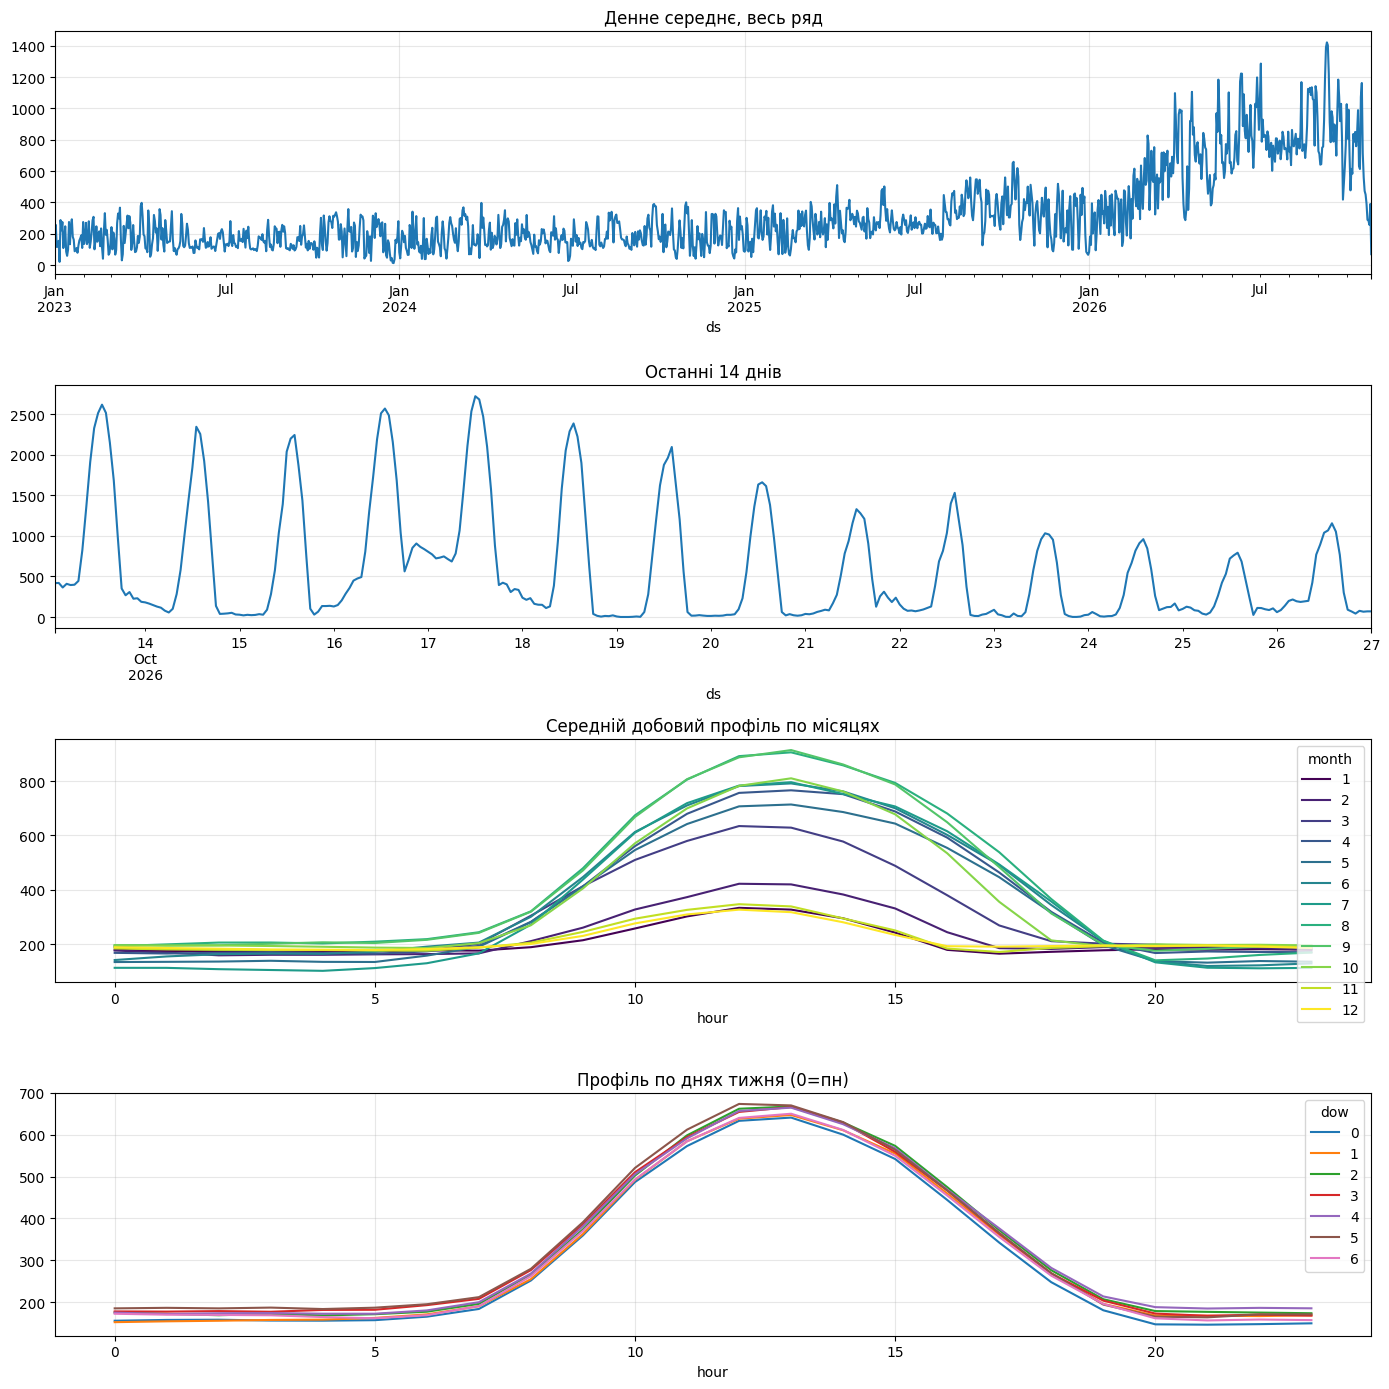

y              1.00
cloud_cover    0.16
temperature    0.28
wind_speed     0.30
pressure      -0.02
humidity      -0.38
daylight       0.39
air_density   -0.26
Name: y, dtype: float64

Жовтень-листопад:
 y              1.00
cloud_cover    0.15
temperature    0.35
wind_speed     0.28
pressure      -0.00
humidity      -0.35
daylight       0.41
air_density   -0.30
Name: y, dtype: float64


AttributeError: 'float' object has no attribute 'round'

In [ ]:
# Your work here.
import matplotlib.pyplot as plt

df = data.set_index("ds").copy()
df["hour"] = df.index.hour
df["month"] = df.index.month
df["dow"] = df.index.dayofweek

print(df["y"].describe())
print("нулі:", (df["y"] == 0).mean().round(3), "| пропуски:", df["y"].isna().sum())
print("кроки часу != 1h:", (df.index.to_series().diff().dropna() != pd.Timedelta(hours=1)).sum())

fig, ax = plt.subplots(4, 1, figsize=(14, 14))

# 1) весь ряд (денні середні)
df["y"].resample("D").mean().plot(ax=ax[0], title="Денне середнє, весь ряд")

# 2) останні 14 днів погодинно
df["y"].iloc[-24*14:].plot(ax=ax[1], title="Останні 14 днів")

# 3) добовий профіль по місяцях
df.pivot_table(index="hour", columns="month", values="y", aggfunc="mean").plot(
    ax=ax[2], title="Середній добовий профіль по місяцях", colormap="viridis")

# 4) профіль по днях тижня
df.pivot_table(index="hour", columns="dow", values="y", aggfunc="mean").plot(
    ax=ax[3], title="Профіль по днях тижня (0=пн)")

plt.tight_layout(); plt.show()

# кореляція з погодою
wcols = ["cloud_cover","temperature","wind_speed","pressure","humidity","daylight","air_density"]
print(df[["y"] + wcols].corr()["y"].round(2))

# те саме тільки для жовтня-листопада (наш сезон)
sub = df[df["month"].isin([10, 11])]
print("\nЖовтень-листопад:\n", sub[["y"] + wcols].corr()["y"].round(2))

# як схожі на горизонт погодинні значення за останні роки (27-29 жовтня)
for yr in [2023, 2024, 2025]:
    s = df.loc[f"{yr}-10-27":f"{yr}-10-29", "y"]
    print(yr, "середнє:", s.mean().round(1), "макс:", s.max().round(1))

# прогноз погоди на горизонт
print(weather_fc.describe().round(2))

### Lightgbm

In [ ]:
import lightgbm as lgb   # якщо немає: !pip install lightgbm

d = data.set_index("ds")
yarr = d["y"].to_numpy(float)
W = ["cloud_cover","temperature","wind_speed","pressure","humidity","daylight","air_density"]
Warr = d[W].to_numpy(float)
idx = d.index
n = len(d)

h = np.arange(1, 49); k = (h - 1) // 24; off = h - 24 * (k + 1)   # зсув до тієї ж години вчора

def rows(i, wx, hours):
    """i = позиція останньої відомої години (опівночі); wx = погода на 48 годин; hours = їхні мітки часу"""
    hist = yarr[:i + 1]
    lv7, lv1, pk1 = hist[-168:].mean(), hist[-24:].mean(), hist[-24:].max()
    X = np.column_stack([
        hours.hour, hours.dayofyear, k, h, wx,
        hist[-1 + off] / lv7, hist[-1 + off - 24] / lv7,
        np.full(48, lv1 / lv7), np.full(48, pk1 / lv7)])
    return X, lv7

# навчальна вибірка: кожна північ як точка "відліку", ціль - наступні 48 годин
origins = [i for i in range(200, n - 48) if idx[i].hour == 0]
Xs, Ys, Ls, Os = [], [], [], []
for i in origins:
    X, lv = rows(i, Warr[i + 1:i + 49], idx[i + 1:i + 49])
    Xs.append(X); Ys.append(yarr[i + 1:i + 49] / lv); Ls.append(np.full(48, lv)); Os.append(np.full(48, i))
X_all, Y_all, L_all, O_all = map(np.concatenate, (Xs, Ys, Ls, Os))
DAYLIGHT_COL = 4 + W.index("daylight")

def fit(mask):
    m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
                          min_child_samples=50, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, verbose=-1)
    m.fit(X_all[mask], Y_all[mask], sample_weight=L_all[mask])
    return m

# --- валідація: 3 послідовні блоки по 30 відліків (останні 90 днів), навчання лише на минулому ---
blocks = np.array_split(np.array(origins[-90:]), 3)
oof = []   # (блок, origin, y, pred, lv, k, daylight)
for b, bl in enumerate(blocks):
    m = fit(O_all < bl[0] - 48)
    te = np.isin(O_all, bl)
    p = np.clip(m.predict(X_all[te]), 0, None)
    oof.append(dict(b=np.full(te.sum(), b), o=O_all[te], y=Y_all[te] * L_all[te], p=p * L_all[te],
                    r=Y_all[te] - p, lv=L_all[te], k=X_all[te][:, 2], dl=X_all[te][:, DAYLIGHT_COL]))
oof = pd.DataFrame({c: np.concatenate([o[c] for o in oof]) for c in oof[0]})

def calib(df):
    """квантилі нормованих залишків по (доба, день/ніч)"""
    return {g: (df.loc[m.index, "r"].quantile(0.025), df.loc[m.index, "r"].quantile(0.975))
            for g, m in df.groupby(["k", "dl"])}

def interval(df, q):
    lo = np.array([q[(a, b)][0] for a, b in zip(df.k, df.dl)])
    hi = np.array([q[(a, b)][1] for a, b in zip(df.k, df.dl)])
    pred = df.p.to_numpy()
    return pred, np.clip(pred + lo * df.lv, 0, None), pred + hi * df.lv

# калібруємо на блоках 0-1, чесно тестуємо на блоці 2 і порівнюємо зі snaive на тих самих відліках
q = calib(oof[oof.b < 2])
test = oof[oof.b == 2]
pred, lo, hi = interval(test, q)
res_model = score(test.y, pred, lo, hi)

sn_pred, sn_lo, sn_hi = [], [], []
for i in sorted(test.o.unique()):
    p_, l_, u_ = snaive(yarr[:int(i) + 1]); sn_pred.append(p_); sn_lo.append(l_); sn_hi.append(u_)
res_sn = score(test.sort_values(["o", "k"]).y if False else np.concatenate([yarr[int(i)+1:int(i)+49] for i in sorted(test.o.unique())]),
               np.concatenate(sn_pred), np.concatenate(sn_lo), np.concatenate(sn_hi))

# model-ряди в тому ж порядку (за o, потім година) для чесного порівняння
results.loc["LightGBM (block 3, 30 origins)"] = res_model
results.loc["seasonal naive (block 3, 30 origins)"] = res_sn
print("skill (RMSE model / RMSE snaive):", round(res_model["RMSE"] / res_sn["RMSE"], 3))
results

skill (RMSE model / RMSE snaive): 0.885


,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
"LightGBM (block 3, 30 origins)",324.199,592.441,1983.699,0.794
"seasonal naive (block 3, 30 origins)",366.348,540.980,3029.563,0.742


In [ ]:
# фінальна модель на всій історії
m_final = fit(np.ones(len(O_all), bool))

# квантилі з усіх out-of-fold залишків
q_all = calib(oof)
WIDEN = 1.0   # якщо coverage у валідації < 0.93, постав 1.15

i0 = n - 1                                   # остання відома година: 2026-10-27 00:00
fut = pd.DatetimeIndex(FUTURE)
X_f, lv_f = rows(i0, weather_fc[W].to_numpy(float), fut)
p_f = np.clip(m_final.predict(X_f), 0, None) * lv_f

dl = X_f[:, DAYLIGHT_COL]
lo_f = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f * WIDEN
hi_f = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f * WIDEN

sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"),
                    "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_f, 0, None),
                    "upper_95": p_f + hi_f})
sub.to_csv("MAZKO_project.csv", index=False)     # заміни SURNAME на своє прізвище
print(sub.head(30).round(1))
# далі запусти check_submission з шаблону на цьому файлі

                     ds  forecast  lower_95  upper_95
0   2026-10-27 01:00:00     248.8      47.2     369.1
1   2026-10-27 02:00:00     230.4      28.8     350.7
2   2026-10-27 03:00:00     233.1      31.4     353.3
3   2026-10-27 04:00:00     176.8       0.0     297.0
4   2026-10-27 05:00:00     206.3       4.7     326.5
5   2026-10-27 06:00:00     210.7       9.1     331.0
6   2026-10-27 07:00:00     165.9       0.0     448.7
7   2026-10-27 08:00:00     191.5       0.0     474.3
8   2026-10-27 09:00:00     316.3     113.5     599.1
9   2026-10-27 10:00:00     483.9     281.1     766.7
10  2026-10-27 11:00:00     566.2     363.4     849.0
11  2026-10-27 12:00:00     750.7     547.9    1033.5
12  2026-10-27 13:00:00     748.3     545.5    1031.1
13  2026-10-27 14:00:00     766.6     563.8    1049.4
14  2026-10-27 15:00:00     637.6     434.8     920.4
15  2026-10-27 16:00:00     371.9     170.3     492.2
16  2026-10-27 17:00:00     199.6       0.0     319.8
17  2026-10-27 18:00:00     

### Another tryies

In [ ]:
import warnings; warnings.filterwarnings("ignore")
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX

O90 = [int(i) for i in origins[-90:]]
B90 = np.repeat([0, 1, 2], 30)
WI = {c: W.index(c) for c in W}

def mean3_fc(i, wx=None):
    # середнє тієї ж години за останні 3 доби (відносно проста, але з свіжим рівнем)
    return np.array([np.mean([yarr[i + 1 - 24 + (j % 24) - 24 * t] for t in range(3)]) for j in range(48)])

def ets_fc(i, wx=None):
    s = np.log1p(yarr[i - 24 * 28 + 1:i + 1])
    m = ExponentialSmoothing(s, trend="add", damped_trend=True,
                             seasonal="add", seasonal_periods=24).fit()
    return np.expm1(m.forecast(48))

def sarimax_fc(i, wx=None):
    cols = [WI["daylight"], WI["cloud_cover"], WI["wind_speed"]]
    Xh = Warr[i - 24 * 14 + 1:i + 1][:, cols]
    Xf = (Warr[i + 1:i + 49] if wx is None else wx)[:, cols]
    try:
        m = SARIMAX(np.log1p(yarr[i - 24 * 14 + 1:i + 1]), exog=Xh,
                    order=(1, 0, 0), seasonal_order=(1, 0, 0, 24),
                    enforce_stationarity=False, enforce_invertibility=False,
                    initialization="approximate_diffuse").fit(disp=False, maxiter=100)
        out = np.expm1(m.forecast(48, exog=Xf))
        if not np.all(np.isfinite(out)) or out.max() > 5 * yarr[i - 24 * 14 + 1:i + 1].max():
            raise ValueError("diverged")
        return out
    except Exception:
        return ets_fc(i)

def make_df(P):
    rows = []
    for b, o in zip(B90, O90):
        y_ = yarr[o + 1:o + 49]; lv = yarr[:o + 1][-168:].mean(); p = np.clip(P[o], 0, None)
        rows.append(pd.DataFrame(dict(b=b, o=o, y=y_, p=p, lv=lv, r=(y_ - p) / lv,
                                      k=(np.arange(48)) // 24, dl=Warr[o + 1:o + 49, WI["daylight"]])))
    return pd.concat(rows, ignore_index=True)

def evaluate(P):
    df = make_df(P)
    q = calib(df[df.b < 2])
    te = df[df.b == 2]
    pred, lo, hi = interval(te, q)
    return score(te.y, pred, lo, hi)

P = {}
P["lgbm"] = {o: oof[oof.o == o].p.to_numpy() for o in O90}      # з комірки 1
P["mean3"] = {o: mean3_fc(o) for o in O90}
P["ets"] = {o: ets_fc(o) for o in O90}
P["sarimax"] = {o: sarimax_fc(o) for o in O90}                  # може йти 1-3 хв

def ens(names): return {o: np.mean([P[n][o] for n in names], axis=0) for o in O90}
P["lgbm+ets"] = ens(["lgbm", "ets"])
P["lgbm+sarimax"] = ens(["lgbm", "sarimax"])
P["lgbm+ets+sarimax"] = ens(["lgbm", "ets", "sarimax"])
P["all4"] = ens(["lgbm", "ets", "sarimax", "mean3"])

tab = pd.DataFrame({n: evaluate(p) for n, p in P.items()}).T
tab.loc["snaive (ті самі відліки)"] = results.loc["seasonal naive (block 3, 30 origins)"]
tab["skill"] = tab["RMSE"] / tab.loc["snaive (ті самі відліки)", "RMSE"]
print(tab.round(3).sort_values("Winkler"))

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


                             RMSE     MAPE   Winkler  coverage  skill
lgbm+sarimax              457.681  419.310  1798.559     0.907  1.249
all4                      393.401  385.066  1922.041     0.892  1.074
lgbm                      324.199  592.441  1983.699     0.794  0.885
lgbm+ets                  420.231  421.657  2066.790     0.874  1.147
lgbm+ets+sarimax          483.441  365.144  2133.661     0.890  1.320
mean3                     368.160  465.185  2304.436     0.776  1.005
sarimax                   776.848  279.430  2427.500     0.908  2.121
ets                       755.793  276.175  2546.375     0.890  2.063
snaive (ті самі відліки)  366.348  540.980  3029.563     0.742  1.000


In [ ]:
def pt(Pn):
    ys = np.concatenate([yarr[o+1:o+49] for o in O90])
    ps = np.concatenate([np.clip(Pn[o], 0, None) for o in O90])
    return rmse(ys, ps), mape(ys, ps)

P["snaive"] = {o: snaive(yarr[:o+1])[0] for o in O90}
for w in [0.5, 0.7, 0.85]:
    P[f"lgbm{w}+mean3"] = {o: w*P["lgbm"][o] + (1-w)*P["mean3"][o] for o in O90}

def evaluate_w(Pn, wide=1.0):
    df = make_df(Pn); q = calib(df[df.b < 2]); te = df[df.b == 2]
    pred, lo, hi = interval(te, q)
    lo = np.clip(pred - (pred - lo) * wide, 0, None); hi = pred + (hi - pred) * wide
    return score(te.y, pred, lo, hi)

rows_ = []
for n_ in ["snaive", "lgbm", "mean3", "lgbm0.5+mean3", "lgbm0.7+mean3", "lgbm0.85+mean3"]:
    r, m = pt(P[n_])
    for wd in [1.0, 1.2, 1.4]:
        s = evaluate_w(P[n_], wd)
        rows_.append(dict(model=n_, widen=wd, RMSE90=r, MAPE90=m, **s))
print(pd.DataFrame(rows_).round(2).to_string())

             model  widen  RMSE90  MAPE90    RMSE    MAPE  Winkler  coverage
0           snaive    1.0  302.57  227.95  366.35  540.98  2427.36      0.81
1           snaive    1.2  302.57  227.95  366.35  540.98  1987.26      0.86
2           snaive    1.4  302.57  227.95  366.35  540.98  1706.60      0.91
3             lgbm    1.0  270.45  256.76  324.20  592.44  1983.70      0.79
4             lgbm    1.2  270.45  256.76  324.20  592.44  1629.98      0.88
5             lgbm    1.4  270.45  256.76  324.20  592.44  1449.14      0.93
6            mean3    1.0  303.31  201.35  368.16  465.19  2304.44      0.78
7            mean3    1.2  303.31  201.35  368.16  465.19  1825.74      0.87
8            mean3    1.4  303.31  201.35  368.16  465.19  1587.89      0.92
9    lgbm0.5+mean3    1.0  264.86  225.38  320.04  524.21  1910.02      0.79
10   lgbm0.5+mean3    1.2  264.86  225.38  320.04  524.21  1536.22      0.89
11   lgbm0.5+mean3    1.4  264.86  225.38  320.04  524.21  1377.83      0.94

In [ ]:
def rows2(i, wx, hours):
    hist = yarr[:i + 1]
    lv7, lv1, lv3, lv14 = (hist[-168:].mean(), hist[-24:].mean(), hist[-72:].mean(), hist[-336:].mean())
    pk1, pk3, mn1 = hist[-24:].max(), hist[-72:].max(), hist[-24:].min()
    def dcl(a, c):   # середнє по світлому часу доби
        return (a[:, c] * a[:, 5]).sum() / max(1, a[:, 5].sum())
    cc = np.r_[np.full(24, dcl(wx[:24], 0)), np.full(24, dcl(wx[24:], 0))]
    wd = np.r_[np.full(24, dcl(wx[:24], 2)), np.full(24, dcl(wx[24:], 2))]
    X = np.column_stack([
        hours.hour, hours.dayofyear, k, h, wx,
        hist[-1 + off] / lv7, hist[-1 + off - 24] / lv7, hist[-1 + off - 48] / lv7,
        np.full(48, lv1 / lv7), np.full(48, lv3 / lv7), np.full(48, lv14 / lv7),
        np.full(48, pk1 / lv7), np.full(48, pk3 / lv7), np.full(48, mn1 / lv7),
        np.full(48, hist[-1] / lv7), cc, wd])
    return X, lv7

X2_all = np.concatenate([rows2(i, Warr[i+1:i+49], idx[i+1:i+49])[0] for i in origins])
assert len(X2_all) == len(Y_all)

def fit2(mask, ref, seeds=(0, 1, 2), half_life_days=180):
    w = L_all[mask] * 0.5 ** ((ref - O_all[mask]) / (24 * half_life_days))
    ms = []
    for s in seeds:
        m = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
                              min_child_samples=50, subsample=0.8, subsample_freq=1,
                              colsample_bytree=0.8, random_state=s, verbose=-1)
        m.fit(X2_all[mask], Y_all[mask], sample_weight=w); ms.append(m)
    return ms

def pred2(ms, X): return np.clip(np.mean([m.predict(X) for m in ms], axis=0), 0, None)

P["lgbm2"] = {}
for bl in blocks:
    ms = fit2(O_all < bl[0] - 48, bl[0])
    for o in bl:
        te = O_all == o
        P["lgbm2"][int(o)] = pred2(ms, X2_all[te]) * L_all[te]

P["lgbm2+mean3"] = {o: 0.8 * P["lgbm2"][o] + 0.2 * P["mean3"][o] for o in O90}
rows_ = []
for n_ in ["snaive", "lgbm", "lgbm2", "lgbm2+mean3"]:
    r, m = pt(P[n_])
    for wd in [1.0, 1.3]:
        rows_.append(dict(model=n_, widen=wd, RMSE90=r, MAPE90=m, **evaluate_w(P[n_], wd)))
print(pd.DataFrame(rows_).round(2).to_string())

         model  widen  RMSE90  MAPE90    RMSE    MAPE  Winkler  coverage
0       snaive    1.0  302.57  227.95  366.35  540.98  2427.36      0.81
1       snaive    1.3  302.57  227.95  366.35  540.98  1827.85      0.88
2         lgbm    1.0  270.45  256.76  324.20  592.44  1983.70      0.79
3         lgbm    1.3  270.45  256.76  324.20  592.44  1521.79      0.90
4        lgbm2    1.0  239.98  121.52  292.07  237.49  2243.93      0.78
5        lgbm2    1.3  239.98  121.52  292.07  237.49  1700.78      0.86
6  lgbm2+mean3    1.0  236.88  135.55  289.90  280.88  2096.76      0.79
7  lgbm2+mean3    1.3  236.88  135.55  289.90  280.88  1594.45      0.88


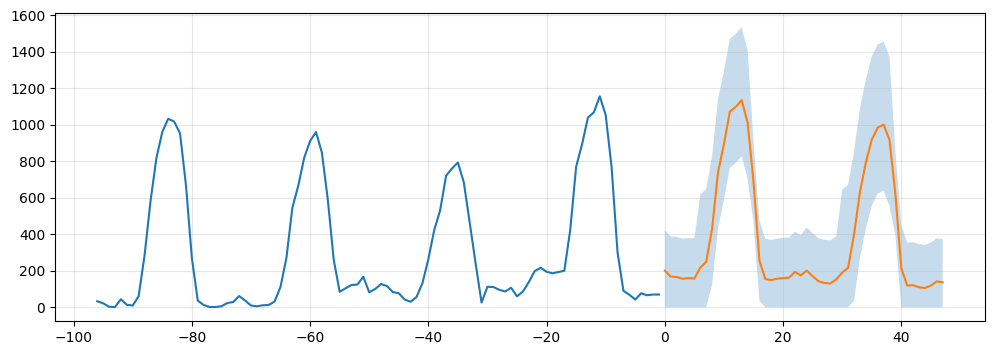

In [ ]:
NAME, WIDEN = "lgbm2+mean3", 1.5       # <- за результатами комірок 5-6
i0 = n - 1
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(i0, wx_f, fut)
ms_f = fit2(np.ones(len(O_all), bool), n)
p_f = pred2(ms_f, X_f) * lv_f
if NAME == "lgbm2+mean3":
    p_f = 0.8 * p_f + 0.2 * mean3_fc(i0)

q_all = calib(make_df(P[NAME]))
dl = wx_f[:, WI["daylight"]]
lo_r = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f
hi_r = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f
sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"), "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_r * WIDEN, 0, None),
                    "upper_95": p_f + hi_r * WIDEN})
sub.to_csv("MAZKO_lgbm2_mean3_project.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(range(-96, 0), yarr[-96:]); plt.plot(range(48), sub.forecast)
plt.fill_between(range(48), sub.lower_95, sub.upper_95, alpha=.25); plt.show()

### Шукаємо що дало найкращі зміни

In [ ]:
V1      = list(range(0, 13)) + [14, 17]       # рівно фічі v1
EXTRA_L = [13, 15, 16, 18]                    # лаг -48, рівні 3д/14д, пік 3д
NIGHT   = [19, 20]                            # нічний мінімум, остання година
DAYAGG  = [21, 22]                            # агрегована погода доби
ALL     = list(range(23))

def run(cols, half_life=180, seeds=(0,)):
    out = {}
    for bl in blocks:
        mask = O_all < bl[0] - 48
        ref = bl[0]
        w = L_all[mask] * (0.5 ** ((ref - O_all[mask]) / (24 * half_life)) if half_life else 1.0)
        Xtr = X2_all[mask][:, cols]
        ms = [lgb.LGBMRegressor(n_estimators=400, learning_rate=0.03, num_leaves=15,
              min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
              random_state=s, verbose=-1).fit(Xtr, Y_all[mask], sample_weight=w) for s in seeds]
        for o in bl:
            te = O_all == o
            p = np.clip(np.mean([m.predict(X2_all[te][:, cols]) for m in ms], axis=0), 0, None)
            out[int(o)] = p * L_all[te]
    return out

def report(Pn, name):
    df = make_df(Pn); d2 = df[df.k == 1]
    s = evaluate_w(Pn, 1.4)
    return dict(model=name, RMSE90=rmse(df.y, df.p), RMSE_d2=rmse(d2.y, d2.p),
                MAPE90=mape(df.y, df.p), MAPE_d2=mape(d2.y, d2.p),
                Winkler_b3=s["Winkler"], cov_b3=s["coverage"])

exps = {
  "A v1 фічі, без decay":          (V1, None),
  "B v1 + decay":                  (V1, 180),
  "C v1 + extra лаги/рівні":       (V1 + EXTRA_L, None),
  "D v1 + night(min,last)":        (V1 + NIGHT, None),
  "E v1 + day-agg погода":         (V1 + DAYAGG, None),
  "F ALL, без decay":              (ALL, None),
  "G ALL + decay":                 (ALL, 180),
  "H ALL + decay, seed=1":         (ALL, 180),          # міра шуму seed
  "-extra (G без C)":              ([c for c in ALL if c not in EXTRA_L], 180),
  "-night (G без D)":              ([c for c in ALL if c not in NIGHT], 180),
  "-dayagg (G без E)":             ([c for c in ALL if c not in DAYAGG], 180),
}
R = []
for name, (cols, hl) in exps.items():
    seeds = (1,) if "seed=1" in name else (0,)
    Pn = run(cols, hl, seeds)
    P["abl " + name] = Pn
    R.append(report(Pn, name)); print("done", name)

R.append(report(P["snaive"], "snaive"))
R.append(report(P["lgbm2+mean3"], "lgbm2+mean3 (3 seed, поточний)"))
print(pd.DataFrame(R).round(1).to_string())

done A v1 фічі, без decay
done B v1 + decay
done C v1 + extra лаги/рівні
done D v1 + night(min,last)
done E v1 + day-agg погода
done F ALL, без decay
done G ALL + decay
done H ALL + decay, seed=1
done -extra (G без C)
done -night (G без D)
done -dayagg (G без E)
                             model  RMSE90  RMSE_d2  MAPE90  MAPE_d2  Winkler_b3  cov_b3
0             A v1 фічі, без decay   271.4    290.4   274.4    277.4      1462.7     0.9
1                     B v1 + decay   265.8    283.1   245.4    271.0      1378.0     0.9
2          C v1 + extra лаги/рівні   257.1    270.9   223.2    246.3      1702.0     0.9
3           D v1 + night(min,last)   253.0    278.4   220.9    232.0      1309.4     0.9
4            E v1 + day-agg погода   267.1    284.2   189.8    176.5      1554.8     0.9
5                 F ALL, без decay   247.8    268.0   136.3    158.6      1612.9     0.9
6                    G ALL + decay   241.5    259.3   119.2    140.8      1588.0     0.9
7            H ALL + deca

In [ ]:
def with_night_scale(Pn, c):
    out = {}
    for o in O90:
        dl_ = Warr[o+1:o+49, WI["daylight"]]
        out[o] = Pn[o] * np.where(dl_ == 0, c, 1.0)
    return out

base = P["lgbm2+mean3"]
R2 = []
for c in [1.0, 0.9, 0.8, 0.7, 0.6]:
    Pn = with_night_scale(base, c)
    R2.append(report(Pn, f"night x{c}"))
print(pd.DataFrame(R2).round(1).to_string())

        model  RMSE90  RMSE_d2  MAPE90  MAPE_d2  Winkler_b3  cov_b3
0  night x1.0   236.9    255.5   135.5    153.8      1496.1     0.9
1  night x0.9   234.2    252.5   121.9    138.4      1484.2     0.9
2  night x0.8   234.9    252.5   109.1    123.8      1467.6     0.9
3  night x0.7   238.8    255.7    97.1    110.0      1454.8     0.9
4  night x0.6   245.8    261.8    86.2     97.2      1437.8     0.9


In [ ]:
base = P["lgbm2"]                                   # 3 seed, ALL + decay
Pn = with_night_scale(base, 0.8)
P["final"] = Pn

# Дві схеми: калібрування на блоках 0-1, тест на блоці 2; і навпаки (0 і 2 -> 1), щоб не покладатися на один блок
def eval_fold(Pn, test_b, wide):
    df = make_df(Pn); q = calib(df[df.b != test_b]); te = df[df.b == test_b]
    pred, lo, hi = interval(te, q)
    lo = np.clip(pred - (pred - lo) * wide, 0, None); hi = pred + (hi - pred) * wide
    return score(te.y, pred, lo, hi)

R3 = []
for wd in [1.0, 1.2, 1.4, 1.6, 1.8]:
    for tb in [1, 2]:
        s = eval_fold(Pn, tb, wd); R3.append(dict(widen=wd, test_block=tb, **s))
t = pd.DataFrame(R3)
print(t.round(3).to_string())
print(t.groupby("widen")[["Winkler", "coverage"]].mean().round(3))

   widen  test_block     RMSE     MAPE   Winkler  coverage
0    1.0           1  237.938   55.328  1196.665     0.975
1    1.0           2  287.774  189.594  2181.209     0.788
2    1.2           1  237.938   55.328  1355.637     0.997
3    1.2           2  287.774  189.594  1812.904     0.835
4    1.4           1  237.938   55.328  1548.882     0.999
5    1.4           2  287.774  189.594  1558.755     0.887
6    1.6           1  237.938   55.328  1742.035     1.000
7    1.6           2  287.774  189.594  1406.302     0.921
8    1.8           1  237.938   55.328  1930.951     1.000
9    1.8           2  287.774  189.594  1331.530     0.948
        Winkler  coverage
widen                    
1.0    1688.937     0.881
1.2    1584.271     0.916
1.4    1553.819     0.943
1.6    1574.169     0.960
1.8    1631.241     0.974


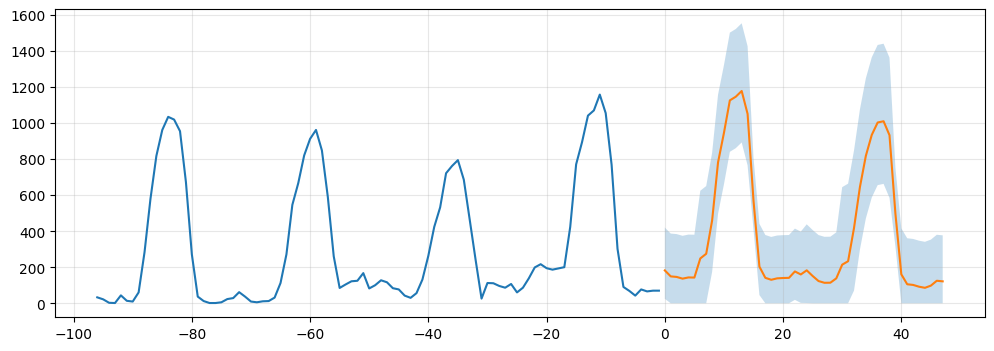

In [ ]:
NIGHT_SCALE, WIDEN = 0.8, 1.4        # <- WIDEN за коміркою 10 (+0.1 запас на помилку прогнозу погоди)
i0 = n - 1
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(i0, wx_f, fut)
ms_f = fit2(np.ones(len(O_all), bool), n)
dl = wx_f[:, WI["daylight"]]
p_f = pred2(ms_f, X_f) * lv_f * np.where(dl == 0, NIGHT_SCALE, 1.0)

q_all = calib(make_df(P["final"]))
lo_r = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f
hi_r = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f
sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"), "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_r * WIDEN, 0, None),
                    "upper_95": p_f + hi_r * WIDEN})
sub.to_csv("MAZKO_lgbm2_weight_decay_project.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(range(-96, 0), yarr[-96:]); plt.plot(range(48), sub.forecast)
plt.fill_between(range(48), sub.lower_95, sub.upper_95, alpha=.25); plt.show()

### experiment мультиплікативний інтервал

In [ ]:
def calib2(df, eps):
    r2 = (df.y - df.p) / (df.p + eps * df.lv)
    return {g: (r2[m.index].quantile(0.025), r2[m.index].quantile(0.975))
            for g, m in df.groupby(["k", "dl"])}

def eval_fold2(Pn, test_b, wide, eps, train_blocks=None):
    df = make_df(Pn)
    tr = df[df.b != test_b] if train_blocks is None else df[df.b.isin(train_blocks)]
    q = calib2(tr, eps); te = df[df.b == test_b]
    sc = te.p + eps * te.lv
    lo = np.array([q[(a, b)][0] for a, b in zip(te.k, te.dl)]) * sc
    hi = np.array([q[(a, b)][1] for a, b in zip(te.k, te.dl)]) * sc
    pred = te.p.to_numpy()
    lo = np.clip(pred + lo * wide, 0, None); hi = pred + hi * wide
    return score(te.y, pred, lo, hi)

R4 = []
for eps in [0.05, 0.15, 0.3]:
    for wd in [1.0, 1.2, 1.4, 1.6]:
        for tb in [1, 2]:
            R4.append(dict(eps=eps, widen=wd, test_block=tb, **eval_fold2(P["final"], tb, wd, eps)))
t4 = pd.DataFrame(R4)
print(t4.groupby(["eps", "widen"])[["Winkler", "coverage"]].mean().round(3))
print(t4[t4.test_block == 2].set_index(["eps", "widen"])[["Winkler", "coverage"]].round(3))

             Winkler  coverage
eps  widen                    
0.05 1.0    1623.184     0.902
     1.2    1642.484     0.950
     1.4    1725.275     0.965
     1.6    1836.946     0.975
0.15 1.0    1640.122     0.893
     1.2    1614.435     0.938
     1.4    1666.270     0.959
     1.6    1759.825     0.972
0.30 1.0    1658.122     0.888
     1.2    1603.406     0.930
     1.4    1630.160     0.955
     1.6    1703.167     0.969
             Winkler  coverage
eps  widen                    
0.05 1.0    1765.667     0.831
     1.2    1555.556     0.905
     1.4    1465.449     0.930
     1.6    1432.906     0.950
0.15 1.0    1889.839     0.812
     1.2    1612.656     0.882
     1.4    1470.031     0.919
     1.6    1413.966     0.943
0.30 1.0    1990.269     0.796
     1.2    1665.044     0.864
     1.4    1484.096     0.910
     1.6    1397.794     0.938


### experiment шум у погоді при навчанні

In [ ]:
rng = np.random.default_rng(0)
WCOLS = list(range(4, 11))               # погода у X2_all
sd = np.array([0.25, 1.0, 0.7, 1.5, 4.0, 0.0, 0.003])   # cloud, temp, wind, pressure, humidity, daylight, density
def noisy(X, scale_by_day=(1.0, 1.6)):
    Xn = X.copy()
    mult = np.where(Xn[:, 2] == 0, scale_by_day[0], scale_by_day[1])[:, None]
    Xn[:, WCOLS] += rng.normal(size=(len(Xn), 7)) * sd * mult
    Xn[:, 4] = np.clip(Xn[:, 4], 0, 1)   # cloud_cover
    return Xn

X2_orig = X2_all.copy()
X2_all = np.vstack([X2_orig, noisy(X2_orig)])       # подвоєна вибірка: чисті + зашумлені
Y_all_o, L_all_o, O_all_o = Y_all, L_all, O_all
Y_all, L_all, O_all = np.tile(Y_all_o, 2), np.tile(L_all_o, 2), np.tile(O_all_o, 2)

P["lgbm2_noise"] = {}
for bl in blocks:
    ms = fit2(O_all < bl[0] - 48, bl[0])
    te = np.isin(O_all, bl) & (np.arange(len(O_all)) < len(O_all_o))   # тест лише на чистих рядках
    for o in bl:
        t_ = (O_all == o) & (np.arange(len(O_all)) < len(O_all_o))
        P["lgbm2_noise"][int(o)] = pred2(ms, X2_all[t_]) * L_all[t_]

Pn2 = with_night_scale(P["lgbm2_noise"], 0.8)
print(pd.DataFrame([report(P["final"], "final (без шуму)"), report(Pn2, "з шумом у погоді")]).round(1).to_string())

# повернути як було
X2_all, Y_all, L_all, O_all = X2_orig, Y_all_o, L_all_o, O_all_o

              model  RMSE90  RMSE_d2  MAPE90  MAPE_d2  Winkler_b3  cov_b3
0  final (без шуму)   235.2    251.6    97.5    116.3      1558.8     0.9
1  з шумом у погоді   235.9    252.5    95.9    113.2      1544.4     0.9


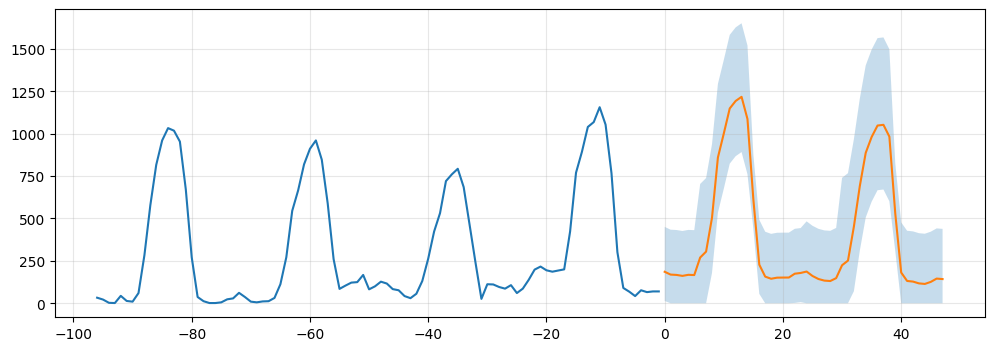

       forecast  lower_95  upper_95
count      48.0      48.0      48.0
mean      409.2     187.1     762.5
std       374.5     297.5     451.8
min       114.1       0.0     409.5
25%       150.3       0.0     429.3
50%       180.1       0.0     453.8
75%       630.7     341.7    1027.8
max      1217.5     891.8    1651.3


In [ ]:
NIGHT_SCALE, WIDEN = 0.8, 1.6

# калібрування на залишках моделі з шумом
P["final_noise"] = with_night_scale(P["lgbm2_noise"], NIGHT_SCALE)
q_all = calib(make_df(P["final_noise"]))

# перенавчання на всій історії: чисті + зашумлені рядки
rng = np.random.default_rng(1)
X2_orig, Y_o, L_o, O_o = X2_all.copy(), Y_all, L_all, O_all
X2_all = np.vstack([X2_orig, noisy(X2_orig)])
Y_all, L_all, O_all = np.tile(Y_o, 2), np.tile(L_o, 2), np.tile(O_o, 2)
ms_f = fit2(np.ones(len(O_all), bool), n)
X2_all, Y_all, L_all, O_all = X2_orig, Y_o, L_o, O_o      # повернути

i0 = n - 1
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(i0, wx_f, fut)
dl = wx_f[:, WI["daylight"]]
p_f = pred2(ms_f, X_f) * lv_f * np.where(dl == 0, NIGHT_SCALE, 1.0)

lo_r = np.array([q_all[(a, b)][0] for a, b in zip(k, dl)]) * lv_f
hi_r = np.array([q_all[(a, b)][1] for a, b in zip(k, dl)]) * lv_f
sub = pd.DataFrame({"ds": fut.strftime("%Y-%m-%d %H:%M:%S"), "forecast": p_f,
                    "lower_95": np.clip(p_f + lo_r * WIDEN, 0, None),
                    "upper_95": p_f + hi_r * WIDEN})
sub.to_csv("MAZKO_final_lgbm2_noise_project.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(range(-96, 0), yarr[-96:]); plt.plot(range(48), sub.forecast)
plt.fill_between(range(48), sub.lower_95, sub.upper_95, alpha=.25); plt.show()
print(sub.describe().round(1))

### regression

In [ ]:
def fitq(mask, ref, alpha, half_life=180):
    w = L_all[mask] * 0.5 ** ((ref - O_all[mask]) / (24 * half_life))
    return lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=400,
                             learning_rate=0.03, num_leaves=15, min_child_samples=50,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=0, verbose=-1).fit(X2_all[mask], Y_all[mask], sample_weight=w)

QL, QH = {}, {}
for bl in blocks:
    mask = O_all < bl[0] - 48
    mlo, mhi = fitq(mask, bl[0], 0.025), fitq(mask, bl[0], 0.975)
    for o in bl:
        te = O_all == o
        QL[int(o)] = np.clip(mlo.predict(X2_all[te]), 0, None) * L_all[te]
        QH[int(o)] = np.clip(mhi.predict(X2_all[te]), 0, None) * L_all[te]
    print("block done")

def eval_q(Pn, wide, tb):
    df = make_df(Pn); te = df[df.b == tb]
    os_ = [o for o, b in zip(O90, B90) if b == tb]
    ql = np.concatenate([QL[o] for o in os_]); qh = np.concatenate([QH[o] for o in os_])
    p = te.p.to_numpy()
    lo = np.clip(p - (p - np.minimum(ql, p)) * wide, 0, None)
    hi = p + (np.maximum(qh, p) - p) * wide
    return score(te.y, p, lo, hi)

R5 = []
for wd in [1.0, 1.15, 1.3, 1.5]:
    for tb in [0, 1, 2]:
        R5.append(dict(method="quantile", widen=wd, block=tb, **eval_q(P["final_noise"], wd, tb)))
for tb in [0, 1, 2]:
    R5.append(dict(method="additive", widen=1.6, block=tb, **eval_fold(P["final_noise"], tb, 1.6)))
t5 = pd.DataFrame(R5)
print(t5[["method", "widen", "block", "Winkler", "coverage"]].round(3).to_string())
print(t5.groupby(["method", "widen"])[["Winkler", "coverage"]].mean().round(3))

In [ ]:
def fitq(mask, ref, alpha, half_life=180):
    w = 0.5 ** ((ref - O_all[mask]) / (24 * half_life))      # без L_all
    return lgb.LGBMRegressor(objective="quantile", alpha=alpha, n_estimators=400,
                             learning_rate=0.03, num_leaves=15, min_child_samples=50,
                             subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                             random_state=0, verbose=-1).fit(X2_all[mask], Y_all[mask], sample_weight=w)

QL, QH = {}, {}
for bl in blocks:
    mask = O_all < bl[0] - 48
    mlo, mhi = fitq(mask, bl[0], 0.025), fitq(mask, bl[0], 0.975)
    for o in bl:
        te = O_all == o
        QL[int(o)] = np.clip(mlo.predict(X2_all[te]), 0, None) * L_all[te]
        QH[int(o)] = np.clip(mhi.predict(X2_all[te]), 0, None) * L_all[te]

print("max верхньої межі:", max(v.max() for v in QH.values()).round(0))   # має бути ~ тисячі, не 1e10+

R5 = []
for wd in [1.0, 1.15, 1.3, 1.5]:
    for tb in [0, 1, 2]:
        R5.append(dict(method="quantile", widen=wd, block=tb, **eval_q(P["final_noise"], wd, tb)))
for tb in [0, 1, 2]:
    R5.append(dict(method="additive", widen=1.6, block=tb, **eval_fold(P["final_noise"], tb, 1.6)))
t5 = pd.DataFrame(R5)
print(t5.groupby(["method", "widen"])[["Winkler", "coverage"]].mean().round(3))
print(t5[t5.block == 2][["method", "widen", "Winkler", "coverage"]].round(3))

In [ ]:
summary = pd.concat([pd.DataFrame(R).assign(src="ablation"),
                     pd.DataFrame(R2).assign(src="night_scale")], ignore_index=True)
summary

## Chronos / lgbm without weather / ensembles

In [ ]:
!pip -q install chronos-forecasting
import lightgbm as lgb   # якщо немає: !pip install lightgbm

import torch
from chronos import BaseChronosPipeline
pipe = BaseChronosPipeline.from_pretrained("amazon/chronos-bolt-small",
                                           device_map="cpu", torch_dtype=torch.float32)


Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

In [ ]:

def chronos_fc(i, ctx):
    c = torch.tensor(yarr[max(0, i - ctx + 1):i + 1], dtype=torch.float32)
    quantiles, mean = pipe.predict_quantiles(inputs=[c], prediction_length=48,
                                             quantile_levels=[0.5])
    return np.clip(quantiles[0, :, 0].float().numpy(), 0, None)   # медіана, довжина 48

# швидка перевірка перед великим циклом
t = chronos_fc(O90[0], 336)
print(t.shape, t[:5].round(1))


(48,) [ 90.4  93.8  95.2 109.9 125.7]


In [ ]:

for ctx in (336, 1008):                       # 14 і 42 доби контексту
    P[f"chr{ctx}"] = {o: chronos_fc(o, ctx) for o in O90}
    print("chronos", ctx, "done")

# LightGBM без погоди: час + лаги/рівні/піки
NOW = [0, 1, 2, 3] + list(range(11, 21))
P["lgbm_noW"] = run(NOW, 180, (0, 1, 2))

def avg(names): return {o: np.mean([P[x][o] for x in names], axis=0) for o in O90}

def full_eval(Pn, wide=1.0):
    df = make_df(Pn); parts = []
    for tb in [0, 1, 2]:
        q = calib(df[df.b != tb]); te = df[df.b == tb].copy()
        pred, lo, hi = interval(te, q)
        te["pred"] = pred
        te["lo"] = np.clip(pred - (pred - lo) * wide, 0, None)
        te["hi"] = pred + (hi - pred) * wide
        parts.append(te)
    dd = pd.concat(parts); out = {}
    for nm, m in [("d1", dd.k == 0), ("d2", dd.k == 1)]:
        x = dd[m]
        out[f"RMSE_{nm}"] = rmse(x.y, x.pred); out[f"MAPE_{nm}"] = mape(x.y, x.pred)
        out[f"Wink_{nm}"] = winkler(x.y, x.lo, x.hi)
        out[f"cov_{nm}"] = float(((x.y >= x.lo) & (x.y <= x.hi)).mean())
    return out

cands = {
    "snaive": P["snaive"],
    "lgbm_w (з погодою, ніч x0.8)": P["final_noise"],
    "lgbm_noW": P["lgbm_noW"],
    "chr336": P["chr336"],
    "chr1008": P["chr1008"],
    "lgbm_w + chr336": avg(["final_noise", "chr336"]),
    "lgbm_noW + chr336": avg(["lgbm_noW", "chr336"]),
    "lgbm_w + lgbm_noW + chr336": avg(["final_noise", "lgbm_noW", "chr336"]),
    "lgbm_noW + chr336 + chr1008": avg(["lgbm_noW", "chr336", "chr1008"]),
    "mean3 + chr336": avg(["mean3", "chr336"]),
}
tab = pd.DataFrame({nm: full_eval(v) for nm, v in cands.items()}).T
print(tab.round(1).sort_values("RMSE_d2").to_string())


chronos 336 done
chronos 1008 done
                              RMSE_d1  MAPE_d1  Wink_d1  cov_d1  RMSE_d2  MAPE_d2  Wink_d2  cov_d2
lgbm_w + chr336                 203.2     73.3   1198.6     0.9    251.5    155.7   1464.0     0.9
lgbm_w (з погодою, ніч x0.8)    218.1     78.6   1344.3     0.9    252.5    113.2   1583.4     0.9
lgbm_w + lgbm_noW + chr336      209.9    117.1   1210.1     0.9    262.2    195.1   1525.8     0.9
lgbm_noW + chr336 + chr1008     229.9    119.4   1311.2     0.9    285.4    224.6   1752.2     0.9
lgbm_noW + chr336               231.6    139.3   1331.7     0.9    286.7    237.9   1705.6     0.9
chr336                          238.9     75.5   1318.9     0.9    288.6    203.0   1697.9     0.9
mean3 + chr336                  240.4    136.4   1394.7     0.9    293.9    198.8   1740.0     0.9
chr1008                         239.1     83.0   1392.4     0.9    296.3    200.3   1871.5     0.9
lgbm_noW                        253.6    210.2   1387.2     0.9    312.2  

In [ ]:
ens = avg(["final_noise", "chr336"])
rows_ = []
for c in [1.0, 0.9, 0.8, 0.7, 0.6]:
    Pn = with_night_scale(ens, c)
    for wd in [1.0, 1.2]:
        r = full_eval(Pn, wd)
        rows_.append(dict(night=c, widen=wd, **{k_: r[k_] for k_ in ["RMSE_d2", "MAPE_d2", "Wink_d2", "cov_d2"]}))
print(pd.DataFrame(rows_).round(2).to_string())

   night  widen  RMSE_d2  MAPE_d2  Wink_d2  cov_d2
0    1.0    1.0   251.49   155.68  1464.00    0.92
1    1.0    1.2   251.49   155.68  1434.17    0.95
2    0.9    1.0   252.72   141.35  1461.99    0.92
3    0.9    1.2   252.72   141.35  1438.10    0.94
4    0.8    1.0   256.08   127.62  1452.69    0.92
5    0.8    1.2   256.08   127.62  1433.78    0.95
6    0.7    1.0   261.48   114.55  1448.12    0.91
7    0.7    1.2   261.48   114.55  1431.50    0.95
8    0.6    1.0   268.79   102.20  1442.20    0.91
9    0.6    1.2   268.79   102.20  1429.36    0.95


### upgrade valid stratagy

In [ ]:
NO = 240
OR = [int(i) for i in origins[-NO:]]
BL = np.repeat(np.arange(NO // 30), 30)
blocks8 = np.array_split(np.array(OR), NO // 30)
cur_lv = yarr[-168:].mean()
print("поточний рівень lv7:", round(cur_lv, 1))

SDW = np.array([0.25, 1.0, 0.7, 1.5, 4.0, 0.0, 0.003])
rng8 = np.random.default_rng(42)
def noisy_wx(wx):
    m = np.r_[np.full(24, 1.0), np.full(24, 1.6)][:, None]
    w = wx + rng8.normal(size=wx.shape) * SDW * m
    w[:, 0] = np.clip(w[:, 0], 0, 1)
    return w

P8 = {k_: {} for k_ in ["snaive", "mean3", "lgbm", "lgbm_nzW", "chr336"]}
for b, bl in enumerate(blocks8):
    ms = fit2(O_all < bl[0] - 48, bl[0], seeds=(0, 1))
    for o in bl:
        o = int(o); te = O_all == o
        dl_ = Warr[o+1:o+49, WI["daylight"]]; nt = np.where(dl_ == 0, 0.8, 1.0)
        P8["lgbm"][o] = pred2(ms, X2_all[te]) * L_all[te] * nt
        Xn, lv = rows2(o, noisy_wx(Warr[o+1:o+49]), idx[o+1:o+49])
        P8["lgbm_nzW"][o] = pred2(ms, Xn) * lv * nt
        P8["snaive"][o] = snaive(yarr[:o+1])[0]
        P8["mean3"][o] = mean3_fc(o)
        P8["chr336"][o] = chronos_fc(o, 336)
    print("block", b, "done")

def avg8(names, w=None):
    w = np.ones(len(names)) / len(names) if w is None else np.array(w)
    return {o: sum(wi * P8[n][o] for wi, n in zip(w, names)) for o in OR}

def mk(Pn):
    rows = []
    for b, o in zip(BL, OR):
        y_ = yarr[o+1:o+49]; lv = yarr[:o+1][-168:].mean(); p = np.clip(Pn[o], 0, None)
        rows.append(pd.DataFrame(dict(b=b, o=o, y=y_, p=p, lv=lv, r=(y_ - p) / lv,
                    k=np.arange(48) // 24, dl=Warr[o+1:o+49, WI["daylight"]])))
    return pd.concat(rows, ignore_index=True)

def ev(Pn, wide=1.0, night=1.0, subset=None):
    Pn = {o: Pn[o] * np.where(Warr[o+1:o+49, WI["daylight"]] == 0, night, 1.0) for o in OR}
    df = mk(Pn); parts = []
    for tb in np.unique(BL):
        q = calib(df[df.b != tb]); te = df[df.b == tb].copy()
        pred, lo, hi = interval(te, q)
        te["pred"] = pred
        te["lo"] = np.clip(pred - (pred - lo) * wide, 0, None)
        te["hi"] = pred + (hi - pred) * wide
        parts.append(te)
    dd = pd.concat(parts)
    if subset is not None: dd = dd[dd.o.isin(subset)]
    x = dd[dd.k == 1]
    return dict(nRMSE=rmse(x.y / x.lv, x.pred / x.lv), MAPE=mape(x.y, x.pred),
                nWink=winkler(x.y / x.lv, x.lo / x.lv, x.hi / x.lv),
                cov=float(((x.y >= x.lo) & (x.y <= x.hi)).mean()), n=x.o.nunique())

low = [o for o in OR if yarr[:o+1][-168:].mean() < 2 * cur_lv]
print("відліків із рівнем, схожим на поточний:", len(low))

cands = {
  "snaive": P8["snaive"], "mean3": P8["mean3"],
  "lgbm": P8["lgbm"], "lgbm (шум у погоді)": P8["lgbm_nzW"], "chr336": P8["chr336"],
  "lgbm+chr": avg8(["lgbm", "chr336"]),
  "lgbm(шум)+chr": avg8(["lgbm_nzW", "chr336"]),
  "0.7 lgbm(шум)+0.3 chr": avg8(["lgbm_nzW", "chr336"], [0.7, 0.3]),
  "lgbm(шум)+chr+mean3": avg8(["lgbm_nzW", "chr336", "mean3"]),
}

def table(subset=None, night=1.0, wide=1.2):
    t = pd.DataFrame({k_: ev(v, wide, night, subset) for k_, v in cands.items()}).T
    t["rank"] = (0.3 * t.nRMSE.rank() + 0.3 * t.MAPE.rank() + 0.4 * t.nWink.rank())
    return t.sort_values("rank")

print("\nУСІ 240 відліків, ніч x1.0"); print(table().round(3).to_string())
print("\nЛИШЕ схожий рівень, ніч x1.0"); print(table(low).round(3).to_string())
print("\nЛИШЕ схожий рівень, ніч x0.8 (поверх вже вбудованого в lgbm)"); print(table(low, 0.8).round(3).to_string())

поточний рівень lv7: 362.9
block 0 done
block 1 done
block 2 done
block 3 done
block 4 done
block 5 done
block 6 done
block 7 done
відліків із рівнем, схожим на поточний: 84

УСІ 240 відліків, ніч x1.0
                       nRMSE     MAPE  nWink    cov      n  rank
lgbm+chr               0.323  106.071  1.635  0.972  240.0   2.2
lgbm                   0.321   86.716  1.672  0.969  240.0   2.2
0.7 lgbm(шум)+0.3 chr  0.324  100.653  1.635  0.970  240.0   2.6
lgbm(шум)+chr          0.330  108.190  1.665  0.971  240.0   3.9
lgbm (шум у погоді)    0.332   91.161  1.705  0.971  240.0   4.1
lgbm(шум)+chr+mean3    0.342  118.129  1.745  0.975  240.0   6.0
chr336                 0.377  130.967  1.883  0.971  240.0   7.0
mean3                  0.407  142.600  2.061  0.974  240.0   8.0
snaive                 0.425  194.074  2.086  0.972  240.0   9.0

ЛИШЕ схожий рівень, ніч x1.0
                       nRMSE     MAPE  nWink    cov     n  rank
lgbm                   0.394   74.552  1.899  0.947  8

In [ ]:
def ev2(Pn, wide=1.0, night=1.0, subset=None):
    Pn = {o: Pn[o] * np.where(Warr[o+1:o+49, WI["daylight"]] == 0, night, 1.0) for o in OR}
    df = mk(Pn); parts = []
    for tb in np.unique(BL):
        q = calib(df[df.b != tb]); te = df[df.b == tb].copy()
        pred, lo, hi = interval(te, q)
        te["pred"] = pred
        te["lo"] = np.clip(pred - (pred - lo) * wide, 0, None)
        te["hi"] = pred + (hi - pred) * wide
        parts.append(te)
    dd = pd.concat(parts)
    if subset is not None: dd = dd[dd.o.isin(subset)]
    x = dd[dd.k == 1]
    return dict(RMSE=rmse(x.y, x.pred), MAPE=mape(x.y, x.pred),
                Wink=winkler(x.y, x.lo, x.hi),
                cov=float(((x.y >= x.lo) & (x.y <= x.hi)).mean()))

C2 = {
  "lgbm(шум)": P8["lgbm_nzW"],
  "0.85 lgbm+0.15 chr": avg8(["lgbm_nzW", "chr336"], [0.85, 0.15]),
  "0.7 lgbm+0.3 chr":   avg8(["lgbm_nzW", "chr336"], [0.7, 0.3]),
  "0.5 lgbm+0.5 chr":   avg8(["lgbm_nzW", "chr336"], [0.5, 0.5]),
}
rows_ = []
for nm, v in C2.items():
    for wd in [1.0, 1.1, 1.2, 1.3]:
        rows_.append(dict(model=nm, wide=wd, **ev2(v, wd, 0.8, low)))
t = pd.DataFrame(rows_)
print(t.round(2).to_string())

# стабільність по часу: той самий вибір на двох половинах схожого рівня
half = len(low) // 2
for nm in ["lgbm(шум)", "0.7 lgbm+0.3 chr"]:
    for part, s in [("перша", low[:half]), ("друга", low[half:])]:
        print(nm, part, {k_: round(v_, 2) for k_, v_ in ev2(C2[nm], 1.2, 0.8, s).items()})

                 model  wide    RMSE   MAPE     Wink   cov
0            lgbm(шум)   1.0  236.88  68.22  1170.98  0.91
1            lgbm(шум)   1.1  236.88  68.22  1124.21  0.93
2            lgbm(шум)   1.2  236.88  68.22  1108.38  0.95
3            lgbm(шум)   1.3  236.88  68.22  1117.20  0.96
4   0.85 lgbm+0.15 chr   1.0  233.78  70.25  1144.99  0.91
5   0.85 lgbm+0.15 chr   1.1  233.78  70.25  1099.24  0.93
6   0.85 lgbm+0.15 chr   1.2  233.78  70.25  1079.76  0.95
7   0.85 lgbm+0.15 chr   1.3  233.78  70.25  1087.04  0.97
8     0.7 lgbm+0.3 chr   1.0  234.20  72.91  1126.63  0.90
9     0.7 lgbm+0.3 chr   1.1  234.20  72.91  1078.16  0.93
10    0.7 lgbm+0.3 chr   1.2  234.20  72.91  1059.38  0.95
11    0.7 lgbm+0.3 chr   1.3  234.20  72.91  1067.98  0.97
12    0.5 lgbm+0.5 chr   1.0  240.18  77.59  1153.19  0.90
13    0.5 lgbm+0.5 chr   1.1  240.18  77.59  1096.63  0.93
14    0.5 lgbm+0.5 chr   1.2  240.18  77.59  1077.08  0.95
15    0.5 lgbm+0.5 chr   1.3  240.18  77.59  1086.87  0.

## Спільна основа: однаковий шум і перевірка значущості

In [ ]:
# фіксований шум на відлік
def noisy_wx_seeded(o):
    r = np.random.default_rng(o)
    m = np.r_[np.full(24, 1.0), np.full(24, 1.6)][:, None]
    w = Warr[o+1:o+49] + r.normal(size=(48, 7)) * SDW * m
    w[:, 0] = np.clip(w[:, 0], 0, 1)
    return w
XN = {o: rows2(o, noisy_wx_seeded(o), idx[o+1:o+49]) for o in OR}
NT = {o: np.where(Warr[o+1:o+49, WI["daylight"]] == 0, 0.8, 1.0) for o in OR}

def ev_df(Pn, wide=1.2):
    df = mk(Pn); parts = []
    for tb in np.unique(BL):
        q = calib(df[df.b != tb]); te = df[df.b == tb].copy()
        pred, lo, hi = interval(te, q)
        te["pred"] = pred
        te["lo"] = np.clip(pred - (pred - lo) * wide, 0, None)
        te["hi"] = pred + (hi - pred) * wide
        parts.append(te)
    dd = pd.concat(parts); return dd[dd.k == 1]

def per_origin(Pn, wide=1.2):
    x = ev_df(Pn, wide)
    g = x.assign(se=(x.y - x.pred) ** 2, ape=(x.y - x.pred).abs() / x.y,
                 w=(x.hi - x.lo) + 40 * (np.clip(x.lo - x.y, 0, None) + np.clip(x.y - x.hi, 0, None)))
    return g.groupby("o")[["se", "ape", "w"]].mean()

def paired(A, B, subset, wide=1.2, nb=2000, blk=7, seed=0):
    a = per_origin(A, wide).loc[subset]; b = per_origin(B, wide).loc[subset]
    rng = np.random.default_rng(seed); n_ = len(a); res = []
    for _ in range(nb):
        starts = rng.integers(0, n_, size=n_ // blk + 1)
        ix = np.concatenate([np.arange(s, s + blk) % n_ for s in starts])[:n_]
        aa, bb = a.iloc[ix], b.iloc[ix]
        res.append([np.sqrt(aa.se.mean()) - np.sqrt(bb.se.mean()),
                    100 * (aa.ape.mean() - bb.ape.mean()), aa.w.mean() - bb.w.mean()])
    res = np.array(res)
    for j, nm in enumerate(["dRMSE", "dMAPE", "dWink"]):
        lo_, hi_ = np.percentile(res[:, j], [2.5, 97.5])
        print(f"{nm}: {res[:, j].mean():+.1f}  95% [{lo_:+.1f}, {hi_:+.1f}]")

low = sorted(low)
print("lgbm(шум) мінус ансамбль 0.7/0.3 (додатне = ансамбль кращий):")
paired(P8["lgbm_nzW"], avg8(["lgbm_nzW", "chr336"], [0.7, 0.3]), low)

lgbm(шум) мінус ансамбль 0.7/0.3 (додатне = ансамбль кращий):
dRMSE: +4.0  95% [-4.5, +13.8]
dMAPE: -6.0  95% [-15.7, +0.6]
dWink: +59.8  95% [-11.1, +174.7]


#### LGBM tuning

In [ ]:
BASE = dict(n_estimators=400, learning_rate=0.03, num_leaves=15, min_child_samples=50,
            subsample=0.8, subsample_freq=1, colsample_bytree=0.8)

def lgbm_cv(params={}, cols=ALL, half_life=180, seeds=(0, 1), recent=None):
    out = {}
    for bl in blocks8:
        mask = O_all < bl[0] - 48
        if recent: mask &= O_all >= bl[0] - 48 - 24 * recent
        w = L_all[mask] * 0.5 ** ((bl[0] - O_all[mask]) / (24 * half_life))
        ms = [lgb.LGBMRegressor(**{**BASE, **params}, random_state=s, verbose=-1)
              .fit(X2_all[mask][:, cols], Y_all[mask], sample_weight=w) for s in seeds]
        for o in bl:
            o = int(o); Xn, lv = XN[o]
            p = np.mean([m.predict(Xn[:, cols]) for m in ms], axis=0)
            out[o] = np.clip(p, 0, None) * lv * NT[o]
    return out

def row(Pn, subset, wide=1.2):
    x = ev_df(Pn, wide); x = x[x.o.isin(subset)]
    return dict(RMSE=rmse(x.y, x.pred), MAPE=mape(x.y, x.pred), Wink=winkler(x.y, x.lo, x.hi),
                cov=float(((x.y >= x.lo) & (x.y <= x.hi)).mean()))

grid = {
  "base": {},
  "leaves7": dict(num_leaves=7),
  "leaves31, mcs100": dict(num_leaves=31, min_child_samples=100),
  "800 trees, lr .015": dict(n_estimators=800, learning_rate=0.015),
  "lambda10": dict(reg_lambda=10),
  "mcs150": dict(min_child_samples=150),
  "hl90": "hl90", "hl365": "hl365", "recent365": "r365",
}
PT, R6 = {}, []
for nm, prm in grid.items():
    if prm == "hl90": Pn = lgbm_cv(half_life=90)
    elif prm == "hl365": Pn = lgbm_cv(half_life=365)
    elif prm == "r365": Pn = lgbm_cv(recent=365)
    else: Pn = lgbm_cv(prm)
    PT[nm] = Pn
    R6.append(dict(model=nm, **row(Pn, low), RMSE_all=row(Pn, OR)["RMSE"])); print("done", nm)
print(pd.DataFrame(R6).round(2).to_string())

done base
done leaves7
done leaves31, mcs100
done 800 trees, lr .015
done lambda10
done mcs150
done hl90
done hl365
done recent365
                model    RMSE   MAPE     Wink   cov  RMSE_all
0                base  236.31  78.91  1151.91  0.94    234.25
1             leaves7  238.68  73.60  1155.05  0.94    237.06
2    leaves31, mcs100  235.25  80.22  1163.57  0.94    233.33
3  800 trees, lr .015  235.08  77.55  1141.99  0.94    233.57
4            lambda10  235.10  75.52  1138.35  0.94    234.04
5              mcs150  234.57  78.24  1137.65  0.94    233.53
6                hl90  232.50  75.66  1103.83  0.95    233.01
7               hl365  235.09  75.17  1160.64  0.94    234.69
8           recent365  228.83  73.61  1085.86  0.95    231.37


## NEW CLAUDE CONVERSATION

In [ ]:
#Cell 1: state check and backup
import os, shutil

fn = "MAZKO_final_lgbm2_noise_project.csv"
if os.path.exists(fn):
    shutil.copy(fn, "BACKUP_public_file.csv")
    pub = pd.read_csv(fn); pub["w"] = pub.upper_95 - pub.lower_95
    print("file in cwd -> mean forecast %.1f | mean width %.1f | day1 width %.1f | day2 width %.1f"
          % (pub.forecast.mean(), pub.w.mean(), pub.w[:24].mean(), pub.w[24:].mean()))
    print("(the file I saw: 409.2 | 575.4 | 549.2 | 601.7)")
else:
    print("file not found in cwd:", fn)

need = ["data","weather_fc","FUTURE","d","yarr","Warr","W","WI","idx","n","origins","OR","low","blocks8",
        "X2_all","Y_all","L_all","O_all","P","P8","k","h","off","rows2","fit2","pred2","calib","interval",
        "mk","ev_df","per_origin","paired","rmse","mape","winkler","score","snaive","XN","NT","SDW","ms_f"]
print("missing variables:", [v for v in need if v not in globals()])
print("n, X2_all, Y_all, origins, OR, low:", n, X2_all.shape, Y_all.shape, len(origins), len(OR), len(low))
print("k unique:", np.unique(k), "| k shape:", k.shape, "| h:", h[[0, -1]], "| off:", off[[0, -1]])
print("NaN in yarr / Warr / X2_all:", int(np.isnan(yarr).sum()), int(np.isnan(Warr).sum()), int(np.isnan(X2_all).sum()))
print("current lv7:", round(yarr[-168:].mean(), 1))

file in cwd -> mean forecast 409.2 | mean width 575.4 | day1 width 549.2 | day2 width 601.7
(the file I saw: 409.2 | 575.4 | 549.2 | 601.7)
missing variables: []
n, X2_all, Y_all, origins, OR, low: 33480 (66480, 23) (66480,) 1385 240 84
k unique: [0 1] | k shape: (48,) | h: [ 1 48] | off: [-23   0]
NaN in yarr / Warr / X2_all: 0 0 0
current lv7: 362.9


#### eda

               mean   std    min     max
cloud_cover    0.61  0.41    0.0    1.00
temperature    9.04  3.90    4.0   19.00
wind_speed     2.56  1.01    0.0    4.00
pressure     760.50  2.93  755.0  764.00
humidity      95.83  8.10   60.0  100.00
daylight       0.38  0.49    0.0    1.00
air_density    1.26  0.02    1.2    1.29
NaN: 0
cloud levels forecast: [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(0.75), np.float64(1.0)] | last 7d: [np.float64(0.0), np.float64(0.25), np.float64(0.5), np.float64(1.0)]
daylight hours, last observed day: [8, 9, 10, 11, 12, 13, 14, 15, 16]
daylight hours, forecast day 1   : [7, 8, 9, 10, 11, 12, 13, 14, 15]
daylight hours, forecast day 2   : [7, 8, 9, 10, 11, 12, 13, 14, 15]

last 3 observed rows:
                      cloud_cover  temperature  wind_speed  pressure  humidity  daylight  air_density
ds                                                                                                  
2026-10-26 22:00:00          1.0       

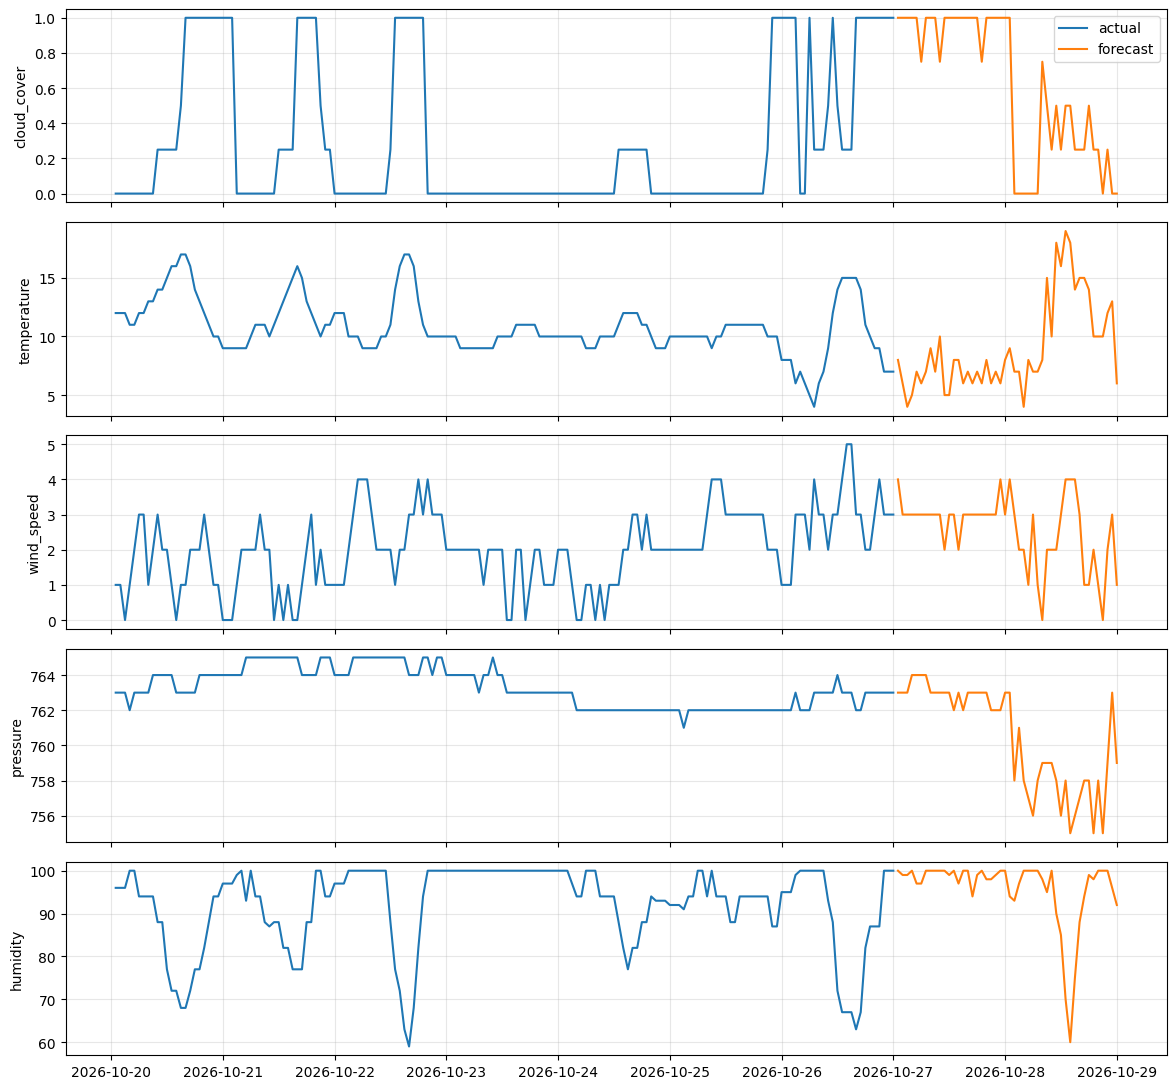

cloud -0.50 -> peak d1 965 | peak d2 963 | mean d1 362 | mean d2 347
cloud -0.25 -> peak d1 1107 | peak d2 967 | mean d1 396 | mean d2 350
cloud +0.00 -> peak d1 1217 | peak d2 1052 | mean d1 440 | mean d2 379
cloud +0.25 -> peak d1 1267 | peak d2 1187 | mean d1 455 | mean d2 407
cloud +0.50 -> peak d1 1267 | peak d2 1294 | mean d1 455 | mean d2 444


In [ ]:
#Cell 2: inspect weather_fc (never done before)
wf = weather_fc.set_index("ds")[W]
assert len(wf) == 48
print(wf.describe().T.round(2)[["mean", "std", "min", "max"]])
print("NaN:", int(wf.isna().sum().sum()))
print("cloud levels forecast:", sorted(wf.cloud_cover.unique()), "| last 7d:", sorted(d.cloud_cover.iloc[-168:].unique()))
print("daylight hours, last observed day:", list(d.index[-24:][d.daylight.iloc[-24:].values == 1].hour))
print("daylight hours, forecast day 1   :", list(wf.index[:24][wf.daylight.iloc[:24].values == 1].hour))
print("daylight hours, forecast day 2   :", list(wf.index[24:][wf.daylight.iloc[24:].values == 1].hour))
print("\nlast 3 observed rows:\n", d[W].iloc[-3:].round(2).to_string())
print("first 3 forecast rows:\n", wf.iloc[:3].round(2).to_string())

# daily summaries: last 7 observed days + 2 forecast days (day = 01:00..00:00, same as the model's k)
full = pd.concat([d[W].iloc[-168:], wf])
def dl_mean(x, c): return (x[c] * x.daylight).sum() / max(1, x.daylight.sum())
key = (full.index - pd.Timedelta(hours=1)).normalize()
summ = full.groupby(key).apply(lambda x: pd.Series({
    "cloud_daylight": dl_mean(x, "cloud_cover"), "wind_daylight": dl_mean(x, "wind_speed"),
    "temp": x.temperature.mean(), "humidity": x.humidity.mean(), "pressure": x.pressure.mean()}))
summ["is_forecast"] = [False] * 7 + [True] * 2
daily_y = pd.Series(yarr[-168:]).groupby(np.repeat(np.arange(7), 24)).agg(["max", "mean"]).round(0)
print("\n", summ.round(2).to_string())
print("\nobserved y per last 7 days (peak, mean):\n", daily_y.to_string())

fig, ax = plt.subplots(5, 1, figsize=(12, 11), sharex=True)
ctx = d[W].iloc[-168:]
for a, c in zip(ax, ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity"]):
    a.plot(ctx.index, ctx[c], label="actual"); a.plot(wf.index, wf[c], label="forecast"); a.set_ylabel(c)
ax[0].legend(); plt.tight_layout(); plt.show()

# sensitivity of the current model to the cloud forecast (uses ms_f = public-file model)
if "ms_f" in globals():
    fut = pd.DatetimeIndex(FUTURE)
    for dc in [-0.5, -0.25, 0, 0.25, 0.5]:
        wx = weather_fc[W].to_numpy(float).copy(); wx[:, 0] = np.clip(wx[:, 0] + dc, 0, 1)
        Xs_, lv_ = rows2(n - 1, wx, fut)
        p_ = pred2(ms_f, Xs_) * lv_ * np.where(wx[:, WI["daylight"]] == 0, 0.8, 1.0)
        print("cloud %+.2f -> peak d1 %.0f | peak d2 %.0f | mean d1 %.0f | mean d2 %.0f"
              % (dc, p_[:24].max(), p_[24:].max(), p_[:24].mean(), p_[24:].mean()))

In [ ]:
# Cell 3: data quality (stale or forward-filled values)
y = d["y"]
print("non-1h steps:", int((idx.to_series().diff().dropna() != pd.Timedelta(hours=1)).sum()),
      "| duplicated ts:", int(idx.duplicated().sum()), "| negatives:", int((y < 0).sum()))
grp = (y != y.shift()).cumsum().values
runs = pd.DataFrame({"start": idx.to_series().groupby(grp).first().values,
                     "length": y.groupby(grp).size().values,
                     "value": y.groupby(grp).first().values})
long_ = runs[runs.length >= 3]
print("\nruns of >=3 identical values:", len(long_), "| hours inside them:", int(long_.length.sum()), "of", len(y))
print(long_.sort_values("length", ascending=False).head(10).to_string(index=False))
print("\nruns of >=3 by year (count, hours) and share with value>0:")
long_ = long_.assign(year=pd.to_datetime(long_.start).dt.year)
print(long_.groupby("year").agg(count=("length", "size"), hours=("length", "sum"), pos=("value", lambda s: (s > 0).mean())).round(2).to_string())
print("\nlast 12 rows:\n", d[["y", "cloud_cover", "humidity", "daylight"]].iloc[-12:].to_string())

non-1h steps: 0 | duplicated ts: 0 | negatives: 0

runs of >=3 identical values: 67 | hours inside them: 299 of 33480
              start  length  value
2024-06-27 22:00:00      22   27.4
2024-06-28 21:00:00      16   27.4
2023-12-09 16:00:00      12  330.2
2024-06-29 21:00:00      10   13.7
2023-12-25 20:00:00       9    0.7
2023-10-04 23:00:00       9    0.7
2025-05-14 22:00:00       8    2.7
2023-07-13 23:00:00       7    0.7
2023-08-02 23:00:00       7    0.7
2023-10-08 02:00:00       6    0.7

runs of >=3 by year (count, hours) and share with value>0:
      count  hours  pos
year                   
2023     21    108  1.0
2024     24    119  1.0
2025     20     66  1.0
2026      2      6  1.0

last 12 rows:
                           y  cloud_cover  humidity  daylight
ds                                                          
2026-10-26 13:00:00  1068.6         0.25        67         1
2026-10-26 14:00:00  1156.3         0.25        67         1
2026-10-26 15:00:00  1053.5      


peak, 13-26 Oct (rows = day of month):
     2023   2024    2025    2026
13  375.0  388.0  1325.0  2619.0
14  342.0  296.0   974.0  2347.0
15  386.0  368.0   963.0  2245.0
16  241.0  581.0  1166.0  2572.0
17  277.0  425.0  1247.0  2724.0
18  419.0  241.0  1141.0  2388.0
19  523.0  297.0   651.0  2098.0
20  367.0  204.0   504.0  1662.0
21  427.0  137.0   573.0  1330.0
22  326.0  242.0   719.0  1532.0
23  362.0  368.0   715.0  1033.0
24  371.0  381.0   810.0   960.0
25  449.0  290.0   677.0   793.0
26  432.0  190.0   832.0  1156.0

cloud_dl, 13-26 Oct (rows = day of month):
    2023  2024  2025  2026
13  0.38  0.45  1.00  1.00
14  0.25  0.25  1.00  0.65
15  0.08  0.25  1.00  0.52
16  0.40  0.95  1.00  1.00
17  0.70  1.00  1.00  1.00
18  0.52  0.90  1.00  0.90
19  0.82  0.39  1.00  0.19
20  0.33  0.11  1.00  0.31
21  0.42  0.06  1.00  0.22
22  0.00  0.22  1.00  0.47
23  0.14  0.19  1.00  0.00
24  0.25  0.08  0.47  0.11
25  0.03  0.06  0.25  0.00
26  0.44  0.06  0.42  0.47

night_mean, 13-

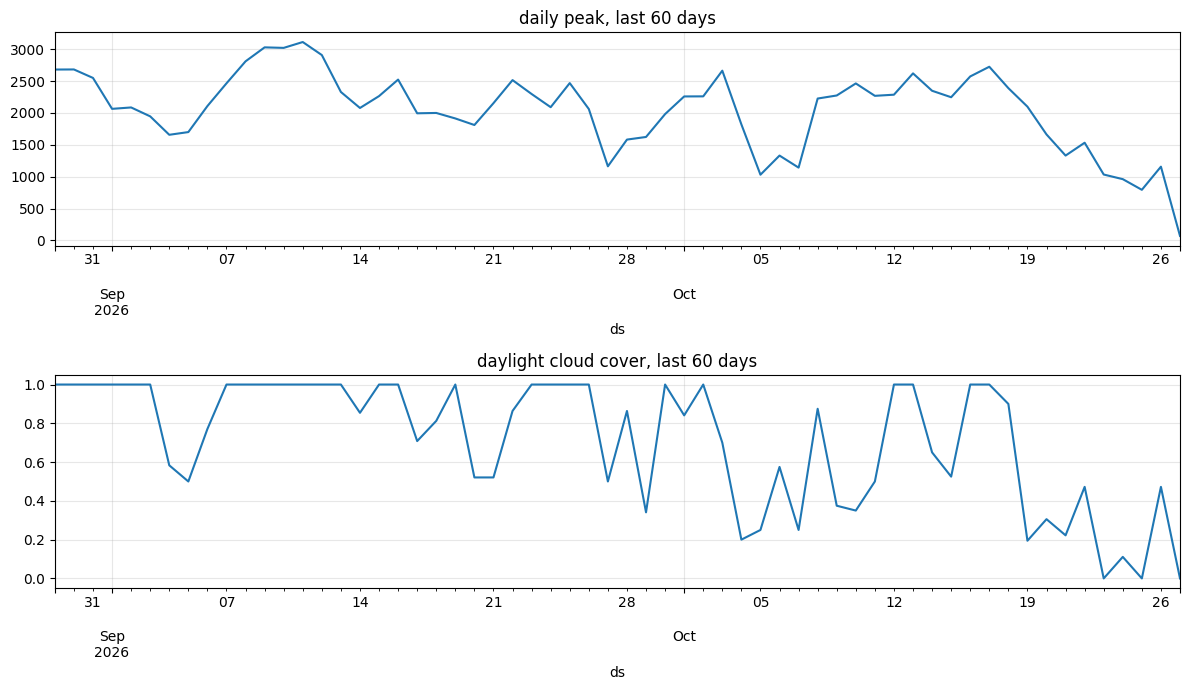

In [ ]:
#Cell 4: trend and level
g = d.groupby(d.index.normalize())
daily = pd.DataFrame({
    "peak": g.y.max(), "mean": g.y.mean(),
    "cloud_dl": g.apply(lambda x: (x.cloud_cover * x.daylight).sum() / max(1, x.daylight.sum())),
    "night_mean": g.apply(lambda x: x.y[x.daylight == 0].mean())})
for col in ["peak", "cloud_dl", "night_mean"]:
    tab = pd.DataFrame({yr: daily.loc[f"{yr}-10-13":f"{yr}-10-26", col].values for yr in [2023, 2024, 2025, 2026]},
                       index=range(13, 27))
    print(f"\n{col}, 13-26 Oct (rows = day of month):"); print(tab.round(2 if col == "cloud_dl" else 0).to_string())

# ratio of the next-day means to lv7, origins 15 Oct - 10 Nov per year
rows = []
for i in origins:
    ts = idx[i]
    if (ts.month == 10 and ts.day >= 15) or (ts.month == 11 and ts.day <= 10):
        lv7 = yarr[i - 167:i + 1].mean()
        rows.append(dict(year=ts.year, lv1r=yarr[i - 23:i + 1].mean() / lv7,
                         d1=yarr[i + 1:i + 25].mean() / lv7, d2=yarr[i + 25:i + 49].mean() / lv7))
R = pd.DataFrame(rows)
print("\nautumn origins, mean(next day)/lv7 by year (n per year, quantiles):")
print(R.groupby("year")[["d1", "d2"]].describe(percentiles=[.1, .5, .9]).round(2).T.to_string())

lv7 = yarr[-168:].mean()
print("\ncurrent: lv1/lv7=%.2f | lv3/lv7=%.2f | lv14/lv7=%.2f" %
      (yarr[-24:].mean() / lv7, yarr[-72:].mean() / lv7, yarr[-336:].mean() / lv7))
print("current public file: day1 mean/lv7=%.2f | day2 mean/lv7=%.2f" %
      (pub.forecast[:24].mean() / lv7, pub.forecast[24:].mean() / lv7))

# momentum: does lv1/lv7 predict the next days, over ALL origins?
allr = pd.DataFrame([dict(lv1r=yarr[i - 23:i + 1].mean() / yarr[i - 167:i + 1].mean(),
                          d1=yarr[i + 1:i + 25].mean() / yarr[i - 167:i + 1].mean(),
                          d2=yarr[i + 25:i + 49].mean() / yarr[i - 167:i + 1].mean()) for i in origins])
allr["bin"] = pd.cut(allr.lv1r, [0, .6, .8, 1.0, 1.2, 1.5, 10])
print("\nall origins, median next-day ratio by lv1/lv7 bin:")
print(allr.groupby("bin", observed=True).agg(n=("d1", "size"), d1=("d1", "median"), d2=("d2", "median")).round(2).to_string())

fig, ax = plt.subplots(2, 1, figsize=(12, 7))
daily["peak"].iloc[-60:].plot(ax=ax[0], title="daily peak, last 60 days")
daily["cloud_dl"].iloc[-60:].plot(ax=ax[1], title="daylight cloud cover, last 60 days")
plt.tight_layout(); plt.show()

In [ ]:
# cell 5 clock and daylight audit
def stats_for(df, with_y=True):
    rows = []
    for dt, g in df.groupby(df.index.normalize()):
        hrs = g.index.hour.values
        dlh = hrs[g.daylight.values == 1]
        r = dict(date=dt, n=len(g),
                 dl_first=dlh.min() if len(dlh) else np.nan, dl_last=dlh.max() if len(dlh) else np.nan)
        if with_y and g.y.max() > 0:
            yy = g.y.values; act = hrs[yy > 0.10 * yy.max()]
            r.update(y_first=act.min(), y_last=act.max(), y_peak_hr=hrs[yy.argmax()],
                     y_centroid=round((hrs * yy).sum() / yy.sum(), 2), peak=round(yy.max()))
        rows.append(r)
    return pd.DataFrame(rows).set_index("date")

st = stats_for(d)
print("LAST 14 DAYS (train):\n", st.iloc[-14:].to_string())
wfd = weather_fc.set_index("ds")[W]
print("\nFORECAST DAYS:\n", stats_for(wfd, with_y=False).to_string())

# dates where BOTH ends of the daylight window move by exactly 1 hour in the same direction (DST-like jumps)
a, b = st.dl_first.diff(), st.dl_last.diff()
both = (a.abs() == 1) & (b.abs() == 1) & (a == b)
print("\nDST-like daylight jumps in train:\n", st.loc[both, ["dl_first", "dl_last", "y_centroid"]].to_string())

for lo_, hi_ in [("2023-10-22", "2023-11-02"), ("2024-10-21", "2024-11-01"), ("2025-10-20", "2025-10-31")]:
    print("\n", lo_, "->", hi_); print(st.loc[lo_:hi_, ["dl_first", "dl_last", "y_first", "y_last", "y_peak_hr", "y_centroid"]].to_string())

LAST 14 DAYS (train):
              n  dl_first  dl_last  y_first  y_last  y_peak_hr  y_centroid  peak
date                                                                           
2026-10-14  24       8.0     17.0        8      17         13       12.63  2347
2026-10-15  24       8.0     17.0        8      17         14       13.28  2245
2026-10-16  24       8.0     17.0        3      23         13       13.36  2572
2026-10-17  24       8.0     17.0        0      23         12       11.15  2724
2026-10-18  24       8.0     17.0        8      17         13       11.96  2388
2026-10-19  24       8.0     16.0        8      17         14       12.90  2098
2026-10-20  24       8.0     16.0        8      17         13       12.82  1662
2026-10-21  24       8.0     16.0        7      23         13       13.44  1330
2026-10-22  24       8.0     16.0        0      17         14       12.49  1532
2026-10-23  24       8.0     16.0        9      17         13       12.78  1033
2026-10-24  24   

In [ ]:
dday = d.copy(); dday["date"] = dday.index.normalize()
def dlm(g, c): return (g[c] * g.daylight).sum() / max(1, g.daylight.sum())
agg = dday.groupby("date").apply(lambda g: pd.Series({
    "peak": g.y.max(), "cloud": dlm(g, "cloud_cover"), "hum": dlm(g, "humidity"), "wind": dlm(g, "wind_speed"),
    "pres": g.pressure.mean(), "temp": g.temperature.mean()}))
agg["ref3"] = agg.peak.shift(1).rolling(3).mean()          # mean peak of the previous 3 days (known at forecast time)
agg["ratio"] = agg.peak / agg.ref3
sel = agg[(agg.index.dayofyear >= 258) & (agg.index.dayofyear <= 335)].dropna()   # ~15 Sep - 30 Nov, all years
print("n days:", len(sel), "| median ratio:", round(sel.ratio.median(), 2))
print("\nSpearman of ratio with weather:\n", sel[["cloud", "hum", "wind", "pres", "temp"]].corrwith(sel.ratio, method="spearman").round(2).to_string())

sel = sel.assign(cl=pd.cut(sel.cloud, [-.01, .4, .9, 1.01], labels=["clear<.4", "mid", "overcast>.9"]),
                 hu=pd.cut(sel.hum, [0, 90, 97, 101], labels=["<90", "90-97", ">97"]))
q = lambda s: pd.Series({"n": len(s), "p10": s.quantile(.1), "p50": s.median(), "p90": s.quantile(.9)})
print("\nratio by cloud:\n", sel.groupby("cl", observed=True).ratio.apply(q).unstack().round(2).to_string())
print("\nratio by humidity:\n", sel.groupby("hu", observed=True).ratio.apply(q).unstack().round(2).to_string())
print("\nratio by cloud x humidity (median, n):")
print(sel.pivot_table(index="cl", columns="hu", values="ratio", aggfunc=["median", "size"], observed=True).round(2).to_string())

ref3_now = d.groupby(d.index.normalize()).y.max().iloc[-4:-1].mean()
print("\nref3 now (peaks of 24-26 Oct): %.0f | model day1 peak/ref3 = %.2f | day2 peak/ref3 = %.2f"
      % (ref3_now, 1217 / ref3_now, 1052 / ref3_now))

wfd = weather_fc.set_index("ds")
print("\nPRESSURE: share of train hours <=758: all %.3f | Oct-Nov %.3f | forecast hours <=758: %d of 48"
      % ((d.pressure <= 758).mean(), (d[d.index.month.isin([10, 11])].pressure <= 758).mean(), int((wfd.pressure <= 758).sum())))
print("train pressure quantiles (all):\n", d.pressure.quantile([.005, .01, .05, .5]).to_string())
print("TEMP>=18: train Oct-Nov share %.3f | forecast hours: %d" %
      ((d[d.index.month.isin([10, 11])].temperature >= 18).mean(), int((wfd.temperature >= 18).sum())))

n days: 277 | median ratio: 0.98

Spearman of ratio with weather:
 cloud    0.11
hum     -0.09
wind     0.46
pres    -0.14
temp     0.05

ratio by cloud:
                  n   p10   p50   p90
cl                                  
clear<.4     117.0  0.56  0.94  1.53
mid           83.0  0.71  1.02  1.44
overcast>.9   77.0  0.74  1.00  1.36

ratio by humidity:
            n   p10   p50   p90
hu                            
<90    238.0  0.66  0.98  1.46
90-97   33.0  0.49  0.97  1.34
>97      5.0  0.70  1.07  1.38

ratio by cloud x humidity (median, n):
            median              size           
hu             <90 90-97   >97   <90 90-97  >97
cl                                             
clear<.4      0.94  0.91  1.07  80.0  31.0  5.0
mid           1.01  1.31   NaN  81.0   2.0  NaN
overcast>.9   1.00   NaN   NaN  77.0   NaN  NaN

ref3 now (peaks of 24-26 Oct): 970 | model day1 peak/ref3 = 1.25 | day2 peak/ref3 = 1.08

PRESSURE: share of train hours <=758: all 0.591 | Oct-Nov 0.310 |

#### current models

In [ ]:
####

In [ ]:
#Cell 7: recent bias of the current model (out-of-sample, by block)
rows = []
for o in [int(x) for x in OR[-12:]]:
    y_ = yarr[o+1:o+49]; p_ = P8["lgbm_nzW"][o]; s_ = P8["snaive"][o]; m_ = P8["mean3"][o]
    night = Warr[o+1:o+49, WI["daylight"]] == 0
    r = dict(origin=str(idx[o])[:10], lv7=round(yarr[o-167:o+1].mean()))
    for nm, sl in [("d1", slice(0, 24)), ("d2", slice(24, 48))]:
        nt = night[sl]
        r.update({f"{nm}_mean_act": y_[sl].mean(), f"{nm}_mean_lgbm": p_[sl].mean(), f"{nm}_mean_snaive": s_[sl].mean(),
                  f"{nm}_peak_act": y_[sl].max(), f"{nm}_peak_lgbm": p_[sl].max(),
                  f"{nm}_night_act": y_[sl][nt].mean(), f"{nm}_night_lgbm": p_[sl][nt].mean()})
    rows.append(r)
T = pd.DataFrame(rows).set_index("origin")
print(T.round(0).astype(int).T.to_string())
print("\nsum(pred)/sum(actual), last 12 origins: d1 mean %.2f | d2 mean %.2f | d1 night %.2f | d2 night %.2f" % (
    T.d1_mean_lgbm.sum() / T.d1_mean_act.sum(), T.d2_mean_lgbm.sum() / T.d2_mean_act.sum(),
    T.d1_night_lgbm.sum() / T.d1_night_act.sum(), T.d2_night_lgbm.sum() / T.d2_night_act.sum()))

# bias by block, day 2, daylight hours vs night hours (night x0.8 already inside the predictions)
lowset = set(low); out = []
for b, bl in enumerate(blocks8):
    for nm, sub_ in [("all", [int(o) for o in bl]), ("low", [int(o) for o in bl if int(o) in lowset])]:
        if not sub_: continue
        A = np.concatenate([yarr[o+25:o+49] for o in sub_]); Pp = np.concatenate([P8["lgbm_nzW"][o][24:] for o in sub_])
        N = np.concatenate([Warr[o+25:o+49, WI["daylight"]] == 0 for o in sub_])
        out.append(dict(block=b, start=str(idx[int(bl[0])])[:10], subset=nm, n_orig=len(sub_),
                        day_ratio=Pp[~N].sum() / A[~N].sum(), night_ratio=Pp[N].sum() / A[N].sum(),
                        night_actual_mean=A[N].mean(), night_pred_mean=Pp[N].mean()))
print("\n", pd.DataFrame(out).round(2).to_string(index=False))

origin          2026-10-14  2026-10-15  2026-10-16  2026-10-17  2026-10-18  2026-10-19  2026-10-20  2026-10-21  2026-10-22  2026-10-23  2026-10-24  2026-10-25
lv7                    807         811         783         826         867         859         818         746         722         689         573         451
d1_mean_act            627         618        1101        1139         704         560         474         455         389         287         289         256
d1_mean_lgbm           594         536         638         700         625         484         456         448         439         348         305         373
d1_mean_snaive         980         627         618        1101        1139         704         560         474         455         389         287         289
d1_peak_act           2347        2245        2572        2724        2388        2098        1662        1330        1532        1033         960         793
d1_peak_lgbm          1807        1704        

In [ ]:
M = d["y"].groupby([d.index.normalize(), d.index.hour]).first().unstack().dropna()   # full 24h days only
prof_day = M.div(M.mean(axis=1), axis=0)                                           # y / daily mean, by hour

a, b = st.dl_first.diff(), st.dl_last.diff()
jumps = st.index[((a.abs() == 1) & (b.abs() == 1) & (a == b)).values]

def best_shift(pb, pa, rng=range(-2, 3)):
    hrs = np.arange(3, 22)
    sse = {s: float(((pa[hrs] - np.roll(pb, s)[hrs]) ** 2).sum()) for s in rng}
    return min(sse, key=sse.get), sse

rows, PR = [], {}
for t in jumps:
    bef = prof_day.loc[t - pd.Timedelta(days=9): t - pd.Timedelta(days=3)]     # 7 days before, skipping the jump +-2 days
    aft = prof_day.loc[t + pd.Timedelta(days=2): t + pd.Timedelta(days=8)]
    if len(bef) < 5 or len(aft) < 5:
        continue
    pb, pa = bef.median().values, aft.median().values
    s, sse = best_shift(pb, pa)
    fs = int(st.dl_first.loc[t + pd.Timedelta(days=2)] - st.dl_first.loc[t - pd.Timedelta(days=3)])
    rows.append(dict(jump=str(t)[:10], flag_shift=fs, y_shift=s, n_bef=len(bef), n_aft=len(aft),
                     sse_m1=sse[-1], sse_0=sse[0], sse_p1=sse[1]))
    PR[str(t)[:10]] = (pb, pa)
print(pd.DataFrame(rows).round(3).to_string(index=False))

hrs = list(range(5, 20))
print("\nhours:", hrs)
for k_, (pb, pa) in PR.items():
    print(k_, "before:", np.round(pb[hrs], 2))
    print(" " * len(k_), "after :", np.round(pa[hrs], 2))

      jump  flag_shift  y_shift  n_bef  n_aft  sse_m1  sse_0  sse_p1
2023-04-01           1        1      7      7   6.048  2.602   1.049
2023-10-28          -1       -1      7      7   1.311  1.437   1.868
2024-03-31           1        0      7      7   1.649  0.737   1.243
2024-10-27          -1       -1      7      7   5.189  5.760   6.958
2025-03-31           1        0      7      7   3.468  1.693   1.898
2025-10-27          -1        0      7      7   2.398  2.241   4.239
2026-03-31           1        1      7      7   3.371  0.730   0.356

hours: [5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
2023-04-01 before: [0.41 0.36 0.81 1.04 1.41 1.65 2.29 2.39 1.78 2.17 1.55 1.29 1.29 0.79
 0.43]
           after : [0.26 0.32 0.37 0.58 0.98 1.14 1.52 1.77 1.9  2.1  2.22 1.7  1.38 0.9
 0.58]
2023-10-28 before: [0.94 0.9  0.84 0.87 1.   1.09 1.18 1.3  1.26 1.25 1.16 1.13 0.97 0.96
 0.91]
           after : [0.62 0.51 0.52 0.91 1.07 1.13 1.55 1.69 1.69 1.36 1.02 0.61 0.72 0.8
 0.88

In [ ]:
# ---- 1) is the model lagging in falling regimes? (existing out-of-sample predictions, 240 origins)
names = ["lgbm_nzW", "mean3", "snaive", "chr336"]
O_ = [int(x) for x in OR]
ACT = np.array([yarr[o+1:o+49] for o in O_])
PRD = {nm: np.array([np.asarray(P8[nm][o]) for o in O_]) for nm in names}
fall = np.array([yarr[o-335:o+1].mean() / yarr[o-167:o+1].mean() for o in O_])   # lv14/lv7 (now: 1.63)
bins = pd.cut(pd.Series(fall), [0, .9, 1.1, 1.3, 1.5, 10])
rows = []
for bn in bins.cat.categories:
    m = (bins == bn).values
    if m.sum() == 0:
        continue
    r = dict(lv14_over_lv7=str(bn), n=int(m.sum()))
    for nm in names:
        r[nm + "_d1"] = PRD[nm][m, :24].sum() / ACT[m, :24].sum()
        r[nm + "_d2"] = PRD[nm][m, 24:].sum() / ACT[m, 24:].sum()
        r[nm + "_rmse2"] = float(np.sqrt(((PRD[nm][m, 24:] - ACT[m, 24:]) ** 2).mean()))
    rows.append(r)
print("sum(pred)/sum(actual) by regime, and raw RMSE on day 2:")
print(pd.DataFrame(rows).round(2).T.to_string())
m = fall > 1.3
print("\norigins with lv14/lv7 > 1.3:", int(m.sum()), "| dates:", [str(idx[o])[:10] for o, f in zip(O_, m) if f][:20])

# ---- 2) current forecasts from different models (level comparison)
i0 = n - 1
nightf = weather_fc.daylight.values == 0
cur = {"public file (lgbm)": pub.forecast.values, "snaive": np.asarray(snaive(yarr[:i0+1])[0]),
       "mean3": np.asarray(mean3_fc(i0))}
try:
    cur["chr336"] = np.asarray(chronos_fc(i0, 336))
except Exception as e:
    print("chronos failed:", e)
rows = []
for nm, p in cur.items():
    rows.append(dict(model=nm, d1_mean=p[:24].mean(), d1_peak=p[:24].max(), d2_mean=p[24:].mean(), d2_peak=p[24:].max(),
                     d1_night=p[:24][nightf[:24]].mean(), d2_night=p[24:][nightf[24:]].mean()))
print("\n", pd.DataFrame(rows).round(0).to_string(index=False))
nl = (d.daylight.iloc[-72:].values == 0)
print("reference actual: mean last 24h %.0f | mean last 72h %.0f | peak last 3 days %s | night mean last 72h %.0f"
      % (yarr[-24:].mean(), yarr[-72:].mean(), [round(yarr[-72+24*j:-48+24*j or None].max()) for j in range(3)], yarr[-72:][nl].mean()))

# ---- 3) how much does the public-file model rely on wind? and top features
fut = pd.DatetimeIndex(FUTURE)
for dw in [-2, -1, 0, 1]:
    wx = weather_fc[W].to_numpy(float).copy()
    wx[:, WI["wind_speed"]] = np.clip(wx[:, WI["wind_speed"]] + dw, 0, None)
    Xs_, lv_ = rows2(n - 1, wx, fut)
    p_ = pred2(ms_f, Xs_) * lv_ * np.where(wx[:, WI["daylight"]] == 0, 0.8, 1.0)
    print("wind %+d -> peak d1 %.0f | peak d2 %.0f | mean d1 %.0f | mean d2 %.0f" % (dw, p_[:24].max(), p_[24:].max(), p_[:24].mean(), p_[24:].mean()))
fn = ["hour", "doy", "k", "h"] + W + ["lag1", "lag2", "lag3", "lv1", "lv3", "lv14", "pk1", "pk3", "mn1", "last", "cc_dl", "wind_dl"]
gain = np.mean([mm.booster_.feature_importance(importance_type="gain") for mm in ms_f], axis=0)
print("\nfeature gain share, top 12:\n", pd.Series(gain / gain.sum(), index=fn).sort_values(ascending=False).round(3).head(12).to_string())

sum(pred)/sum(actual) by regime, and raw RMSE on day 2:
                         0           1           2           3            4
lv14_over_lv7   (0.0, 0.9]  (0.9, 1.1]  (1.1, 1.3]  (1.3, 1.5]  (1.5, 10.0]
n                       37         159          39           3            2
lgbm_nzW_d1           0.98        0.96         1.0        0.94         0.86
lgbm_nzW_d2            1.0        0.97        1.01         0.8         0.78
lgbm_nzW_rmse2      201.92      228.29      269.53      346.64       395.39
mean3_d1              1.13         1.0        0.89        0.87         0.66
mean3_d2              1.18         1.0        0.89        0.67         0.51
mean3_rmse2         290.14       275.1       313.4      410.23       561.09
snaive_d1             1.09         1.0        0.92        1.18         0.61
snaive_d2             1.14         1.0        0.92        0.91         0.47
snaive_rmse2        308.27      289.84      323.65      261.36       620.88
chr336_d1             0.97      

#### LGBM: continue

In [ ]:
#Cell 10: вікна навчання

low = sorted(low)
WINDOWS = {"full+hl180 (current)": None, "365d": 365, "180d": 180, "90d": 90, "45d": 45}

# sanity: number of training origins per block for each window
for nm, rec in WINDOWS.items():
    cnt = []
    for bl in blocks8:
        m = O_all < bl[0] - 48
        if rec:
            m &= O_all >= bl[0] - 48 - 24 * rec
        cnt.append(int(m.sum() // 48))
    print(f"{nm:24s} training origins per block: min {min(cnt)}, max {max(cnt)}")

PW, rows_w = {}, []
for nm, rec in WINDOWS.items():
    PW[nm] = lgbm_cv(recent=rec)                      # cols=ALL, half_life=180, seeds=(0, 1)
    r_low, r_all = row(PW[nm], low), row(PW[nm], [int(o) for o in OR])
    rows_w.append(dict(window=nm, **{k_ + "_low": v_ for k_, v_ in r_low.items()},
                       RMSE_all=r_all["RMSE"], MAPE_all=r_all["MAPE"], Wink_all=r_all["Wink"]))
    print("done", nm)
print(pd.DataFrame(rows_w).round(2).to_string(index=False))
print("earlier references: base 236.31/78.91/1151.91/0.94 | recent365 228.83/73.61/1085.86/0.95")

base = PW["full+hl180 (current)"]
OR_ = [int(o) for o in OR]
for nm in list(WINDOWS)[1:]:
    print(f"\ncurrent minus {nm} (positive = window better) | subset low:")
    paired(base, PW[nm], low)
    print(f"current minus {nm} | all 240:")
    paired(base, PW[nm], OR_)

half = len(low) // 2
for nm in WINDOWS:
    a_ = {k_: round(v_, 1) for k_, v_ in row(PW[nm], low[:half]).items()}
    b_ = {k_: round(v_, 1) for k_, v_ in row(PW[nm], low[half:]).items()}
    print(f"{nm:24s} low first half {a_} | second half {b_}")

full+hl180 (current)     training origins per block: min 1143, max 1353
365d                     training origins per block: min 365, max 365
180d                     training origins per block: min 180, max 180
90d                      training origins per block: min 90, max 90
45d                      training origins per block: min 45, max 45
done full+hl180 (current)
done 365d
done 180d
done 90d
done 45d
              window  RMSE_low  MAPE_low  Wink_low  cov_low  RMSE_all  MAPE_all  Wink_all
full+hl180 (current)    236.31     78.91   1151.91     0.94    234.25     93.20   1288.26
                365d    228.83     73.61   1085.86     0.95    231.37     90.07   1255.27
                180d    233.11     84.63   1122.32     0.95    239.89    116.10   1269.28
                 90d    238.53     91.20   1191.30     0.94    244.84    128.93   1317.78
                 45d    258.14     97.55   1363.85     0.93    261.33    137.83   1434.34
earlier references: base 236.31/78.91/1151.91/0.

In [ ]:
# cell 11 nigt generation and wind
dd = d.copy()
dd["date"] = (dd.index - pd.Timedelta(hours=1)).normalize()     # day = 01:00..00:00, as in the model
night = dd[dd.daylight == 0]
agg = night.groupby("date").agg(night_y=("y", "mean"), night_med=("y", "median"), night_wind=("wind_speed", "mean"),
                                night_cloud=("cloud_cover", "mean"), night_hum=("humidity", "mean"), n=("y", "size"))
agg = agg[agg.n >= 12]
daily_mean = dd.groupby("date").y.mean()
agg["rel"] = agg.night_y / daily_mean.rolling(7).mean().shift(1).reindex(agg.index)   # night / previous-7-day daily mean

q = [.1, .25, .5, .75, .9]
for nm, sel in [("2026 Mar-Oct", agg.loc["2026-03-01":]), ("2026 Sep-Oct", agg.loc["2026-09-01":]),
                ("all years Sep-Nov", agg[agg.index.month.isin([9, 10, 11])])]:
    s = sel.dropna(subset=["rel"])
    print(f"\n{nm}: n={len(s)}")
    print(" night_y quantiles", q, s.night_y.quantile(q).round(0).values)
    print(" rel quantiles       ", s.rel.quantile(q).round(2).values, "| share night_y>300:", round((s.night_y > 300).mean(), 2))
    print(" Spearman of rel with:", s[["night_wind", "night_cloud", "night_hum"]].corrwith(s.rel, method="spearman").round(2).to_dict())
    wb = pd.cut(s.night_wind, [-.1, 1, 2, 3, 10])
    print(s.groupby(wb, observed=True).rel.agg(n="size", med="median", p90=lambda x: x.quantile(.9)).round(2).to_string())

print("\nlast 20 days:")
print(agg[["night_y", "night_med", "night_wind", "night_cloud", "night_hum", "rel"]].tail(20).round(2).to_string())

wfn = weather_fc.set_index("ds"); nn = wfn[wfn.daylight == 0]
print("\nforecast nights, mean wind/cloud/humidity by day:")
print(nn.groupby((nn.index - pd.Timedelta(hours=1)).normalize())[["wind_speed", "cloud_cover", "humidity"]].mean().round(2).to_string())


2026 Mar-Oct: n=111
 night_y quantiles [0.1, 0.25, 0.5, 0.75, 0.9] [ 91. 171. 318. 410. 536.]
 rel quantiles        [0.12 0.26 0.43 0.55 0.69] | share night_y>300: 0.53
 Spearman of rel with: {'night_wind': 0.63, 'night_cloud': 0.25, 'night_hum': -0.24}
              n   med   p90
night_wind                 
(1.0, 2.0]   20  0.13  0.35
(2.0, 3.0]   50  0.42  0.58
(3.0, 10.0]  41  0.57  0.82

2026 Sep-Oct: n=56
 night_y quantiles [0.1, 0.25, 0.5, 0.75, 0.9] [ 84. 161. 323. 411. 556.]
 rel quantiles        [0.11 0.22 0.36 0.49 0.69] | share night_y>300: 0.57
 Spearman of rel with: {'night_wind': 0.56, 'night_cloud': 0.42, 'night_hum': -0.35}
              n   med   p90
night_wind                 
(1.0, 2.0]   14  0.13  0.36
(2.0, 3.0]   27  0.42  0.68
(3.0, 10.0]  15  0.47  0.69

all years Sep-Nov: n=329
 night_y quantiles [0.1, 0.25, 0.5, 0.75, 0.9] [ 44.  81. 172. 284. 361.]
 rel quantiles        [0.15 0.31 0.6  0.95 1.31] | share night_y>300: 0.22
 Spearman of rel with: {'night_wind'

In [ ]:
low = sorted(low); OR_ = [int(o) for o in OR]
C_CLOUD, C_WIND, C_HUM, C_DL = 4 + WI["cloud_cover"], 4 + WI["wind_speed"], 4 + WI["humidity"], 4 + WI["daylight"]
assert (C_CLOUD, C_WIND, C_HUM, C_DL) == (4, 6, 8, 9)

def aug(X, variant):
    """A: unchanged. B: + night-mean wind and 24h-mean wind of the target day-block.
       C: + night-mean wind, cloud, humidity. Day-block = rows 0:24 (day 1) and 24:48 (day 2), per origin."""
    if variant == "A":
        return X
    R = X.reshape(-1, 48, X.shape[1]); blocks = []
    for sl in (slice(0, 24), slice(24, 48)):
        nt = (R[:, sl, C_DL] == 0); cnt = np.maximum(nt.sum(1), 1)
        f = [(R[:, sl, C_WIND] * nt).sum(1) / cnt]
        if variant == "B":
            f.append(R[:, sl, C_WIND].mean(1))
        if variant == "C":
            f += [(R[:, sl, C_CLOUD] * nt).sum(1) / cnt, (R[:, sl, C_HUM] * nt).sum(1) / cnt]
        blocks.append(np.repeat(np.column_stack(f)[:, None, :], 24, axis=1))
    m = blocks[0].shape[2]
    return np.hstack([X, np.concatenate(blocks, axis=1).reshape(-1, m)])

print("shapes:", {v: aug(X2_all, v).shape for v in "ABC"}, "| NaN:", {v: int(np.isnan(aug(X2_all, v)).sum()) for v in "ABC"})

def cv_aug(variant, recent=365, half_life=180, seeds=(0, 1)):
    Xtr_all = aug(X2_all, variant); out = {}
    for bl in blocks8:
        mask = (O_all < bl[0] - 48) & (O_all >= bl[0] - 48 - 24 * recent)
        w = L_all[mask] * 0.5 ** ((bl[0] - O_all[mask]) / (24 * half_life))
        ms = [lgb.LGBMRegressor(**BASE, random_state=s, verbose=-1).fit(Xtr_all[mask], Y_all[mask], sample_weight=w) for s in seeds]
        for o in bl:
            o = int(o); Xn, lv = XN[o]; Xa = aug(Xn, variant)
            p = np.mean([m.predict(Xa) for m in ms], axis=0)
            out[o] = np.clip(p, 0, None) * lv * NT[o]
    return out

PV = {v: cv_aug(v) for v in "ABC"}
print("repro check, A vs earlier 365d, max abs diff:", max(float(np.abs(PV["A"][o] - PW["365d"][o]).max()) for o in OR_), "(should be ~0)")

def split(Pn, subset):
    A_, P_, N_ = [], [], []
    for o in subset:
        A_.append(yarr[o+25:o+49]); P_.append(Pn[o][24:]); N_.append(Warr[o+25:o+49, WI["daylight"]] == 0)
    A_, P_, N_ = map(np.concatenate, (A_, P_, N_))
    return dict(RMSE_night=rmse(A_[N_], P_[N_]), MAPE_night=mape(A_[N_], P_[N_]), ratio_night=P_[N_].sum() / A_[N_].sum(),
                RMSE_day=rmse(A_[~N_], P_[~N_]), MAPE_day=mape(A_[~N_], P_[~N_]), ratio_day=P_[~N_].sum() / A_[~N_].sum())

rows = []
for v in PV:
    for nm, sub_ in [("low", low), ("all", OR_)]:
        rows.append(dict(variant=v, subset=nm, **row(PV[v], sub_), **split(PV[v], sub_)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

for v in ["B", "C"]:
    for nm, sub_ in [("low", low), ("all 240", OR_)]:
        print(f"\nA minus {v} (positive = {v} better) | {nm}"); paired(PV["A"], PV[v], sub_)
half = len(low) // 2
for v in PV:
    print(v, "low 1st half", {a: round(b, 1) for a, b in row(PV[v], low[:half]).items()},
             "| 2nd half", {a: round(b, 1) for a, b in row(PV[v], low[half:]).items()})

# diagnostic (clean-trained, 365d, decay ref = n): what each variant forecasts now. Not the final fit.
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(n - 1, wx_f, fut); dl_f = wx_f[:, WI["daylight"]]
mask_f = O_all >= n - 48 - 24 * 365
wf = L_all[mask_f] * 0.5 ** ((n - O_all[mask_f]) / (24 * 180))
out = []
for v in "ABC":
    ms = [lgb.LGBMRegressor(**BASE, random_state=s, verbose=-1).fit(aug(X2_all, v)[mask_f], Y_all[mask_f], sample_weight=wf) for s in (0, 1, 2)]
    p = np.clip(np.mean([m.predict(aug(X_f, v)) for m in ms], axis=0), 0, None) * lv_f * np.where(dl_f == 0, 0.8, 1.0)
    out.append(dict(variant=v, d1_mean=p[:24].mean(), d1_peak=p[:24].max(), d1_night=p[:24][dl_f[:24] == 0].mean(),
                    d2_mean=p[24:].mean(), d2_peak=p[24:].max(), d2_night=p[24:][dl_f[24:] == 0].mean()))
print("\nforecast now:\n", pd.DataFrame(out).round(0).to_string(index=False))
print("public file for reference: d1 440/1217/198 | d2 379/1052/168 (mean/peak/night)")

shapes: {'A': (66480, 23), 'B': (66480, 25), 'C': (66480, 26)} | NaN: {'A': 0, 'B': 0, 'C': 0}
repro check, A vs earlier 365d, max abs diff: 0.0 (should be ~0)
variant subset   RMSE  MAPE    Wink  cov  RMSE_night  MAPE_night  ratio_night  RMSE_day  MAPE_day  ratio_day
      A    low 228.83 73.61 1085.86 0.95      148.47      121.81         0.93    284.79     27.92       0.92
      A    all 231.37 90.07 1255.27 0.97      168.66      161.49         0.95    274.38     28.13       0.98
      B    low 229.61 74.87 1102.40 0.95      149.82      123.95         0.92    285.33     28.35       0.93
      B    all 234.85 90.45 1285.87 0.97      171.08      161.82         0.94    278.57     28.57       0.98
      C    low 232.95 71.75 1104.55 0.95      150.08      117.53         0.92    290.43     28.36       0.91
      C    all 236.97 87.02 1288.53 0.97      171.98      154.28         0.94    281.42     28.69       0.97

A minus B (positive = B better) | low
dRMSE: -0.8  95% [-4.7, +2.8]
dMAPE: -

In [ ]:
# Cell 13: множник ночі та діагностика залишків
low = sorted(low); OR_ = [int(o) for o in OR]
RAW = {o: PV["A"][o] / NT[o] for o in OR_}                       # A without the night multiplier
def with_c(c): return {o: RAW[o] * np.where(NT[o] < 1, c, 1.0) for o in OR_}
PC = {c: with_c(c) for c in [1.0, 0.8, 0.65]}
print("repro, c=0.8 vs PV['A'], max abs diff:", max(float(np.abs(PC[0.8][o] - PV["A"][o]).max()) for o in OR_))

rows = []
for c in PC:
    for nm, sub_ in [("low", low), ("all", OR_)]:
        rows.append(dict(night_mult=c, subset=nm, **row(PC[c], sub_)))
print(pd.DataFrame(rows).round(2).to_string(index=False))
for c in [1.0, 0.65]:
    for nm, sub_ in [("low", low), ("all 240", OR_)]:
        print(f"\n0.8 minus {c} (positive = {c} better) | {nm}"); paired(PC[0.8], PC[c], sub_)

# diagnostics on day 2: errors by hour (low) and residual scale by lv7 bin
x = ev_df(PC[0.8], 1.0)
x = x.assign(res=x.y - x.pred, hour=(x.groupby("o").cumcount() + 1) % 24)
xl = x[x.o.isin(low)].copy()
xl["width"] = xl.hi - xl.lo
xl["cover"] = ((xl.y >= xl.lo) & (xl.y <= xl.hi)).astype(float)
xl["pen"] = 40 * (np.clip(xl.lo - xl.y, 0, None) + np.clip(xl.y - xl.hi, 0, None))
xl["ape"] = (xl.y - xl.pred).abs() / xl.y.clip(lower=1) * 100
print("\nby hour of day, low, day 2 (width and cover at wide 1.0):")
print(xl.groupby("hour")[["y", "pred", "width", "cover", "pen", "ape"]].mean().round(1).to_string())

x["lvbin"] = pd.cut(x.lv, [0, 450, 726, 1e9]); x["night"] = x.dl == 0
qs = lambda s: pd.Series({"n": len(s), "q2.5": s.quantile(.025), "q50": s.median(), "q97.5": s.quantile(.975)})
print("\nabsolute residual y - pred by night/lv7 bin (all 240, day 2):")
print(x.groupby(["night", "lvbin"], observed=True).res.apply(qs).unstack().round(0).to_string())
print("\nresidual / lv7:")
print(x.assign(rn=x.res / x.lv).groupby(["night", "lvbin"], observed=True).rn.apply(qs).unstack().round(2).to_string())

repro, c=0.8 vs PV['A'], max abs diff: 0.0
 night_mult subset   RMSE   MAPE    Wink  cov
       1.00    low 233.36  89.73 1092.49 0.95
       1.00    all 236.46 110.42 1253.73 0.97
       0.80    low 228.83  73.61 1085.86 0.95
       0.80    all 231.37  90.07 1255.27 0.97
       0.65    low 232.32  64.03 1083.47 0.95
       0.65    all 234.92  76.83 1259.58 0.97

0.8 minus 1.0 (positive = 1.0 better) | low
dRMSE: -4.5  95% [-9.8, +0.5]
dMAPE: -16.0  95% [-26.2, -7.7]
dWink: -6.8  95% [-23.8, +6.5]

0.8 minus 1.0 (positive = 1.0 better) | all 240
dRMSE: -5.2  95% [-8.8, -1.4]
dMAPE: -20.3  95% [-32.7, -12.1]
dWink: +1.6  95% [-10.8, +11.0]

0.8 minus 0.65 (positive = 0.65 better) | low
dRMSE: -3.5  95% [-6.1, -0.8]
dMAPE: +9.4  95% [+3.2, +17.1]
dWink: +2.4  95% [-6.5, +15.7]

0.8 minus 0.65 (positive = 0.65 better) | all 240
dRMSE: -3.5  95% [-6.3, -0.9]
dMAPE: +13.2  95% [+6.9, +22.5]
dWink: -4.4  95% [-11.3, +4.3]

by hour of day, low, day 2 (width and cover at wide 1.0):
           

In [ ]:
# cell 14: interval schemes (norm vs night_abs vs night_wind), separate day/night widening, LOBO and forward calibration
low = sorted(low); OR_ = [int(o) for o in OR]; PN = PC[0.8]

# night-wind bin per (origin, day): 1 if mean noisy forecast wind over night hours > 2
def wind_bins(o):
    X = XN[o][0]; b = []
    for sl in (slice(0, 24), slice(24, 48)):
        nt = X[sl, 9] == 0
        b.append(int(X[sl, 6][nt].mean() > 2) if nt.any() else 0)
    return np.repeat(b, 24)
WB = np.concatenate([wind_bins(o) for o in OR_])
assert len(WB) == len(mk(PN)), "WB length mismatch"

def ev_int2(Pn, scheme, wd, wn, forward=False):
    df = mk(Pn); df["wb"] = WB; parts = []
    for tb in np.unique(BL):
        tr = df[df.b < tb] if forward else df[df.b != tb]
        if len(tr) == 0:
            continue
        te = df[df.b == tb].copy(); lv = te.lv.to_numpy(); q = calib(tr)
        lo_r = np.array([q[(a, b)][0] for a, b in zip(te.k, te.dl)]) * lv
        hi_r = np.array([q[(a, b)][1] for a, b in zip(te.k, te.dl)]) * lv
        nt = (te.dl == 0).to_numpy()
        if scheme in ("night_abs", "night_wind"):
            tn = tr[tr.dl == 0].copy(); tn["res"] = tn.y - tn.p
            key = (lambda d_: d_.k.astype(int) * 10 + (d_.wb.astype(int) if scheme == "night_wind" else 0))
            tn["key"] = key(tn)
            qa = {g: (s.res.quantile(.025), s.res.quantile(.975)) for g, s in tn.groupby("key")}
            qk = {kk: (tn.res[tn.k == kk].quantile(.025), tn.res[tn.k == kk].quantile(.975)) for kk in (0, 1)}
            kt = key(te).to_numpy()
            lo_n = np.array([qa.get(g, qk[g // 10])[0] for g in kt]); hi_n = np.array([qa.get(g, qk[g // 10])[1] for g in kt])
            lo_r = np.where(nt, lo_n, lo_r); hi_r = np.where(nt, hi_n, hi_r)
        w = np.where(nt, wn, wd); pred = te.p.to_numpy()
        te["pred"] = pred; te["lo"] = np.clip(pred + lo_r * w, 0, None); te["hi"] = pred + hi_r * w
        parts.append(te)
    x = pd.concat(parts); return x[x.k == 1]

def summ(x, sub_):
    x = x[x.o.isin(sub_)]; w = x.hi - x.lo; nt = x.dl == 0
    pen = 40 * (np.clip(x.lo - x.y, 0, None) + np.clip(x.y - x.hi, 0, None)); cv = (x.y >= x.lo) & (x.y <= x.hi)
    return dict(Wink=(w + pen).mean(), width=w.mean(), cov=cv.mean(), cov_n=cv[nt].mean(), cov_d=cv[~nt].mean())

def wo(x, sub_):
    x = x[x.o.isin(sub_)]
    return ((x.hi - x.lo) + 40 * (np.clip(x.lo - x.y, 0, None) + np.clip(x.y - x.hi, 0, None))).groupby(x.o).mean()

def bdiff(a, b, nb=2000, blk=7, seed=0):
    a, b = a.align(b, join="inner"); rng = np.random.default_rng(seed); n_ = len(a); r = []
    for _ in range(nb):
        s_ = rng.integers(0, n_, size=n_ // blk + 1)
        ix = np.concatenate([np.arange(s, s + blk) % n_ for s in s_])[:n_]
        r.append(a.iloc[ix].mean() - b.iloc[ix].mean())
    lo_, hi_ = np.percentile(r, [2.5, 97.5]); return f"{np.mean(r):+.0f} [{lo_:+.0f},{hi_:+.0f}]"

CFG = [("norm", 1.0, 1.0), ("norm", 1.2, 1.2), ("night_abs", 1.2, 1.0), ("night_wind", 1.2, 1.0), ("night_wind", 1.4, 1.0)]
XL = {c: ev_int2(PN, *c) for c in CFG}; XF = {c: ev_int2(PN, *c, forward=True) for c in CFG}
rows = []
for calib_nm, XX in [("LOBO", XL), ("FWD", XF)]:
    for c, x in XX.items():
        for nm, s_ in [("low", low), ("all", OR_)]:
            rows.append(dict(calib=calib_nm, scheme=c[0], wd=c[1], wn=c[2], subset=nm, **summ(x, s_)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

ref = CFG[1]; rows = []
for c in [CFG[0], CFG[2], CFG[3], CFG[4]]:
    rows.append(dict(cand=str(c), low=bdiff(wo(XL[ref], low), wo(XL[c], low)), all240=bdiff(wo(XL[ref], OR_), wo(XL[c], OR_))))
print("\nWinkler: ref", ref, "minus candidate (positive = candidate better), LOBO")
print(pd.DataFrame(rows).to_string(index=False))

x = XL[CFG[3]]; x = x[x.o.isin(low) & (x.dl == 0)]
print("\nnight_wind (1.2, 1.0), low, by night-wind bin:")
print(x.groupby("wb").apply(lambda g: pd.Series(dict(n=len(g), y_mean=g.y.mean(), width=(g.hi - g.lo).mean(),
      cov=((g.y >= g.lo) & (g.y <= g.hi)).mean()))).round(2).to_string())

calib     scheme  wd  wn subset    Wink   width  cov  cov_n  cov_d
 LOBO       norm 1.0 1.0    low 1159.23  727.56 0.91   0.91   0.91
 LOBO       norm 1.0 1.0    all 1225.92  932.95 0.94   0.95   0.94
 LOBO       norm 1.2 1.2    low 1085.86  859.66 0.95   0.95   0.95
 LOBO       norm 1.2 1.2    all 1255.27 1098.26 0.97   0.97   0.97
 LOBO  night_abs 1.2 1.0    low 1069.10  858.90 0.95   0.96   0.95
 LOBO  night_abs 1.2 1.0    all 1233.75 1035.72 0.96   0.95   0.97
 LOBO night_wind 1.2 1.0    low 1063.41  859.38 0.96   0.97   0.95
 LOBO night_wind 1.2 1.0    all 1232.50 1030.40 0.96   0.94   0.97
 LOBO night_wind 1.4 1.0    low 1088.20  949.87 0.97   0.97   0.98
 LOBO night_wind 1.4 1.0    all 1304.19 1149.15 0.97   0.94   0.98
  FWD       norm 1.0 1.0    low 1375.93  821.83 0.89   0.89   0.90
  FWD       norm 1.0 1.0    all 1289.58  990.16 0.95   0.95   0.94
  FWD       norm 1.2 1.2    low 1282.61  967.23 0.94   0.94   0.94
  FWD       norm 1.2 1.2    all 1327.41 1163.32 0.97   0.97   

In [ ]:
# cell 15: sample-weight test on the 365d window (weights lv7 = current, 1, lv7^2), paired vs current
low = sorted(low); OR_ = [int(o) for o in OR]

def cv_w(mode, recent=365, half_life=180, seeds=(0, 1)):
    out = {}
    for bl in blocks8:
        mask = (O_all < bl[0] - 48) & (O_all >= bl[0] - 48 - 24 * recent)
        base_w = {"lv7": L_all[mask], "one": np.ones(mask.sum()), "lv7sq": L_all[mask] ** 2 / L_all[mask].mean()}[mode]
        w = base_w * 0.5 ** ((bl[0] - O_all[mask]) / (24 * half_life))
        ms = [lgb.LGBMRegressor(**BASE, random_state=s, verbose=-1).fit(X2_all[mask], Y_all[mask], sample_weight=w) for s in seeds]
        for o in bl:
            o = int(o); Xn, lv = XN[o]
            out[o] = np.clip(np.mean([m.predict(Xn) for m in ms], axis=0), 0, None) * lv * NT[o]
    return out

PWT = {m: cv_w(m) for m in ["lv7", "one", "lv7sq"]}
print("repro check vs PV['A'], max abs diff:", max(float(np.abs(PWT["lv7"][o] - PV["A"][o]).max()) for o in OR_))

def pcmp(A, B, sub_, wide=1.2, nb=2000, blk=7, seed=0):
    a = per_origin(A, wide).loc[sub_]; b = per_origin(B, wide).loc[sub_]
    rng = np.random.default_rng(seed); n_ = len(a); r = []
    for _ in range(nb):
        s_ = rng.integers(0, n_, size=n_ // blk + 1)
        ix = np.concatenate([np.arange(s, s + blk) % n_ for s in s_])[:n_]
        aa, bb = a.iloc[ix], b.iloc[ix]
        r.append([np.sqrt(aa.se.mean()) - np.sqrt(bb.se.mean()), 100 * (aa.ape.mean() - bb.ape.mean()), aa.w.mean() - bb.w.mean()])
    r = np.array(r); o = {}
    for j, nm in enumerate(["dRMSE", "dMAPE", "dWink"]):
        lo_, hi_ = np.percentile(r[:, j], [2.5, 97.5]); o[nm] = f"{r[:, j].mean():+.1f} [{lo_:+.1f},{hi_:+.1f}]"
    return o

rows = []
for m in PWT:
    for nm, s_ in [("low", low), ("all", OR_)]:
        rows.append(dict(weights=m, subset=nm, **row(PWT[m], s_)))
print(pd.DataFrame(rows).round(2).to_string(index=False))

rows = []
for m in ["one", "lv7sq"]:
    for nm, s_ in [("low", low), ("all", OR_)]:
        rows.append(dict(cmp=f"lv7 minus {m} (positive = {m} better)", subset=nm, **pcmp(PWT["lv7"], PWT[m], s_)))
print(pd.DataFrame(rows).to_string(index=False))

repro check vs PV['A'], max abs diff: 0.0
weights subset   RMSE  MAPE    Wink  cov
    lv7    low 228.83 73.61 1085.86 0.95
    lv7    all 231.37 90.07 1255.27 0.97
    one    low 226.57 73.02 1088.68 0.95
    one    all 230.52 91.15 1258.03 0.97
  lv7sq    low 229.82 73.80 1093.58 0.95
  lv7sq    all 231.82 92.12 1268.38 0.97
                                      cmp subset            dRMSE            dMAPE              dWink
    lv7 minus one (positive = one better)    low +2.2 [-1.4,+5.9] +0.6 [-0.6,+2.0] -3.3 [-28.7,+17.4]
    lv7 minus one (positive = one better)    all +0.8 [-1.7,+3.2] -1.1 [-3.9,+0.9]  -3.1 [-18.7,+9.3]
lv7 minus lv7sq (positive = lv7sq better)    low -1.0 [-3.0,+0.9] -0.2 [-0.9,+0.5]  -7.9 [-22.1,+5.8]
lv7 minus lv7sq (positive = lv7sq better)    all -0.4 [-2.3,+1.5] -2.0 [-7.8,+1.3] -13.1 [-23.8,-4.8]


#### до чого ми прийшли з lightgbm

cand | shape (48,) | NaN 0 | lo<=p<=hi True | lo>=0 True
public | shape (48,) | NaN 0 | lo<=p<=hi True | lo>=0 True
snaive | shape (48,) | NaN 0 | lo<=p<=hi True | lo>=0 True
             d1_mean  d1_peak  d1_night  d1_width  d2_mean  d2_peak  d2_night  d2_width
model                                                                                  
snaive         390.0   1156.0     172.0     521.0    390.0   1156.0     172.0     697.0
public         440.0   1217.0     198.0     549.0    379.0   1052.0     168.0     602.0
candidate A    408.0   1210.0     171.0     426.0    335.0   1022.0     134.0     459.0
mean |public - candidate| per hour: day 1 34 | day 2 44


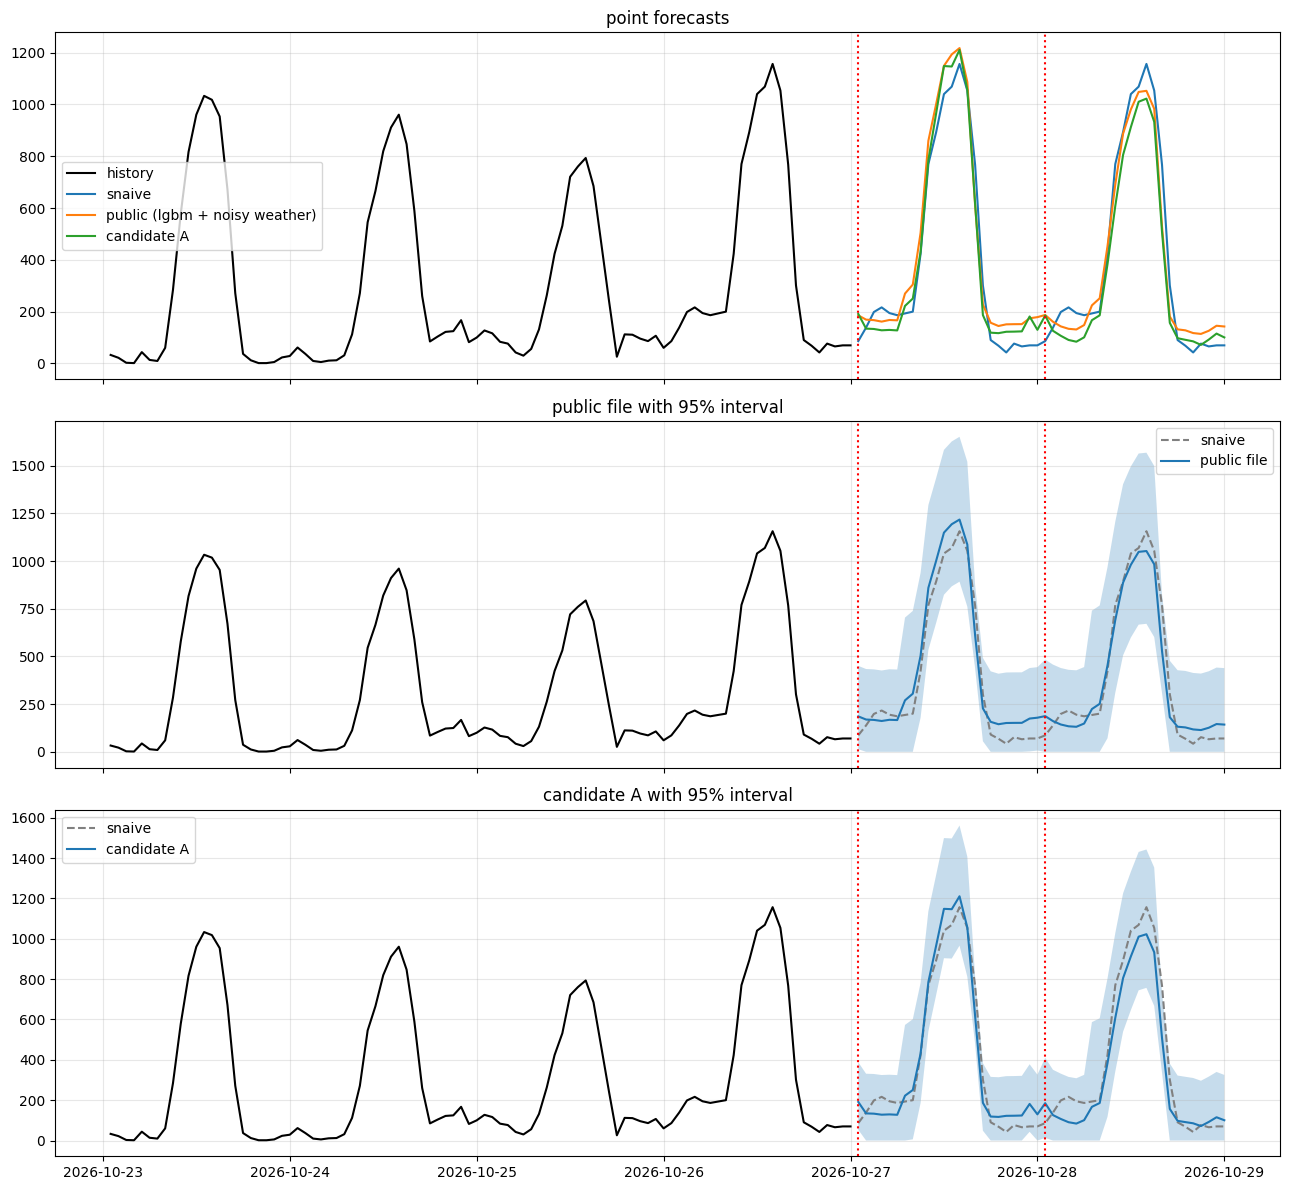

In [ ]:
# cell 16: history + forecasts of snaive, public file, candidate A (365 d window, clean weather, night x0.8)

assert k.shape == (48,) and set(np.unique(k)) == {0, 1}

fut = pd.DatetimeIndex(FUTURE)
wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(n - 1, wx_f, fut)
dl_f = wx_f[:, WI["daylight"]]
night_f = dl_f == 0

# fit candidate A: last 365 d of origins, lv7 * half-life 180 weights, 3 seeds, clean weather
mask_f = O_all >= n - 48 - 24 * 365
w_f = L_all[mask_f] * 0.5 ** ((n - O_all[mask_f]) / (24 * 180))
ms_cand = [lgb.LGBMRegressor(**BASE, random_state=s, verbose=-1)
           .fit(X2_all[mask_f], Y_all[mask_f], sample_weight=w_f) for s in (0, 1, 2)]
p_c = np.clip(np.mean([m.predict(X_f) for m in ms_cand], axis=0), 0, None) * lv_f * np.where(night_f, 0.8, 1.0)

# interval: "norm" scheme, residual quantiles by (k, daylight) from out-of-fold predictions (240 origins), widen 1.2
q_c = calib(mk(PC[0.8]))
lo_c = np.clip(p_c + np.array([q_c[(a, b)][0] for a, b in zip(k, dl_f)]) * lv_f * 1.2, 0, None)
hi_c = p_c + np.array([q_c[(a, b)][1] for a, b in zip(k, dl_f)]) * lv_f * 1.2

# snaive and public file
sn_p, sn_lo, sn_hi = [np.asarray(x, float) for x in snaive(yarr[:n])]
p_pub, lo_pub, hi_pub = pub.forecast.values, pub.lower_95.values, pub.upper_95.values

# sanity checks
for nm, (p, lo, hi) in {"cand": (p_c, lo_c, hi_c), "public": (p_pub, lo_pub, hi_pub), "snaive": (sn_p, sn_lo, sn_hi)}.items():
    print(nm, "| shape", p.shape, "| NaN", int(np.isnan(p).sum() + np.isnan(lo).sum() + np.isnan(hi).sum()),
          "| lo<=p<=hi", bool(np.all((lo <= p + 1e-9) & (p <= hi + 1e-9))), "| lo>=0", bool(np.all(lo >= 0)))

# summary table
def summ_fc(name, p, lo, hi):
    r = {"model": name}
    for nm, sl in [("d1", slice(0, 24)), ("d2", slice(24, 48))]:
        r.update({f"{nm}_mean": p[sl].mean(), f"{nm}_peak": p[sl].max(),
                  f"{nm}_night": p[sl][night_f[sl]].mean(), f"{nm}_width": (hi[sl] - lo[sl]).mean()})
    return r
print(pd.DataFrame([summ_fc("snaive", sn_p, sn_lo, sn_hi), summ_fc("public", p_pub, lo_pub, hi_pub),
                    summ_fc("candidate A", p_c, lo_c, hi_c)]).set_index("model").round(0).to_string())
print("mean |public - candidate| per hour: day 1 %.0f | day 2 %.0f" %
      (np.abs(p_pub - p_c)[:24].mean(), np.abs(p_pub - p_c)[24:].mean()))

# plot: point forecasts, then the two intervals separately
hist_ix, hist_y = idx[-96:], yarr[-96:]
fig, ax = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
ax[0].plot(hist_ix, hist_y, color="k", label="history")
ax[0].plot(fut, sn_p, label="snaive"); ax[0].plot(fut, p_pub, label="public (lgbm + noisy weather)")
ax[0].plot(fut, p_c, label="candidate A"); ax[0].set_title("point forecasts"); ax[0].legend()
for a, (nm, p, lo, hi) in zip(ax[1:], [("public file", p_pub, lo_pub, hi_pub), ("candidate A", p_c, lo_c, hi_c)]):
    a.plot(hist_ix, hist_y, color="k"); a.plot(fut, sn_p, color="gray", ls="--", label="snaive")
    a.plot(fut, p, label=nm); a.fill_between(fut, lo, hi, alpha=.25); a.set_title(nm + " with 95% interval"); a.legend()
for a in ax: a.axvline(fut[0], color="r", ls=":"); a.axvline(fut[24], color="r", ls=":")
plt.tight_layout(); plt.show()

CAND = pd.DataFrame({"ds": fut, "forecast": p_c, "lower_95": lo_c, "upper_95": hi_c})  # kept in memory only, not saved

In [ ]:
OR_ = [int(o) for o in OR]; low = sorted(low)

# sanity: all stored predictions exist for every origin, 48 values each
for nm in ["full+hl180 (current)", "365d", "180d"]:
    assert all(len(PW[nm][o]) == 48 for o in OR_), nm
assert all(len(P8["mean3"][o]) == 48 for o in OR_)

def blend(parts, w):
    # weighted average of prediction dicts keyed by origin position
    return {o: sum(wi * np.asarray(p[o]) for wi, p in zip(w, parts)) for o in OR_}

base = PW["365d"]                                  # current frozen candidate (night x0.8 already inside)
full, w180, m3 = PW["full+hl180 (current)"], PW["180d"], P8["mean3"]   # mean3 has NO night multiplier

CAND = {
    "E1 365d+full":            blend([base, full], [.5, .5]),
    "E2 365d+180d+full":       blend([base, w180, full], [1/3, 1/3, 1/3]),
    "B1 0.8*365d+0.2*mean3":   blend([base, m3], [.8, .2]),
    "B2 0.7*365d+0.3*mean3":   blend([base, m3], [.7, .3]),
}

# point and interval metrics, day 2, wide 1.2 (same protocol as before)
rows_ = []
for nm, Pn in {"365d (base)": base, **CAND}.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        rows_.append(dict(model=nm, subset=sn, **row(Pn, sub_, 1.2)))
print(pd.DataFrame(rows_).round(2).to_string(index=False))

# paired block bootstrap: base minus candidate (positive = candidate better), 95% CI
def pb(A, B, subset, wide=1.2, nb=2000, blk=7, seed=0):
    a = per_origin(A, wide).loc[subset]; b = per_origin(B, wide).loc[subset]
    rng = np.random.default_rng(seed); n_ = len(a); res = []
    for _ in range(nb):
        st_ = rng.integers(0, n_, size=n_ // blk + 1)
        ix = np.concatenate([np.arange(s, s + blk) % n_ for s in st_])[:n_]
        aa, bb = a.iloc[ix], b.iloc[ix]
        res.append([np.sqrt(aa.se.mean()) - np.sqrt(bb.se.mean()),
                    100 * (aa.ape.mean() - bb.ape.mean()), aa.w.mean() - bb.w.mean()])
    res = np.array(res); out = {}
    for j, m in enumerate(["dRMSE", "dMAPE", "dWink"]):
        lo_, hi_ = np.percentile(res[:, j], [2.5, 97.5])
        out[m] = f"{res[:, j].mean():+.1f} [{lo_:+.1f},{hi_:+.1f}]"
    return out

tab = []
for nm, Pn in CAND.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        tab.append(dict(cand=nm, subset=sn, **pb(base, Pn, sub_)))
print("\nbase minus candidate (positive = candidate better):")
print(pd.DataFrame(tab).to_string(index=False))

# level check: what each candidate would forecast now is NOT computed here (needs final fits); only validation.

                model subset   RMSE   MAPE    Wink  cov
          365d (base)    low 228.83  73.61 1085.86 0.95
          365d (base)    all 231.37  90.07 1255.27 0.97
         E1 365d+full    low 231.89  76.19 1115.03 0.94
         E1 365d+full    all 232.18  91.58 1268.22 0.97
    E2 365d+180d+full    low 230.46  78.72 1109.71 0.95
    E2 365d+180d+full    all 231.62  99.38 1260.30 0.97
B1 0.8*365d+0.2*mean3    low 227.70  73.98 1100.36 0.95
B1 0.8*365d+0.2*mean3    all 230.69  98.68 1267.08 0.97
B2 0.7*365d+0.3*mean3    low 229.08  74.61 1116.42 0.95
B2 0.7*365d+0.3*mean3    all 232.93 103.38 1274.79 0.97

base minus candidate (positive = candidate better):
                 cand subset            dRMSE              dMAPE              dWink
         E1 365d+full    low -3.0 [-7.1,+0.3]   -2.5 [-7.8,+0.5] -29.4 [-83.7,+2.2]
         E1 365d+full    all -0.8 [-2.7,+0.9]   -1.5 [-4.2,+0.2] -13.0 [-32.2,-0.6]
    E2 365d+180d+full    low -1.5 [-6.5,+3.3]  -5.0 [-13.3,-0.1] -23.9 [-77.4,+

In [ ]:
# cell 18: training-window and half-life sweep (8 blocks, noisy test weather), plus "forecast now" per variant
OR_ = [int(o) for o in OR]; low = sorted(low)
assert k.shape == (48,) and set(np.unique(k)) == {0, 1}

CFG = {                       # name: (recent days, half-life days)
    "30d hl180":   (30, 180),
    "60d hl180":   (60, 180),
    "120d hl180":  (120, 180),
    "365d hl90":   (365, 90),
    "365d hl45":   (365, 45),
}
PS = {"365d hl180 (base)": PW["365d"], "180d hl180": PW["180d"], "90d hl180": PW["90d"], "45d hl180": PW["45d"]}
for nm, (rec, hl) in CFG.items():
    PS[nm] = lgbm_cv(recent=rec, half_life=hl)      # cols=ALL, seeds=(0, 1), same noisy test weather XN
    print("done", nm)

# validation metrics, day 2, wide 1.2
rows_ = []
for nm, Pn in PS.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        rows_.append(dict(model=nm, subset=sn, **row(Pn, sub_, 1.2)))
print(pd.DataFrame(rows_).round(2).to_string(index=False))

# paired: base minus candidate (positive = candidate better)
base = PS["365d hl180 (base)"]; tab = []
for nm in list(CFG):
    for sn, sub_ in [("low", low), ("all", OR_)]:
        tab.append(dict(cand=nm, subset=sn, **pb(base, PS[nm], sub_)))
print("\nbase minus candidate (positive = candidate better):")
print(pd.DataFrame(tab).to_string(index=False))

# same sign on both halves of `low`?
half = len(low) // 2
for nm in CFG:
    a_ = row(PS[nm], low[:half], 1.2); b_ = row(PS[nm], low[half:], 1.2)
    print(f"{nm:12s} low 1st half RMSE {a_['RMSE']:.1f} Wink {a_['Wink']:.0f} | 2nd half RMSE {b_['RMSE']:.1f} Wink {b_['Wink']:.0f}")

# what each variant forecasts NOW (final-style fit up to the origin, seeds 0,1, clean weather, night x0.8)
fut = pd.DatetimeIndex(FUTURE); wx_f = weather_fc[W].to_numpy(float)
X_f, lv_f = rows2(n - 1, wx_f, fut); night_f = wx_f[:, WI["daylight"]] == 0
out = []
for nm, (rec, hl) in {"365d hl180 (base)": (365, 180), **CFG}.items():
    m_ = (O_all >= n - 48 - 24 * rec)
    w_ = L_all[m_] * 0.5 ** ((n - O_all[m_]) / (24 * hl))
    ms_ = [lgb.LGBMRegressor(**BASE, random_state=s, verbose=-1).fit(X2_all[m_], Y_all[m_], sample_weight=w_) for s in (0, 1)]
    p = np.clip(np.mean([m.predict(X_f) for m in ms_], axis=0), 0, None) * lv_f * np.where(night_f, 0.8, 1.0)
    out.append(dict(model=nm, d1_mean=p[:24].mean(), d1_peak=p[:24].max(), d1_night=p[:24][night_f[:24]].mean(),
                    d2_mean=p[24:].mean(), d2_peak=p[24:].max(), d2_night=p[24:][night_f[24:]].mean()))
print("\nforecast now:\n", pd.DataFrame(out).round(0).to_string(index=False))

done 30d hl180
done 60d hl180
done 120d hl180
done 365d hl90
done 365d hl45
            model subset   RMSE   MAPE    Wink  cov
365d hl180 (base)    low 228.83  73.61 1085.86 0.95
365d hl180 (base)    all 231.37  90.07 1255.27 0.97
       180d hl180    low 233.11  84.63 1122.32 0.95
       180d hl180    all 239.89 116.10 1269.28 0.97
        90d hl180    low 238.53  91.20 1191.30 0.94
        90d hl180    all 244.84 128.93 1317.78 0.97
        45d hl180    low 258.14  97.55 1363.85 0.93
        45d hl180    all 261.33 137.83 1434.34 0.97
        30d hl180    low 258.01 101.57 1355.30 0.94
        30d hl180    all 267.80 149.89 1429.86 0.97
        60d hl180    low 246.17  96.65 1278.42 0.94
        60d hl180    all 252.21 134.03 1382.46 0.97
       120d hl180    low 245.18  93.40 1173.13 0.94
       120d hl180    all 248.48 132.27 1329.71 0.97
        365d hl90    low 229.02  74.68 1084.18 0.95
        365d hl90    all 232.48  91.50 1256.06 0.97
        365d hl45    low 231.03  79.73 1

In [ ]:
# cell 19: night multiplier sweep 0.85 / 0.9 / 0.95 vs base 0.8 (365d, hl180, 8 blocks, noisy test weather)
OR_ = [int(o) for o in OR]; low = sorted(low)

RAW = {o: PV["A"][o] / NT[o] for o in OR_}                # predictions without the night multiplier
def with_c(c): return {o: RAW[o] * np.where(NT[o] < 1, c, 1.0) for o in OR_}
PN = {c: with_c(c) for c in [0.8, 0.85, 0.9, 0.95]}
print("repro c=0.8 vs PV['A'], max abs diff:", max(float(np.abs(PN[0.8][o] - PV["A"][o]).max()) for o in OR_))

# metrics, day 2, wide 1.2 (interval is recalibrated inside row() for each multiplier)
rows_ = []
for c, Pn in PN.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        rows_.append(dict(night_mult=c, subset=sn, **row(Pn, sub_, 1.2)))
print(pd.DataFrame(rows_).round(2).to_string(index=False))

# paired: 0.8 minus candidate (positive = candidate better)
tab = []
for c in [0.85, 0.9, 0.95]:
    for sn, sub_ in [("low", low), ("all", OR_)]:
        tab.append(dict(night_mult=c, subset=sn, **pb(PN[0.8], PN[c], sub_)))
print("\n0.8 minus candidate (positive = candidate better):")
print(pd.DataFrame(tab).to_string(index=False))

# same sign on both halves of `low`
half = len(low) // 2
for c in PN:
    a_ = row(PN[c], low[:half], 1.2); b_ = row(PN[c], low[half:], 1.2)
    print(f"c={c}: low 1st half RMSE {a_['RMSE']:.1f} MAPE {a_['MAPE']:.1f} | 2nd half RMSE {b_['RMSE']:.1f} MAPE {b_['MAPE']:.1f}")

# what the multiplier means for the forecast now (candidate A point forecast p_c already has x0.8 inside)
for c in [0.8, 0.85, 0.9, 0.95]:
    p = p_c * np.where(night_f, c / 0.8, 1.0)
    print(f"c={c}: night mean d1 {p[:24][night_f[:24]].mean():.0f} | d2 {p[24:][night_f[24:]].mean():.0f}")

repro c=0.8 vs PV['A'], max abs diff: 0.0
 night_mult subset   RMSE   MAPE    Wink  cov
       0.80    low 228.83  73.61 1085.86 0.95
       0.80    all 231.37  90.07 1255.27 0.97
       0.85    low 228.98  77.29 1087.48 0.95
       0.85    all 231.60  94.88 1254.70 0.97
       0.90    low 229.79  81.21 1088.64 0.95
       0.90    all 232.53  99.88 1254.07 0.97
       0.95    low 231.26  85.38 1091.06 0.95
       0.95    all 234.15 105.06 1253.54 0.97

0.8 minus candidate (positive = candidate better):
 night_mult subset            dRMSE              dMAPE             dWink
       0.85    low -0.1 [-1.3,+0.9]   -3.6 [-6.1,-1.6]  -1.6 [-9.2,+3.3]
       0.85    all -0.2 [-1.1,+0.7]   -4.8 [-7.9,-2.7]  +0.6 [-3.4,+3.6]
       0.90    low -1.0 [-3.4,+1.3]  -7.5 [-12.6,-3.4] -2.8 [-11.9,+4.0]
       0.90    all -1.2 [-3.0,+0.6]  -9.8 [-16.0,-5.6]  +1.3 [-5.5,+6.2]
       0.95    low -2.4 [-6.2,+1.2] -11.6 [-19.3,-5.4] -5.3 [-17.9,+4.8]
       0.95    all -2.8 [-5.6,-0.1] -15.0 [-24.2,-8.7]

## CHRONOS

In [ ]:
# cell 20b: load Chronos-2 into a separate variable, check its type and predict_df signature
import inspect, torch
from chronos import Chronos2Pipeline
device = "cuda" if torch.cuda.is_available() else "cpu"
pipe2 = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map=device)
print("type:", type(pipe2).__name__, "| device:", device)
print("predict_df ->", inspect.signature(pipe2.predict_df))

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

type: Chronos2Pipeline | device: cpu
predict_df -> (df: pandas.core.frame.DataFrame, future_df: pandas.core.frame.DataFrame | None = None, id_column: str = 'item_id', timestamp_column: str = 'timestamp', target: str | list[str] = 'target', prediction_length: int | None = None, quantile_levels: list[float] = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9], batch_size: int = 256, context_length: int | None = None, cross_learning: bool = False, validate_inputs: bool = True, freq: str | None = None, **predict_kwargs) -> pandas.core.frame.DataFrame


In [ ]:
# cell 20c: Chronos-2 smoke test on pipe2 (one origin, three configs), prints output columns and timing
import time
o = int(OR[-1])                                    # last known hour = idx[o]
fut_ix = idx[o + 1:o + 49]

def smoke2(ctx, covars):
    h_ = d.iloc[o - ctx + 1:o + 1]
    cols = ["y"] + (W if covars else [])
    c = h_[cols].reset_index().rename(columns={"ds": "timestamp", "y": "target"})
    c.insert(0, "id", "s")
    f = None
    if covars:
        f = pd.DataFrame(Warr[o + 1:o + 49], columns=W)
        f.insert(0, "timestamp", fut_ix); f.insert(0, "id", "s")
    t0 = time.time()
    out = pipe2.predict_df(c, future_df=f, prediction_length=48, quantile_levels=[0.5],
                           id_column="id", timestamp_column="timestamp", target="target")
    return out, time.time() - t0

for ctx, cv in [(336, False), (2400, False), (2400, True)]:
    try:
        out, sec = smoke2(ctx, cv)
        print(f"\nctx={ctx} covars={cv}: {sec:.1f} s | shape {out.shape} | columns {list(out.columns)}")
        print(out.head(3).to_string())
    except Exception as e:
        print(f"\nctx={ctx} covars={cv}: FAILED -> {type(e).__name__}: {e}")

print("\nfull signature:", inspect.signature(pipe2.predict_df))


ctx=336 covars=False: 4.3 s | shape (48, 5) | columns ['id', 'timestamp', 'target_name', 'predictions', '0.5']
  id           timestamp target_name  predictions     0.5
0  s 2026-10-25 01:00:00      target       92.093  92.093
1  s 2026-10-25 02:00:00      target       93.348  93.348
2  s 2026-10-25 03:00:00      target       79.337  79.337

ctx=2400 covars=False: 2.2 s | shape (48, 5) | columns ['id', 'timestamp', 'target_name', 'predictions', '0.5']
  id           timestamp target_name  predictions     0.5
0  s 2026-10-25 01:00:00      target       96.131  96.131
1  s 2026-10-25 02:00:00      target       92.706  92.706
2  s 2026-10-25 03:00:00      target       88.018  88.018

ctx=2400 covars=True: 14.5 s | shape (48, 5) | columns ['id', 'timestamp', 'target_name', 'predictions', '0.5']
  id           timestamp target_name  predictions     0.5
0  s 2026-10-25 01:00:00      target       93.376  93.376
1  s 2026-10-25 02:00:00      target       80.562  80.562
2  s 2026-10-25 03:00:00

In [ ]:
# cell 21: Chronos-2 without covariates, contexts 336/1008/2400, all 240 origins (batched), + blends, + covariate timing
import time
OR_ = [int(o) for o in OR]; low = sorted(low)

def chr2_run(ctx, origins, covars=False, chunk=30):
    out = {}
    for s in range(0, len(origins), chunk):
        part = origins[s:s + chunk]; t0 = time.time()
        ctxs, futs = [], []
        for o in part:
            cols = ["y"] + (W if covars else [])
            c = d.iloc[o - ctx + 1:o + 1][cols].reset_index().rename(columns={"ds": "timestamp", "y": "target"})
            c.insert(0, "id", str(o)); ctxs.append(c)
            if covars:   # noisy test weather, same seeded noise as for LGBM
                f = pd.DataFrame(noisy_wx_seeded(o), columns=W)
                f.insert(0, "timestamp", idx[o + 1:o + 49]); f.insert(0, "id", str(o)); futs.append(f)
        res = pipe2.predict_df(pd.concat(ctxs), future_df=pd.concat(futs) if covars else None, prediction_length=48,
                               quantile_levels=[0.5], id_column="id", timestamp_column="timestamp", target="target")
        for o in part:
            r = res[res["id"] == str(o)].sort_values("timestamp")
            assert len(r) == 48, (o, len(r))
            out[o] = np.clip(r["0.5"].to_numpy(float), 0, None)
        print(f"  ctx {ctx} cov {covars}: origins {s + 1}-{s + len(part)} done, {time.time() - t0:.0f} s")
    return out

# check that batching works and matches a single-series call for one origin
t_ = chr2_run(336, OR_[:2], chunk=2)
print("batch sanity (2 origins):", {o: np.round(v[:3], 1) for o, v in t_.items()})

PCH = {}
for ctx in (336, 1008, 2400):
    PCH[f"chr2 ctx{ctx}"] = chr2_run(ctx, OR_)

# metrics, day 2, wide 1.2
base = PS["365d hl180 (base)"]
CANDS = dict(PCH)
for nm in list(PCH):
    CANDS["0.8 base + 0.2 " + nm] = {o: 0.8 * np.asarray(base[o]) + 0.2 * PCH[nm][o] for o in OR_}
rows_ = []
for nm, Pn in {"base 365d": base, **CANDS}.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        rows_.append(dict(model=nm, subset=sn, **row(Pn, sub_, 1.2)))
print(pd.DataFrame(rows_).round(2).to_string(index=False))

tab = []
for nm, Pn in CANDS.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        tab.append(dict(cand=nm, subset=sn, **pb(base, Pn, sub_)))
print("\nbase minus candidate (positive = candidate better):")
print(pd.DataFrame(tab).to_string(index=False))

# forecast NOW (real weather forecast not needed for no-covariate variants)
now = []
nf = weather_fc.daylight.values == 0
for ctx in (336, 1008, 2400):
    c = d.iloc[n - ctx:n][["y"]].reset_index().rename(columns={"ds": "timestamp", "y": "target"}); c.insert(0, "id", "s")
    r = pipe2.predict_df(c, prediction_length=48, quantile_levels=[0.5], id_column="id",
                         timestamp_column="timestamp", target="target").sort_values("timestamp")
    p = np.clip(r["0.5"].to_numpy(float), 0, None)
    now.append(dict(model=f"chr2 ctx{ctx}", d1_mean=p[:24].mean(), d1_peak=p[:24].max(), d1_night=p[:24][nf[:24]].mean(),
                    d2_mean=p[24:].mean(), d2_peak=p[24:].max(), d2_night=p[24:][nf[24:]].mean()))
print("\nforecast now (candidate A for reference: d1 410/1213/173, d2 333/1009/134):")
print(pd.DataFrame(now).round(0).to_string(index=False))

# cost of the covariate variant: one block of 30 origins at ctx 1008
_ = chr2_run(1008, OR_[:30], covars=True, chunk=30)

  ctx 336 cov False: origins 1-2 done, 2 s
batch sanity (2 origins): {27695: array([194.9, 184.2, 178.3]), 27719: array([479.2, 447. , 426.1])}
  ctx 336 cov False: origins 1-30 done, 9 s
  ctx 336 cov False: origins 31-60 done, 7 s
  ctx 336 cov False: origins 61-90 done, 10 s
  ctx 336 cov False: origins 91-120 done, 12 s
  ctx 336 cov False: origins 121-150 done, 7 s
  ctx 336 cov False: origins 151-180 done, 8 s
  ctx 336 cov False: origins 181-210 done, 6 s
  ctx 336 cov False: origins 211-240 done, 7 s
  ctx 1008 cov False: origins 1-30 done, 15 s
  ctx 1008 cov False: origins 31-60 done, 9 s
  ctx 1008 cov False: origins 61-90 done, 9 s
  ctx 1008 cov False: origins 91-120 done, 10 s
  ctx 1008 cov False: origins 121-150 done, 9 s
  ctx 1008 cov False: origins 151-180 done, 9 s
  ctx 1008 cov False: origins 181-210 done, 10 s
  ctx 1008 cov False: origins 211-240 done, 10 s
  ctx 2400 cov False: origins 1-30 done, 23 s
  ctx 2400 cov False: origins 31-60 done, 27 s
  ctx 2400 co

In [ ]:
# cell 22: Chronos-2 blends: no-cov (mean of 3 contexts) vs with-weather (ctx 1008), weight grid, night x0.8 on Chronos part
import time
OR_ = [int(o) for o in OR]; low = sorted(low)
base = PS["365d hl180 (base)"]

# Chronos components. CH3: mean of 3 contexts, no covariates. CHW: ctx 1008 with noisy weather (about 12-15 min)
CH3 = {o: np.mean([PCH[f"chr2 ctx{c}"][o] for c in (336, 1008, 2400)], axis=0) for o in OR_}
t0 = time.time()
CHW = chr2_run(1008, OR_, covars=True)
print(f"covariate run done in {time.time() - t0:.0f} s")
COMP = {"noCov3": CH3, "cov1008": CHW}
assert all(len(v[o]) == 48 for v in COMP.values() for o in OR_)

# candidates: Chronos part gets the night multiplier NT (x0.8 at night) like the base
def night(Pc, apply): return {o: np.asarray(Pc[o]) * (NT[o] if apply else 1.0) for o in OR_}
def mix(Pc, w): return {o: (1 - w) * np.asarray(base[o]) + w * Pc[o] for o in OR_}
WG = [0.1, 0.2, 0.3, 0.4, 0.5]
CANDS = {}
for cn, Pc in COMP.items():
    for w in WG:
        CANDS[f"{cn} w{w}"] = mix(night(Pc, True), w)
CANDS["noCov3 w0.3 NO-night"] = mix(night(CH3, False), 0.3)      # control for the night multiplier
PURE = {f"{cn} alone (night x0.8)": night(Pc, True) for cn, Pc in COMP.items()}

# metrics, day 2, wide 1.2
rows_ = []
for nm, Pn in {"base 365d": base, **PURE, **CANDS}.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        rows_.append(dict(model=nm, subset=sn, **row(Pn, sub_, 1.2)))
M = pd.DataFrame(rows_)
print(M.round(2).to_string(index=False))

# paired block bootstrap on per-origin metrics, computed once per candidate
PO = {nm: per_origin(Pn, 1.2) for nm, Pn in {"base": base, **CANDS}.items()}
def bs(a_df, b_df, subset, nb=2000, blk=7, seed=0):
    a = a_df.loc[subset]; b = b_df.loc[subset]; rng = np.random.default_rng(seed); n_ = len(a); res = []
    for _ in range(nb):
        s_ = rng.integers(0, n_, size=n_ // blk + 1)
        ix = np.concatenate([np.arange(s, s + blk) % n_ for s in s_])[:n_]
        aa, bb = a.iloc[ix], b.iloc[ix]
        res.append([np.sqrt(aa.se.mean()) - np.sqrt(bb.se.mean()), 100 * (aa.ape.mean() - bb.ape.mean()), aa.w.mean() - bb.w.mean()])
    res = np.array(res)
    return res.mean(0), np.percentile(res, 2.5, axis=0), np.percentile(res, 97.5, axis=0)   # positive = candidate better

def halves_sign(nm, subset):
    h = len(subset) // 2; out = []
    for part in (subset[:h], subset[h:]):
        a, b = PO["base"].loc[part], PO[nm].loc[part]
        out.append((np.sqrt(a.se.mean()) - np.sqrt(b.se.mean()), 100 * (a.ape.mean() - b.ape.mean()), a.w.mean() - b.w.mean()))
    return out

rb = {sn: row(base, s, 1.2) for sn, s in [("low", low), ("all", OR_)]}
tab = []
for nm in CANDS:
    r = {"cand": nm}; ok_against = False; ok_for = False
    for sn, sub_ in [("low", low), ("all", OR_)]:
        m_, lo_, hi_ = bs(PO["base"], PO[nm], sub_)
        for j, k_ in enumerate(["dRMSE", "dMAPE", "dWink"]):
            r[f"{sn} {k_}"] = f"{m_[j]:+.1f} [{lo_[j]:+.1f},{hi_[j]:+.1f}]"
            ok_against |= hi_[j] < 0
            if sn == "all": ok_for |= lo_[j] > 0
        c = row(CANDS[nm], sub_, 1.2)
        r[f"{sn} composite %"] = round(100 * (0.3 * (rb[sn]["RMSE"] - c["RMSE"]) / rb[sn]["RMSE"]
                                              + 0.3 * (rb[sn]["MAPE"] - c["MAPE"]) / rb[sn]["MAPE"]
                                              + 0.4 * (rb[sn]["Wink"] - c["Wink"]) / rb[sn]["Wink"]), 2)
    hs = halves_sign(nm, low) + halves_sign(nm, OR_)
    same = all(np.sign([x[j] for x in hs[:2]]).min() == np.sign([x[j] for x in hs[:2]]).max() for j in range(3)) and \
           all(np.sign([x[j] for x in hs[2:]]).min() == np.sign([x[j] for x in hs[2:]]).max() for j in range(3))
    r["no CI against"] = not ok_against; r["some CI for (all)"] = ok_for; r["same sign in halves"] = same
    r["PASS"] = (not ok_against) and ok_for and same
    tab.append(r)
T = pd.DataFrame(tab)
pd.set_option("display.width", 250, "display.max_colwidth", 40)
print("\nbase minus candidate (positive = candidate better):")
print(T.to_string(index=False))

# forecast NOW with the real weather forecast (info only; candidate A point forecast p_c for the blend)
def chr2_now(ctx, covars):
    cols = ["y"] + (W if covars else [])
    c = d.iloc[n - ctx:n][cols].reset_index().rename(columns={"ds": "timestamp", "y": "target"}); c.insert(0, "id", "s")
    f = None
    if covars:
        f = weather_fc[W].copy(); f.insert(0, "timestamp", pd.DatetimeIndex(FUTURE)); f.insert(0, "id", "s")
    r = pipe2.predict_df(c, future_df=f, prediction_length=48, quantile_levels=[0.5], id_column="id",
                         timestamp_column="timestamp", target="target").sort_values("timestamp")
    return np.clip(r["0.5"].to_numpy(float), 0, None)
nf = weather_fc.daylight.values == 0
nm_mult = np.where(nf, 0.8, 1.0)
now3 = np.mean([chr2_now(c, False) for c in (336, 1008, 2400)], axis=0) * nm_mult
nowW = chr2_now(1008, True) * nm_mult
def srow(nm, p): return dict(model=nm, d1_mean=p[:24].mean(), d1_peak=p[:24].max(), d1_night=p[:24][nf[:24]].mean(),
                             d2_mean=p[24:].mean(), d2_peak=p[24:].max(), d2_night=p[24:][nf[24:]].mean())
print("\nforecast now:")
print(pd.DataFrame([srow("cand A (3 seeds)", p_c), srow("noCov3 (night x0.8)", now3), srow("cov1008 (night x0.8)", nowW),
                    srow("0.7 A + 0.3 noCov3", 0.7 * p_c + 0.3 * now3), srow("0.7 A + 0.3 cov1008", 0.7 * p_c + 0.3 * nowW)]
                   ).set_index("model").round(0).to_string())

  ctx 1008 cov True: origins 1-30 done, 116 s
  ctx 1008 cov True: origins 31-60 done, 92 s
  ctx 1008 cov True: origins 61-90 done, 91 s
  ctx 1008 cov True: origins 91-120 done, 93 s
  ctx 1008 cov True: origins 121-150 done, 93 s
  ctx 1008 cov True: origins 151-180 done, 92 s
  ctx 1008 cov True: origins 181-210 done, 92 s
  ctx 1008 cov True: origins 211-240 done, 93 s
covariate run done in 763 s
                     model subset   RMSE   MAPE    Wink  cov
                 base 365d    low 228.83  73.61 1085.86 0.95
                 base 365d    all 231.37  90.07 1255.27 0.97
 noCov3 alone (night x0.8)    low 267.89  88.35 1275.72 0.94
 noCov3 alone (night x0.8)    all 264.03 103.33 1468.86 0.97
cov1008 alone (night x0.8)    low 211.10  80.18  963.11 0.95
cov1008 alone (night x0.8)    all 219.05  77.02 1115.78 0.97
               noCov3 w0.1    low 226.92  73.95 1067.33 0.95
               noCov3 w0.1    all 228.82  90.58 1243.26 0.97
               noCov3 w0.2    low 226.38  74.5

In [ ]:
# ---  (w0.6 та w0.7 для Chronos cov1008) ---

NEW_WG = [0.6, 0.7]

# Додаємо нові бленди у словники CANDS та PO
for w in NEW_WG:
    nm = f"cov1008 w{w}"
    CANDS[nm] = mix(night(CHW, True), w)
    PO[nm] = per_origin(CANDS[nm], 1.2)

# Рахуємо базові метрики (Day 2, wide 1.2)
new_rows = []
for nm in [f"cov1008 w{w}" for w in NEW_WG]:
    for sn, sub_ in [("low", low), ("all", OR_)]:
        new_rows.append(dict(model=nm, subset=sn, **row(CANDS[nm], sub_, 1.2)))

print("Метрики для нових пропорцій (Day 2, wide 1.2):")
print(pd.DataFrame(new_rows).round(2).to_string(index=False))

# Рахуємо paired block bootstrap (порівняння з базовим LightGBM)
print("\nbase minus candidate (positive = candidate better):")
for nm in [f"cov1008 w{w}" for w in NEW_WG]:
    for sn, sub_ in [("low", low), ("all", OR_)]:
        m_, lo_, hi_ = bs(PO["base"], PO[nm], sub_)
        print(f"{nm} ({sn:4s}): dRMSE {m_[0]:+.1f} [{lo_[0]:+.1f},{hi_[0]:+.1f}] | dMAPE {m_[1]:+.1f} | dWink {m_[2]:+.1f}")

Метрики для нових пропорцій (Day 2, wide 1.2):
       model subset   RMSE  MAPE    Wink  cov
cov1008 w0.6    low 203.80 75.27  954.38 0.94
cov1008 w0.6    all 208.25 79.66 1105.41 0.97
cov1008 w0.7    low 203.77 76.26  950.87 0.94
cov1008 w0.7    all 208.97 78.61 1102.72 0.97

base minus candidate (positive = candidate better):
cov1008 w0.6 (low ): dRMSE +24.7 [+10.7,+39.8] | dMAPE -1.5 | dWink +131.6
cov1008 w0.6 (all ): dRMSE +23.1 [+12.4,+33.4] | dMAPE +10.4 | dWink +149.6
cov1008 w0.7 (low ): dRMSE +24.7 [+8.6,+42.2] | dMAPE -2.4 | dWink +135.3
cov1008 w0.7 (all ): dRMSE +22.3 [+10.3,+34.4] | dMAPE +11.5 | dWink +152.1


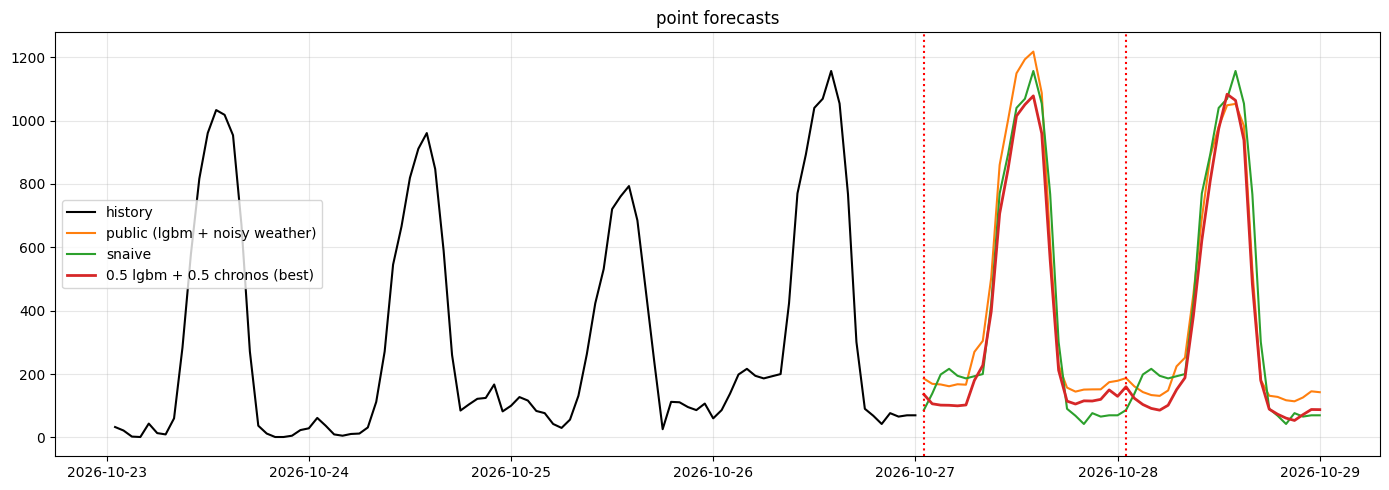

In [ ]:
# --- 2. ГРАФІК: ІСТОРІЯ + ПРОГНОЗИ ---
import matplotlib.pyplot as plt

# Формуємо прогноз бленду 0.5 (Candidate A + Chronos cov1008)
p_blend_50 = 0.5 * p_c + 0.5 * nowW

# Дані для історії (останні 96 годин)
hist_ix = idx[-96:]
hist_y = yarr[-96:]
fut = pd.DatetimeIndex(FUTURE)

fig, ax = plt.subplots(figsize=(14, 5))
ax.grid(alpha=0.3)

# 1. Історія (чорна лінія)
ax.plot(hist_ix, hist_y, color="k", label="history")

# 2. Паблік файл (помаранчева лінія)
ax.plot(fut, p_pub, color="tab:orange", label="public (lgbm + noisy weather)")

# 3. Сезонний наївний прогноз (замість Candidate A) - синя лінія
ax.plot(fut, sn_p, color="tab:green", label="snaive")

# 4. Найкращий бленд 50/50 (червона лінія, виділена товщиною)
ax.plot(fut, p_blend_50, color="tab:red", linewidth=2, label="0.5 lgbm + 0.5 chronos (best)")

ax.axvline(fut[0], color="r", ls=":")
ax.axvline(fut[24], color="r", ls=":")

ax.set_title("point forecasts")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

In [ ]:
# ---  ПОРІВНЯННЯ МЕТРИК ТА SKILL SCORE НА ВАЛІДАЦІЇ (DAY 2) ---

models_to_compare = {
    "snaive": P8["snaive"],
    "public (lgbm_nzW)": P8["lgbm_nzW"],
    "Candidate A (lgbm 365d)": PW["365d"],
    "Chronos cov1008": night(CHW, True),
    "0.5 Cand A + 0.5 Chronos": CANDS["cov1008 w0.5"],
    "0.4 Cand A + 0.6 Chronos": CANDS["cov1008 w0.6"]
}

rows_cmp = []

# 1. Зберігаємо RMSE наївного прогнозу для розрахунку Skill Score
snaive_rmse = {}
for sn, sub_ in [("low", low), ("all", OR_)]:
    snaive_rmse[sn] = row(P8["snaive"], sub_, wide=1.2)["RMSE"]

# 2. Обчислюємо метрики та Skill для кожної моделі
for nm, Pn in models_to_compare.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        metrics = row(Pn, sub_, wide=1.2)

        # Розрахунок Skill Score
        skill = metrics["RMSE"] / snaive_rmse[sn]

        rows_cmp.append(dict(
            model=nm,
            subset=sn,
            RMSE=metrics["RMSE"],
            Skill=skill,
            MAPE=metrics["MAPE"],
            Wink=metrics["Wink"],
            cov=metrics["cov"]
        ))

print("Порівняння метрик та Skill Score ключових моделей на валідації (Day 2, wide 1.2):")
cmp_df = pd.DataFrame(rows_cmp)
print(cmp_df.round(3).to_string(index=False))

Порівняння метрик та Skill Score ключових моделей на валідації (Day 2, wide 1.2):
                   model subset    RMSE  Skill    MAPE     Wink   cov
                  snaive    low 292.516  1.000 120.239 1357.324 0.951
                  snaive    all 302.313  1.000 194.074 1542.931 0.972
       public (lgbm_nzW)    low 234.311  0.801  79.302 1119.897 0.950
       public (lgbm_nzW)    all 235.420  0.779  91.161 1263.252 0.971
 Candidate A (lgbm 365d)    low 228.832  0.782  73.608 1085.856 0.948
 Candidate A (lgbm 365d)    all 231.374  0.765  90.066 1255.270 0.969
         Chronos cov1008    low 211.098  0.722  80.182  963.111 0.951
         Chronos cov1008    all 219.050  0.725  77.015 1115.782 0.974
0.5 Cand A + 0.5 Chronos    low 205.083  0.701  74.483  959.756 0.942
0.5 Cand A + 0.5 Chronos    all 208.896  0.691  80.926 1115.918 0.967
0.4 Cand A + 0.6 Chronos    low 203.802  0.697  75.268  954.382 0.940
0.4 Cand A + 0.6 Chronos    all 208.248  0.689  79.661 1105.409 0.967


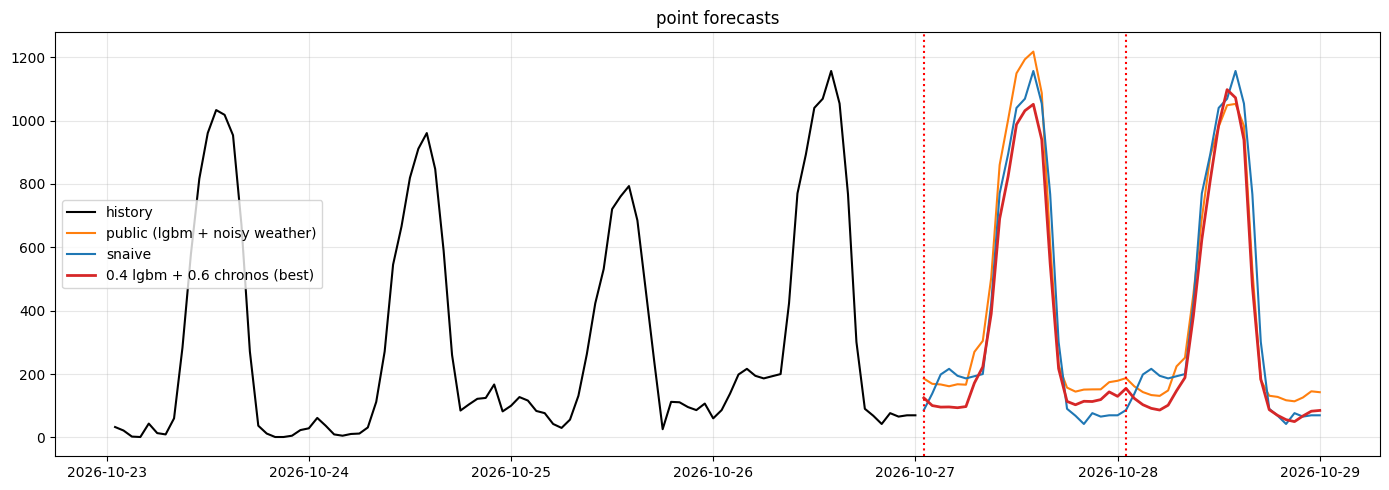

In [65]:
import matplotlib.pyplot as plt

p_blend_opt = 0.4 * p_c + 0.6 * nowW
p_blend_50 = 0.5 * p_c + 0.5 * nowW

# Дані для історії (останні 96 годин)
hist_ix = idx[-96:]
hist_y = yarr[-96:]
fut = pd.DatetimeIndex(FUTURE)

fig, ax = plt.subplots(figsize=(14, 5))
ax.grid(alpha=0.3)

# 1. Історія (чорна лінія)
ax.plot(hist_ix, hist_y, color="k", label="history")

# 2. Паблік файл (помаранчева лінія)
ax.plot(fut, p_pub, color="tab:orange", label="public (lgbm + noisy weather)")

# 3. Сезонний наївний прогноз - синя лінія
ax.plot(fut, sn_p, color="tab:blue", label="snaive")

# # 4. Бленд 50/50 (фіолетова лінія)
# ax.plot(fut, p_blend_50, color="tab:purple", linewidth=2, label="0.5 lgbm + 0.5 chronos")

# 5. Найкращий бленд 40/60 (червона лінія, виділена товщиною)
ax.plot(fut, p_blend_opt, color="tab:red", linewidth=2, label="0.4 lgbm + 0.6 chronos (best)")

ax.axvline(fut[0], color="r", ls=":")
ax.axvline(fut[24], color="r", ls=":")

ax.set_title("point forecasts")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

In [69]:
# # --- ФІНАЛЬНИЙ САБМІШН (0.4 LightGBM + 0.6 Chronos) ---

# # 1. Формуємо точковий прогноз бленду
# p_blend_opt = 0.4 * p_c + 0.6 * nowW

# # 2. Розраховуємо 95% довірчі інтервали (схема "norm", wide=1.2) навколо нового бленду
# # Передбачається, що q_c, k, dl_f та lv_f вже обчислені в попередніх комірках (cell 16)
# lo_blend = np.clip(p_blend_opt + np.array([q_c[(a, b)][0] for a, b in zip(k, dl_f)]) * lv_f * 1.2, 0, None)
# hi_blend = p_blend_opt + np.array([q_c[(a, b)][1] for a, b in zip(k, dl_f)]) * lv_f * 1.2

# # 3. Створюємо фінальний датафрейм для Kaggle/Moodle
# sub_blend = pd.DataFrame({
#     "ds": fut.strftime("%Y-%m-%d %H:%M:%S"),
#     "forecast": p_blend_opt,
#     "lower_95": lo_blend,
#     "upper_95": hi_blend
# })

# # 4. Зберігаємо у файл
# file_name = "MAZKO_project_04lgbm_06chr.csv"
# sub_blend.to_csv(file_name, index=False)

# print(f"Файл {file_name} успішно збережено!")
# print("\nПерші 10 годин прогнозу:")
# print(sub_blend.head(10).round(1).to_string(index=False))

Файл MAZKO_project_04lgbm_06chr.csv успішно збережено!

Перші 10 годин прогнозу:
                 ds  forecast  lower_95  upper_95
2026-10-27 01:00:00     124.9       0.0     321.5
2026-10-27 02:00:00     100.5       0.0     297.2
2026-10-27 03:00:00      95.8       0.0     292.4
2026-10-27 04:00:00      96.2       0.0     292.8
2026-10-27 05:00:00      93.8       0.0     290.4
2026-10-27 06:00:00      97.5       0.0     294.1
2026-10-27 07:00:00     171.6       0.0     522.2
2026-10-27 08:00:00     222.9       0.0     573.5
2026-10-27 09:00:00     390.3     145.7     741.0
2026-10-27 10:00:00     690.0     445.4    1040.7


In [70]:
# --- ПЕРЕВІРКА НОВИХ КОНТЕКСТІВ CHRONOS ---
import time

# Задаємо нові контексти для перевірки (в годинах)
new_contexts = [504, 672, 1440]

# Зберігаємо прогнози нових контекстів з погодою
for ctx in new_contexts:
    t0 = time.time()
    # chr2_run вже був визначений у вас раніше для батчевого запуску
    CH_new = chr2_run(ctx, OR_, covars=True)
    COMP[f"cov{ctx}"] = CH_new
    print(f"ctx {ctx} cov True done in {time.time() - t0:.0f} s")

# Оцінюємо їх самостійно (з нічним множником 0.8)
new_rows = []
for ctx in new_contexts:
    nm = f"cov{ctx} alone (night x0.8)"
    Pn = night(COMP[f"cov{ctx}"], True)

    for sn, sub_ in [("low", low), ("all", OR_)]:
        new_rows.append(dict(model=nm, subset=sn, **row(Pn, sub_, 1.2)))

print("\nМетрики нових контекстів Chronos (Day 2, wide 1.2):")
print(pd.DataFrame(new_rows).round(2).to_string(index=False))

# Якщо якийсь із них покаже RMSE < 211.10 на low, його варто брати у бленд замість cov1008!

  ctx 504 cov True: origins 1-30 done, 60 s
  ctx 504 cov True: origins 31-60 done, 45 s
  ctx 504 cov True: origins 61-90 done, 44 s
  ctx 504 cov True: origins 91-120 done, 44 s
  ctx 504 cov True: origins 121-150 done, 44 s
  ctx 504 cov True: origins 151-180 done, 44 s
  ctx 504 cov True: origins 181-210 done, 44 s
  ctx 504 cov True: origins 211-240 done, 45 s
ctx 504 cov True done in 371 s
  ctx 672 cov True: origins 1-30 done, 61 s
  ctx 672 cov True: origins 31-60 done, 60 s
  ctx 672 cov True: origins 61-90 done, 62 s
  ctx 672 cov True: origins 91-120 done, 61 s
  ctx 672 cov True: origins 121-150 done, 60 s
  ctx 672 cov True: origins 151-180 done, 62 s
  ctx 672 cov True: origins 181-210 done, 60 s
  ctx 672 cov True: origins 211-240 done, 60 s
ctx 672 cov True done in 485 s
  ctx 1440 cov True: origins 1-30 done, 125 s
  ctx 1440 cov True: origins 31-60 done, 123 s
  ctx 1440 cov True: origins 61-90 done, 124 s
  ctx 1440 cov True: origins 91-120 done, 124 s
  ctx 1440 cov

In [71]:
# --- ПЕРЕВІРКА БЛЕНДІВ З НОВИМ НАЙКРАЩИМ КОНТЕКСТОМ (cov1440) ---

# Зберігаємо найкращий Chronos
CH_best = COMP["cov1440"]

# Тестуємо пропорції для Chronos (від 40% до 70%)
NEW_WG = [0.4, 0.5, 0.6, 0.7]

for w in NEW_WG:
    nm = f"cov1440 w{w}"
    CANDS[nm] = mix(night(CH_best, True), w)

# Збираємо метрики для нових блендів
models_to_compare = {
    "snaive": P8["snaive"],
    "Candidate A (lgbm 365d)": PW["365d"],
    "Chronos cov1440 (alone)": night(CH_best, True),
}
for w in NEW_WG:
    models_to_compare[f"{1-w:.1f} Cand A + {w:.1f} Chronos"] = CANDS[f"cov1440 w{w}"]

rows_cmp = []
snaive_rmse = {}

# Рахуємо RMSE наївного прогнозу
for sn, sub_ in [("low", low), ("all", OR_)]:
    snaive_rmse[sn] = row(P8["snaive"], sub_, wide=1.2)["RMSE"]

# Обчислюємо метрики
for nm, Pn in models_to_compare.items():
    for sn, sub_ in [("low", low), ("all", OR_)]:
        metrics = row(Pn, sub_, wide=1.2)
        skill = metrics["RMSE"] / snaive_rmse[sn]

        rows_cmp.append(dict(
            model=nm,
            subset=sn,
            RMSE=metrics["RMSE"],
            Skill=skill,
            MAPE=metrics["MAPE"],
            Wink=metrics["Wink"],
            cov=metrics["cov"]
        ))

print("Порівняння метрик блендів з cov1440 (Day 2, wide 1.2):")
cmp_df = pd.DataFrame(rows_cmp)
print(cmp_df.round(3).to_string(index=False))

Порівняння метрик блендів з cov1440 (Day 2, wide 1.2):
                   model subset    RMSE  Skill    MAPE     Wink   cov
                  snaive    low 292.516  1.000 120.239 1357.324 0.951
                  snaive    all 302.313  1.000 194.074 1542.931 0.972
 Candidate A (lgbm 365d)    low 228.832  0.782  73.608 1085.856 0.948
 Candidate A (lgbm 365d)    all 231.374  0.765  90.066 1255.270 0.969
 Chronos cov1440 (alone)    low 210.110  0.718  73.939  939.555 0.947
 Chronos cov1440 (alone)    all 211.414  0.699  71.304 1087.442 0.972
0.6 Cand A + 0.4 Chronos    low 208.453  0.713  71.404  965.508 0.946
0.6 Cand A + 0.4 Chronos    all 209.340  0.692  80.346 1125.621 0.969
0.5 Cand A + 0.5 Chronos    low 205.904  0.704  71.337  947.321 0.943
0.5 Cand A + 0.5 Chronos    all 206.596  0.683  78.288 1107.438 0.968
0.4 Cand A + 0.6 Chronos    low 204.472  0.699  71.499  939.447 0.943
0.4 Cand A + 0.6 Chronos    all 205.074  0.678  76.426 1094.390 0.968
0.3 Cand A + 0.7 Chronos    low 204

In [72]:
import time
import pandas as pd

# 1. Запуск нових проміжних контекстів: 75 днів (1800 годин) та 90 днів (2160 годин)
new_contexts = [1800, 2160]

for ctx in new_contexts:
    t0 = time.time()
    COMP[f"cov{ctx}"] = chr2_run(ctx, OR_, covars=True)
    print(f"ctx {ctx} cov True done in {time.time() - t0:.0f} s")

# 2. Збір всіх результатів Chronos (від 14 до 100 днів) у єдину таблицю
all_contexts = [336, 504, 672, 1008, 1440, 1800, 2160, 2400]

rows_all_ctx = []

snaive_rmse = {sn: row(P8["snaive"], sub_, wide=1.2)["RMSE"] for sn, sub_ in [("low", low), ("all", OR_)]}

for ctx in all_contexts:
    Pn = None
    if f"cov{ctx}" in COMP:
        Pn = night(COMP[f"cov{ctx}"], True)
    elif ctx == 1008 and 'CHW' in globals():
        Pn = night(CHW, True)
    elif f"chr2 ctx{ctx}" in globals().get('PCH', {}):
        Pn = night({o: PCH[f"chr2 ctx{ctx}"][o] for o in OR_}, True)
    elif f"chr{ctx}" in P8:
        Pn = night(P8[f"chr{ctx}"], True)

    if Pn is not None:
        nm = f"Chronos {ctx}h ({ctx//24}d)"
        for sn, sub_ in [("low", low), ("all", OR_)]:
            metrics = row(Pn, sub_, wide=1.2)
            rows_all_ctx.append(dict(
                model=nm,
                subset=sn,
                RMSE=metrics["RMSE"],
                Skill=metrics["RMSE"] / snaive_rmse[sn],
                MAPE=metrics["MAPE"],
                Wink=metrics["Wink"],
                cov=metrics["cov"]
            ))

print("\nПорівняння всіх контекстів Chronos (від 14 до 100 днів) на Day 2, wide 1.2:")
df_all_ctx = pd.DataFrame(rows_all_ctx)
print(df_all_ctx.round(3).to_string(index=False))

  ctx 1800 cov True: origins 1-30 done, 175 s
  ctx 1800 cov True: origins 31-60 done, 155 s
  ctx 1800 cov True: origins 61-90 done, 154 s
  ctx 1800 cov True: origins 91-120 done, 154 s
  ctx 1800 cov True: origins 121-150 done, 154 s
  ctx 1800 cov True: origins 151-180 done, 154 s
  ctx 1800 cov True: origins 181-210 done, 154 s
  ctx 1800 cov True: origins 211-240 done, 154 s
ctx 1800 cov True done in 1255 s
  ctx 2160 cov True: origins 1-30 done, 186 s
  ctx 2160 cov True: origins 31-60 done, 183 s
  ctx 2160 cov True: origins 61-90 done, 183 s
  ctx 2160 cov True: origins 91-120 done, 183 s
  ctx 2160 cov True: origins 121-150 done, 184 s
  ctx 2160 cov True: origins 151-180 done, 183 s
  ctx 2160 cov True: origins 181-210 done, 183 s
  ctx 2160 cov True: origins 211-240 done, 182 s
ctx 2160 cov True done in 1469 s

Порівняння всіх контекстів Chronos (від 14 до 100 днів) на Day 2, wide 1.2:
               model subset    RMSE  Skill    MAPE     Wink   cov
  Chronos 336h (14d)   

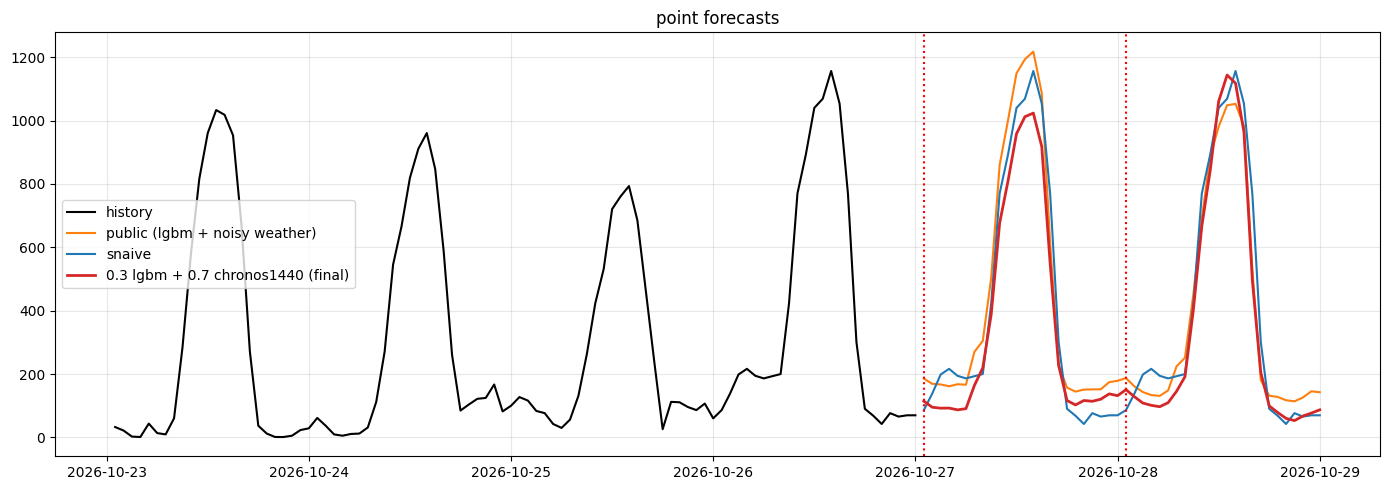

In [74]:
# --- 2. ГРАФІК: ІСТОРІЯ + ФІНАЛЬНИЙ ПРОГНОЗ ---
import matplotlib.pyplot as plt

# Дані для історії (останні 96 годин)
hist_ix = idx[-96:]
hist_y = yarr[-96:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.grid(alpha=0.3)

# 1. Історія (чорна лінія)
ax.plot(hist_ix, hist_y, color="k", label="history")

# 2. Паблік файл з першої сесії (помаранчева лінія)
ax.plot(fut, p_pub, color="tab:orange", label="public (lgbm + noisy weather)")

# 3. Сезонний наївний прогноз (синя лінія)
ax.plot(fut, sn_p, color="tab:blue", label="snaive")

# 4. Найкращий фінальний бленд 30/70 з Chronos 1440h (червона лінія, виділена товщиною)
ax.plot(fut, p_blend_final, color="tab:red", linewidth=2, label="0.3 lgbm + 0.7 chronos1440 (final)")

# Розділові вертикальні лінії для початку 1-го і 2-го днів горизонту
ax.axvline(fut[0], color="r", ls=":")
ax.axvline(fut[24], color="r", ls=":")

ax.set_title("point forecasts")
ax.legend(loc="center left")
plt.tight_layout()
plt.show()

####

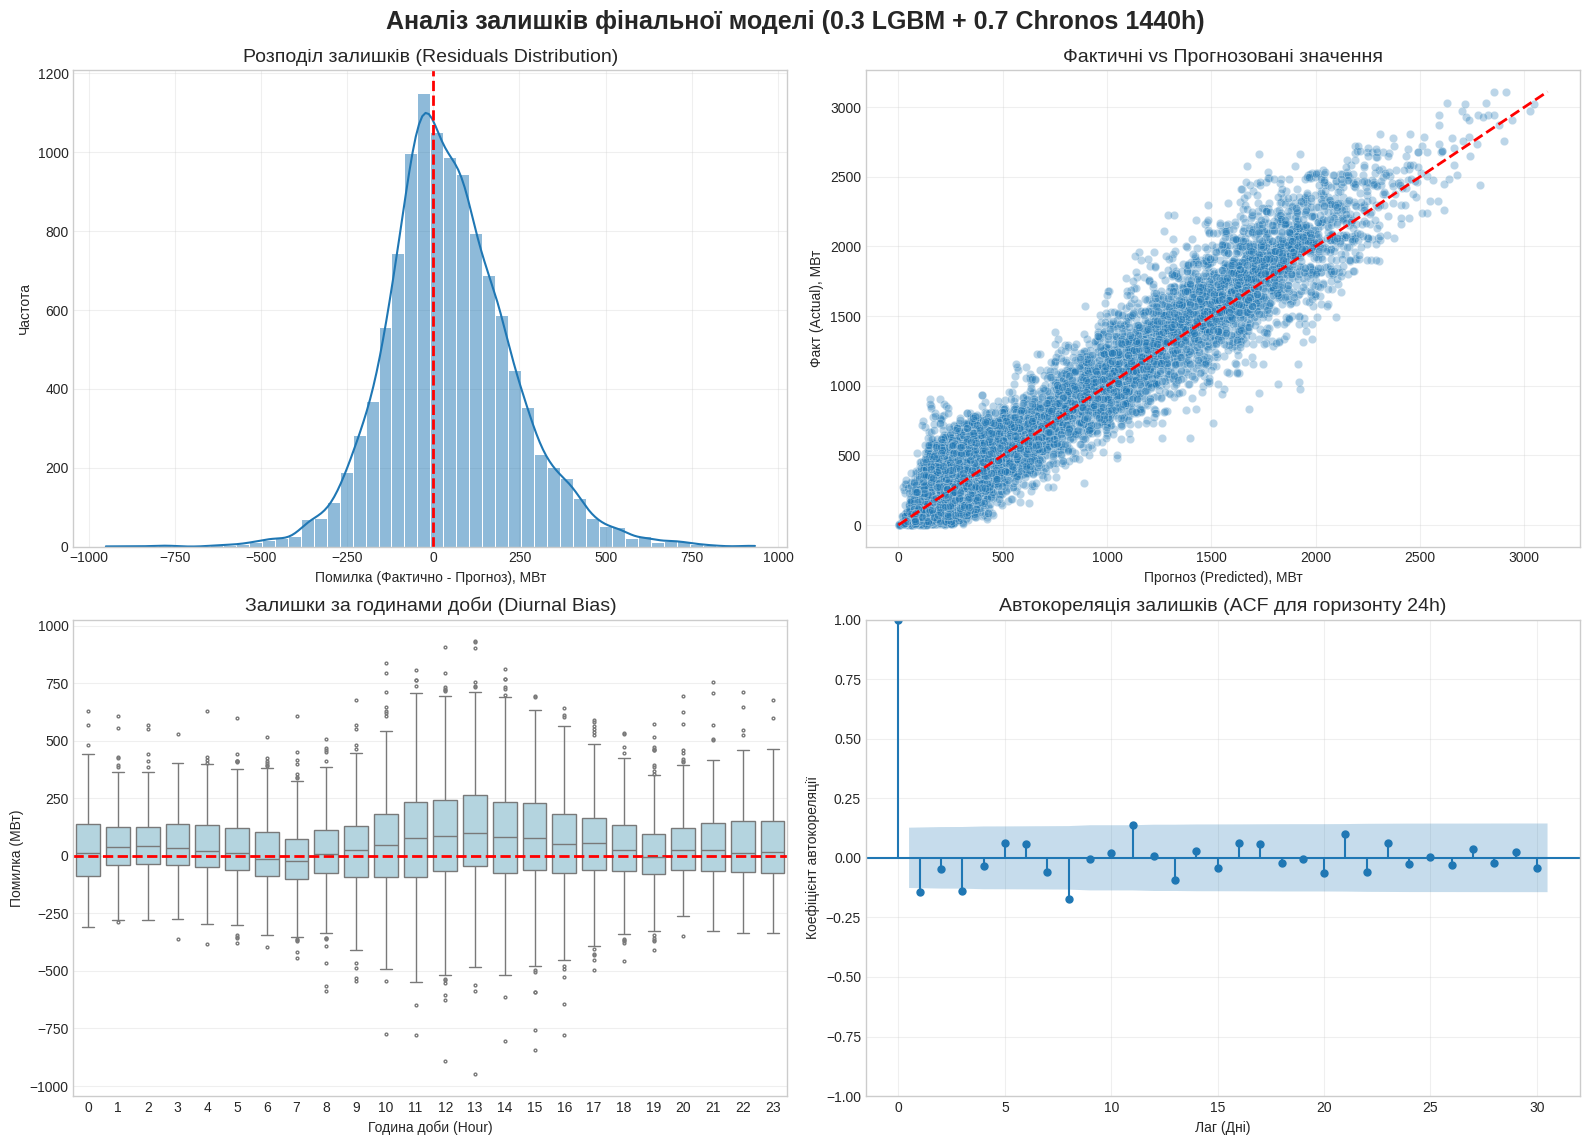

In [78]:
# --- ВІЗУАЛІЗАЦІЯ ЗАЛИШКІВ ---
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.graphics.tsaplots import plot_acf

# 1. Підготовка даних (використовуємо найкращий бленд)
Pn_final = CANDS["cov1440 w0.7"]
df_res = mk(Pn_final).copy()
df_res["res"] = df_res.y - df_res.p
# Додаємо годину доби
df_res["hour"] = [idx[int(o) + 1 + i].hour for o, i in zip(df_res.o, df_res.groupby("o").cumcount())]

plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle("Аналіз залишків фінальної моделі (0.3 LGBM + 0.7 Chronos 1440h)", fontsize=18, fontweight='bold', y=0.95)

# --- 1. Розподіл залишків (Гістограма + KDE) ---
sns.histplot(df_res["res"], bins=50, kde=True, ax=axes[0, 0], color="tab:blue", edgecolor="white")
axes[0, 0].axvline(0, color="red", linestyle="--", linewidth=2)
axes[0, 0].set_title("Розподіл залишків (Residuals Distribution)", fontsize=14)
axes[0, 0].set_xlabel("Помилка (Фактично - Прогноз), МВт")
axes[0, 0].set_ylabel("Частота")

# --- 2. Scatter plot: Фактичні vs Прогнозовані значення ---
sns.scatterplot(x="p", y="y", data=df_res, ax=axes[0, 1], alpha=0.3, color="tab:blue")
min_val = min(df_res["p"].min(), df_res["y"].min())
max_val = max(df_res["p"].max(), df_res["y"].max())
axes[0, 1].plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", linewidth=2)
axes[0, 1].set_title("Фактичні vs Прогнозовані значення", fontsize=14)
axes[0, 1].set_xlabel("Прогноз (Predicted), МВт")
axes[0, 1].set_ylabel("Факт (Actual), МВт")

# --- 3. Залишки за годинами доби (Boxplot) ---
sns.boxplot(x="hour", y="res", data=df_res, ax=axes[1, 0], color="lightblue", fliersize=2)
axes[1, 0].axhline(0, color="red", linestyle="--", linewidth=2)
axes[1, 0].set_title("Залишки за годинами доби (Diurnal Bias)", fontsize=14)
axes[1, 0].set_xlabel("Година доби (Hour)")
axes[1, 0].set_ylabel("Помилка (МВт)")

# --- 4. Автокореляція залишків (ACF) для горизонту +24 години ---

res_24h_ahead = df_res[df_res.groupby("o").cumcount() == 23]["res"]
plot_acf(res_24h_ahead.dropna(), ax=axes[1, 1], lags=30, alpha=0.05, title="")
axes[1, 1].set_title("Автокореляція залишків (ACF для горизонту 24h)", fontsize=14)
axes[1, 1].set_xlabel("Лаг (Дні)")
axes[1, 1].set_ylabel("Коефіцієнт автокореляції")

plt.tight_layout()
plt.subplots_adjust(top=0.9)
plt.show()

In [84]:
# --- 1. ФІНАЛЬНИЙ САБМІШН (ВИПРАВЛЕНІ ІНТЕРВАЛИ) ---
import numpy as np
import pandas as pd

# 1. Рахуємо квантилі залишків саме для нашого найкращого бленду!
# Беремо out-of-fold прогнози бленду 0.3 LGBM + 0.7 Chronos 1440h
q_blend = calib(mk(CANDS["cov1440 w0.7"]))

# 2. Отримуємо актуальний точковий прогноз
nowW_1440 = chr2_now(1440, True) * nm_mult
p_blend_final = 0.3 * p_c + 0.7 * nowW_1440

# 3. Розраховуємо інтервали з НОВИМИ, вужчими квантилями (q_blend замість q_c)
lo_blend = np.clip(p_blend_final + np.array([q_blend[(a, b)][0] for a, b in zip(k, dl_f)]) * lv_f * 1.2, 0, None)
hi_blend = p_blend_final + np.array([q_blend[(a, b)][1] for a, b in zip(k, dl_f)]) * lv_f * 1.2

# 4. Створюємо фінальний датафрейм
sub_blend = pd.DataFrame({
    "ds": fut.strftime("%Y-%m-%d %H:%M:%S"),
    "forecast": p_blend_final,
    "lower_95": lo_blend,
    "upper_95": hi_blend
})

# 5. Зберігаємо у файл
file_name = "MAZKO_project_final_fixed_intervals.csv"
sub_blend.to_csv(file_name, index=False)

print(f"Файл {file_name} збережено з відкаліброваними інтервалами!")

Файл MAZKO_project_final_fixed_intervals.csv збережено з відкаліброваними інтервалами!


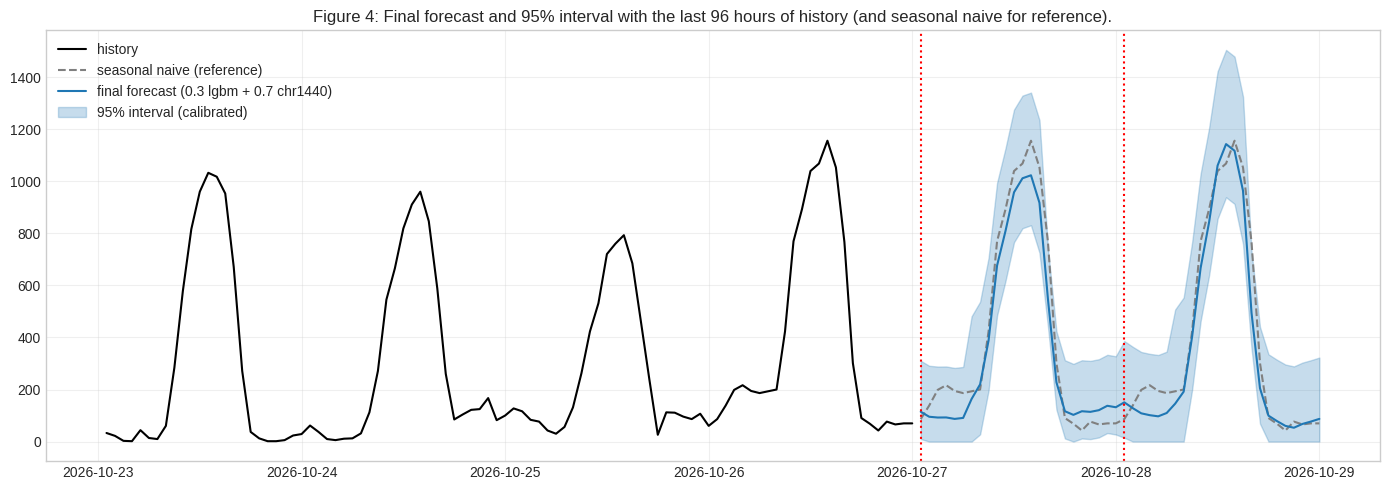

In [82]:
# --- 3. ГРАФІК: ФІНАЛЬНИЙ ПРОГНОЗ ТА ВІДКАЛІБРОВАНИЙ 95% ІНТЕРВАЛ (FIGURE 4) ---
import matplotlib.pyplot as plt

# Дані для історії (останні 96 годин)
hist_ix = idx[-96:]
hist_y = yarr[-96:]

fig, ax = plt.subplots(figsize=(14, 5))
ax.grid(alpha=0.3)

# 1. Історія (чорна суцільна лінія)
ax.plot(hist_ix, hist_y, color="k", label="history")

# 2. Сезонний наївний прогноз (сіра пунктирна лінія для референсу)
ax.plot(fut, sn_p, color="gray", ls="--", label="seasonal naive (reference)")

# 3. Фінальний точковий прогноз (синя лінія)
ax.plot(fut, p_blend_final, color="tab:blue", label="final forecast (0.3 lgbm + 0.7 chr1440)")

# 4. ВІДКАЛІБРОВАНИЙ 95% довірчий інтервал
ax.fill_between(fut, lo_blend, hi_blend, color="tab:blue", alpha=0.25, label="95% interval (calibrated)")


ax.axvline(fut[0], color="r", ls=":")
ax.axvline(fut[24], color="r", ls=":")

ax.set_title("Figure 4: Final forecast and 95% interval with the last 96 hours of history (and seasonal naive for reference).")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

In [83]:
print(sub_blend.head(10).round(1).to_string(index=False))

                 ds  forecast  lower_95  upper_95
2026-10-27 01:00:00     114.6       9.8     310.5
2026-10-27 02:00:00      95.3       0.0     291.2
2026-10-27 03:00:00      92.4       0.0     288.3
2026-10-27 04:00:00      92.7       0.0     288.6
2026-10-27 05:00:00      87.1       0.0     283.0
2026-10-27 06:00:00      90.8       0.0     286.7
2026-10-27 07:00:00     163.8       0.0     481.5
2026-10-27 08:00:00     219.7      27.7     537.4
2026-10-27 09:00:00     388.6     196.6     706.3
2026-10-27 10:00:00     676.4     484.4     994.1


## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

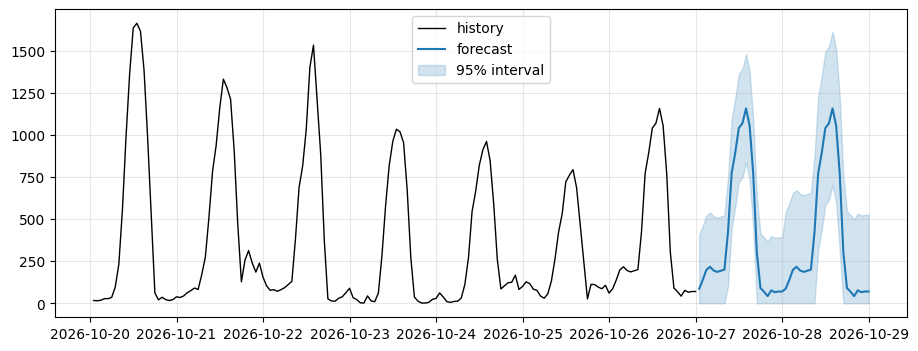

In [ ]:
# #forecast, lower_95, upper_95 = snaive(y)     # <-- replace with your model's forecast and 95% interval

# fig, ax = plt.subplots()
# ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
# ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
# ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
# ax.legend()
# plt.show()

In [ ]:
# def check_submission(sub: pd.DataFrame) -> None:
#     assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
#     assert len(sub) == H, f"need {H} rows, got {len(sub)}"
#     assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
#     assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
#     assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
#     assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
#         "the forecast must lie inside its interval"
#     print("format OK")


# submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
#                            "lower_95": lower_95, "upper_95": upper_95})
# check_submission(submission)

# FILE = f"MAZKO_final_lgbm2_noise_project.csv"
# submission.to_csv(FILE, index=False)
# print("saved", FILE)

# try:
#     from google.colab import files
#     files.download(FILE)
# except ImportError:
#     pass

format OK
saved MAZKO_final_lgbm2_noise_project.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.

In [67]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")
submission=pd.read_csv(f"MAZKO_project_04lgbm_06chr.csv")
check_submission(submission)

format OK


.